# Preliminary Analysis and Proposed Architecture for a Local Two-Voice Football Commentary System

**Project goal.** We are building an open-weight, real-time football commentary system that runs entirely on an **Apple M5 MacBook Air (24 GB, 10-core CPU and GPU)**. A fast **Lead Play-by-Play (PBP)** voice calls the live action. A **Colour Analyst** voice explains tactics, incidents and replays. Historical facts come from a **pre-kickoff match notebook**, not live web retrieval.

**What this notebook covers, end to end.**

| Part | Question | Steps |
|---|---|---|
| **A. Preliminary analysis** | What do public broadcast data and the closest published system tell us about real-time commentary? | 1–5 |
| **B. System 1 decision model** | What should make the fast, every-second decisions (when to speak, which voice), and can it run on the laptop? | 6–12 |
| **C. Proposed architecture** | What design follows from A and B, and what is each choice based on? | — |
| **D. Feasibility on the M5** | Do memory, latency and cost estimates fit? (estimates only) | — |
| **E. Experiment plan** | Which experiments would prove or break the architecture, and what do they cost? | — |
| **F. What we know and don't know** | A one-page ledger of evidence and open questions | — |

---

## Summary of findings

| # | Finding | Step | What it means for the design |
|---|---|---|---|
| 1 | LFCBI has utterance start and end times, speaker IDs and match-level splits. English commentators speak at 2.96 words/s. A typical utterance is 8 words (90th percentile 25 words, 8.97 s), and match events arrive a median 17.4 s apart. | 1 | The dataset is usable for timing and turn-taking work. Length limits should come from utterance length and time between events, not from pauses between segments. |
| 2 | The prior system's labels and retrieval are unreliable. Its human labeling pilot reached κ = 0.122, 75.6% of its retrieved Wikipedia chunks mention a year after the match, and at least 33 scraped pages describe the wrong person. | 2 | Don't train on its labels as ground truth. Replace live retrieval with a date-filtered, entity-verified notebook. |
| 3 | Match events barely predict the single-voice "background" label: AUROC 0.61 for the best causal model (0.63 only with an onset-dependent pause feature), against 0.85 for a text model reading the words. | 3 | That label describes wording, not match context, so it is a poor routing target. |
| 4 | Speaker turns are strongly structured. Within 5 s either side of a goal the colour analyst speaks 6% of utterances, rising to 91% at +15 to +30 s. Speaker role is predictable at AUROC 0.867, against 0.776 for "same speaker as before". | 4 | Route by voice first. The colour slot opens 5–15 s after a goal, which leaves time to prepare its content. |
| 5 | 98.5% of Shot → Goal pairs are ≤ 2 s apart, and 38.7% of penalties share a timestamp with the shot. Dropping off-camera players barely changes the typical player's space (median +2.4%) but distorts some frames heavily. | 5 | Make event merging event-specific, and hedge tactical claims per claim. |
| 6 | Several open "System One" decision models exist (Von, Laya, Kev, Clef and others). All read **text**, the smallest are ~0.4B encoders, and the best open one scores 0.704 against Jev's 0.966 on an independent benchmark. | 7 | Usable, but they must be fine-tuned and tested on our decisions. |
| 7 | For "who speaks in the next second", trees on 26 numeric features (no look-ahead) reach AUROC 0.733 for any onset and 0.828 for a colour onset, or 0.850 and 0.866 for **turn** onsets (a new speaker, or after ≥ 1 s of silence), on 25 held-out games. They have the lowest log-loss of all candidates. Text from recent utterances adds little to speaker prediction (+0.002 AUROC) but more to the content-type label (+0.020). | 8–11 | The every-second decision needs no language model; language helps content choices. |
| 8 | Speaker-ID errors are the most damaging noise *at the severities tested*: swapping 10% of IDs costs −0.031 colour-onset AUROC, against −0.017 for an 8 s feed delay (mean of 5 seeds; sd ≤ 0.001). | 10 | Audit the diarization before any large training run. |
| 9 | At realistic input lengths (~130–340 tokens: state plus transcript, candidate facts or a draft), a ~0.4B text decision model costs 0.70–1.18 s per call on the analysis CPU (fp32) and ~16% of CPU time at observed call rates; a ~150M model costs 0.16–0.32 s and ~3.7%. | 12 | Two tiers: a numeric model every second, and a text model only on events, sized or quantized to fit the M5 (Exp 5). |

**Proposed architecture in one sentence (Part C).** A rules-based event normaliser feeds a **two-tier System 1**: calibrated trees every second for timing and voice, plus an event-triggered open decision encoder (~0.4B, or ~150M if the laptop budget requires) for language-dependent choices. Live calls use templates; a **System 2** LLM drafts colour content in the lead time System 1 predicts; and one audio scheduler drives two CPU TTS voices.

---

## How to read this notebook

Each step follows **question → why it matters → method → code → results → design implication → caveats**. Every claim carries a tag:

| Tag | Meaning |
|---|---|
| **[OBSERVED]** | Computed by the code cell above it in this run; the number matches the printed output. |
| **[CITED]** | Taken from a named paper, file or web page. |
| **[INFERRED]** | Our interpretation, with caveats. |
| **[PLANNED] / [UNVERIFIED] / NOT COMPUTED** | An estimate, a future test, or something the available data cannot answer. |

### Which step informs which part of the system

| System component | Design question | Steps |
|---|---|---|
| Event normaliser | Which events arrive together, and how far apart? | 2C, 5A |
| System 1, every-second decisions | Is "who speaks next" predictable from numeric state? How robust and how cheap is it? | 4, 8–10, 12 |
| System 1, typed language decisions | Does language state help? What do open decision models cost? | 7, 11, 12 |
| Word budget | How fast do commentators speak, and how long are the pauses? | 1 |
| Pre-kickoff match notebook | What goes wrong with live Wikipedia retrieval? | 2B |
| Taxonomy and labels | Can existing LLM labels be trusted? | 2A, 3, 4D |
| Tactical engine and visibility gate | How much do off-camera players distort geometry? | 5B–5C |
| On-device LLM and TTS | Do memory, latency and cost fit? | Part D (estimates) |

### Data used

| Dataset | What it provides | Used in |
|---|---|---|
| LFCBI / SCBI-v2 (Mori et al., ACL 2025) | 338,023 WhisperX-transcribed broadcast utterances from 339 SoccerNet games in 8 languages, with speaker IDs, timestamps, match-level splits and a GPT-3.5 "background" label | Steps 1–4, 6, 8–11 |
| SoccerNet-v2 `Labels-v2.json` | Human event annotations (17 classes) for 500 games | Steps 1, 3–6, 8–11 |
| Mori et al. release (`soccer-bg-script`, `system-data.zip`) | Annotation pilot, prompts, Wikipedia corpus, demo outputs | Step 2 |
| PFF FIFA World Cup 2022 sample | 200 tracking frames from one match, with per-player visibility flags | Step 5 |
| SkillCorner open data sample | One A-League match (phases and dynamic events) | Step 5 (context only) |

Sources, versions and checksums are in `DATA_SOURCES.md`. **Role of Mori et al.:** we do not build on their system; we use their public data and outputs as a benchmark of failure modes to avoid.

### Limitations to keep in mind throughout
- Speaker roles come from automatic diarization plus a heuristic, not from human listening.
- `Labels-v2` timestamps are after-the-fact annotations, not a live feed.
- No public dataset has both tracking data and broadcast commentary for the same matches.
- No pretrained decision model, LLM or TTS was run. All timings come from the analysis machine printed in Setup, not the M5 target.

*Scripts:* `step0b_binary_bg_benchmark.py` reproduces Step 3, and `step0c_booth_and_mori_forensics.py` reproduces Steps 2, 4 and 5. Both write to `outputs/script_runs/`.

---
## Setup

The raw datasets are not in this repository. Place them under `data/` (paths in the next cell) or point the environment variables at them; `DATA_SOURCES.md` lists where each comes from. The cell prints `found` or `MISSING` for each input, and the machine the analysis runs on, because Steps 8 and 12 time code on that machine. Every table and figure is written to `preliminary_analysis/outputs/`.

In [1]:
# Environment & Path Setup
#
# NOTE FOR READERS: The raw datasets (LFCBI transcripts, SoccerNet-v2 match
# labels, Mori et al.'s released code/corpus, and the PFF / SkillCorner
# tracking files) are NOT included in this repository. To reproduce this
# analysis, download them from their original sources and either place them
# under `data/` as shown below, or set the corresponding environment
# variables before running the notebook.

import os, re, glob, json, urllib.parse, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.spatial import Voronoi, Delaunay
from sklearn.metrics import (
    cohen_kappa_score, f1_score, roc_auc_score,
    average_precision_score, precision_recall_curve, roc_curve
)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import linear_kernel

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
    "legend.fontsize": 8.5,
})

def _env_or(env, *candidates):
    # Use the env var if set, otherwise the first existing candidate path.
    if os.environ.get(env):
        return os.environ[env]
    for c in candidates:
        if os.path.exists(c):
            return c
    return candidates[0]

# Repository root (this notebook lives in preliminary_analysis/)
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "preliminary_analysis" else os.getcwd()
OUT_DIR = os.path.join(ROOT, "preliminary_analysis", "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

LFCBI_DIR     = _env_or("LFCBI_DIR",     os.path.join(ROOT, "data", "lfcbi", "data"))
MORI_CODE_DIR = _env_or("MORI_CODE_DIR", os.path.join(ROOT, "data", "lfcbi", "mori_code"))
SBS_DIR       = _env_or("SBS_DIR",       os.path.join(ROOT, "data", "lfcbi", "soccer-bg-script"))
SN_LABELS_DIR = _env_or("SN_LABELS_DIR", os.path.join(ROOT, "data", "soccernet_labels"))
PFF_SAMPLE    = _env_or("PFF_SAMPLE",    os.path.join(ROOT, "data", "pff", "10517.jsonl"))
SKC_POP       = _env_or("SKC_POP",       os.path.join(ROOT, "data", "skillcorner", "possessions_on_ball.csv"))
SKC_DE        = _env_or("SKC_DE",        os.path.join(ROOT, "data", "skillcorner", "dynamic_events.csv"))

for name, p in [
    ("LFCBI_DIR", LFCBI_DIR), ("MORI_CODE_DIR", MORI_CODE_DIR), ("SBS_DIR", SBS_DIR),
    ("SN_LABELS_DIR", SN_LABELS_DIR), ("PFF_SAMPLE", PFF_SAMPLE),
    ("SKC_POP", SKC_POP), ("SKC_DE", SKC_DE),
]:
    print(f"{name:<15}: {'found' if os.path.exists(p) else 'MISSING (set env var or place under data/)'}")

# Extra libraries and settings used in Part B (System 1)
import time, platform, subprocess, sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import log_loss, brier_score_loss
from scipy import sparse
cpu = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip() if platform.system() == "Darwin" else platform.processor()
print(f"\nAnalysis machine: {cpu} | {os.cpu_count()} logical CPUs | Python {platform.python_version()} | scikit-learn {sklearn.__version__}")
RNG_SEED = 0


LFCBI_DIR      : found
MORI_CODE_DIR  : found
SBS_DIR        : found
SN_LABELS_DIR  : found
PFF_SAMPLE     : found
SKC_POP        : found
SKC_DE         : found

Analysis machine: Apple M1 | 8 logical CPUs | Python 3.13.1 | scikit-learn 1.9.0


---
# Part A — Preliminary analysis: what the data says

Steps 1–5 test the assumptions the design rests on:
1. Is the dataset fit for real-time work?
2. What went wrong in the closest published system?
3. Can events predict a single-voice "background" label?
4. Does a two-voice view reveal more structure?
5. How do events collide in time, and how much does camera visibility matter?

---
## Step 1 — Is the dataset fit for real-time commentary research?

**Question.** Does a public dataset provide what a real-time commentary system needs: spoken commentary with start *and* end times, match-level train/test splits, and event annotations on the same clock?

**Why it matters.** Pause lengths and speaking rate set how many words the system can say between events. Timing alignment decides whether commentary can be related to events at all.

**Why not SoccerNet-Caption?** The common alternative, SoccerNet-Caption (Mkhallati et al., CVPRW 2023 [CITED]), is scraped from written live-text updates (about 78 per match) and has no end times. MatchTime (Rao et al., EMNLP 2024 [CITED]) found its timestamps are off by 16.63 s on average (maximum 152 s; only 26.29% within ±10 s of the action).

**What LFCBI is.** Mori et al. (ACL 2025) transcribed SoccerNet broadcast audio with WhisperX large-v3 [CITED: `football-commentary.pdf`; `soccer-bg-script/scripts/stable/build_scbi.sh`]. The paper does not name the diarization model; the `speaker` column presumably comes from WhisperX's pyannote-based diarization [INFERRED].

**Method.**
- Compute every statistic separately for all 8 languages and for English, because the two differ a lot.
- **Pause (gap)** = next utterance's start − this utterance's end. **Duration** = end − start.
- **Speaking rate**, three ways: total words ÷ total speaking time (ratio of totals); the per-utterance median for utterances ≥ 1 s; and the per-utterance median for all utterances. Very short exclamations make per-utterance rates noisy.
- **Clock alignment.** For each English `Goal` annotation, find utterances within ±30 s that contain an explicit goal phrase (*goal*, *he scores*, *scores*, *it's in*, *back of the net*, excluding *goal kick*). Replays repeat goal calls 10–30 s later, so besides the median and mean of the nearest mention we report the 2-second histogram peak.


Rows with a GPT-3.5 label other than 0/1 -> treated as 0: scbi-v2 8 {2: 6, -1: 2} | spotting splits 8 {2: 6, -1: 2}


=== 1A. LFCBI Corpus Summary by Language (Total = 338,023 Utterances, 339 Games, 678 Halves) ===


,games,halves,utterances,bg_rate,median_dur_s,median_words,median_gap_s,frac_gap_le_4s
language,,,,,,,,
es,125,249,157284,0.1725,2.14,8.0,0.060,0.8806
en,133,262,110879,0.1951,2.47,8.0,1.140,0.8119
de,60,120,44818,0.2042,2.70,6.0,0.060,0.7628
fr,19,38,20057,0.1909,2.73,8.0,0.060,0.8822
tr,2,4,2790,0.1728,1.38,5.0,0.140,0.8561
it,2,3,1463,0.1620,2.06,7.0,0.580,0.8425
pl,1,1,585,0.2632,3.00,9.0,0.060,0.9298
cy,1,1,147,0.3401,17.33,33.0,1.875,0.7397



=== 1B. Exact Scope Comparison: All 8 Languages vs. English Subset ===


,Scope,Games,Halves,Utterances,Bg_Rate_pct,Median_Dur_s,P90_Dur_s,Median_Words,Median_Gap_All_s,Median_Gap_NonOverlap_s,Gap_le_4s_All_pct,Gap_le_4s_NonOverlap_pct,WPS_RatioOfTotals,WPS_Median_DurGe1s,WPS_Median_AllDur
0,All 8 Languages (Full LFCBI),339,678,338023,18.54,2.33,7.28,8,0.18,0.18,84.22,84.22,3.12,3.33,3.51
1,English Subset Only (en),133,262,110879,19.51,2.47,8.97,8,1.14,1.14,81.19,81.19,2.96,3.32,3.38


Gap counts: All-language n = 337,345; English n = 110,617
All-language ratio-of-totals speaking rate: 3.12 words/sec (187.3 WPM)



=== 1C. Match-Level Split Summary (Cross-Split Game Overlap = 0 Games) ===


,split,all_lang_games,all_lang_utterances,all_lang_utterances_raw,en_games,en_games_with_labels_v2,en_utterances_raw,en_utterances_valid,en_bg_rate
0,train,207,208857,208861,81,81,67446,67444,0.1931
1,valid,62,60169,60171,27,27,21862,21861,0.2019
2,test,70,68989,68991,25,25,21571,21571,0.1943


English utterances with non-null target_label (valid): 110,876



=== 1D. Cross-Modal Clock Alignment Around English Goals ===
Total Goal annotations in 262 English halves : 427
Goals with >=1 explicit goal-phrase match in [-30s, +30s] : 273 / 427 (63.9%)
Total goal-phrase utterances in [-30s, +30s]              : 402
Single highest 2-second histogram bin (Mode)              : [+2s, +4s] (n = 31 utterances)
3-bin call plateau [-2s, +4s]                             : n = 91 / 402 utterances (22.6%)
Nearest goal-mention median lag                           : +3.82s (IQR = [-0.69s, +12.04s])
Plateau bin counts [-2,0) / [0,2) / [2,4)                 : 30 / 30 / 31
Goals with NO goal-phrase match in [-30s, +30s]           : 154 / 427 (36.1%)
Nearest goal-mention MEAN |lag| (matched goals only)      : 9.07s; within +/-10s: 64.8% (bounded by the +/-30s search window)
English speaking rate (ratio of totals sum(w)/sum(dur))   : 2.96 words/sec (177.3 WPM)
English speaking rate (per-utterance median, dur >= 1.0s) : 3.32 words/sec (199.3 WPM)

=== 1E. Word-budg

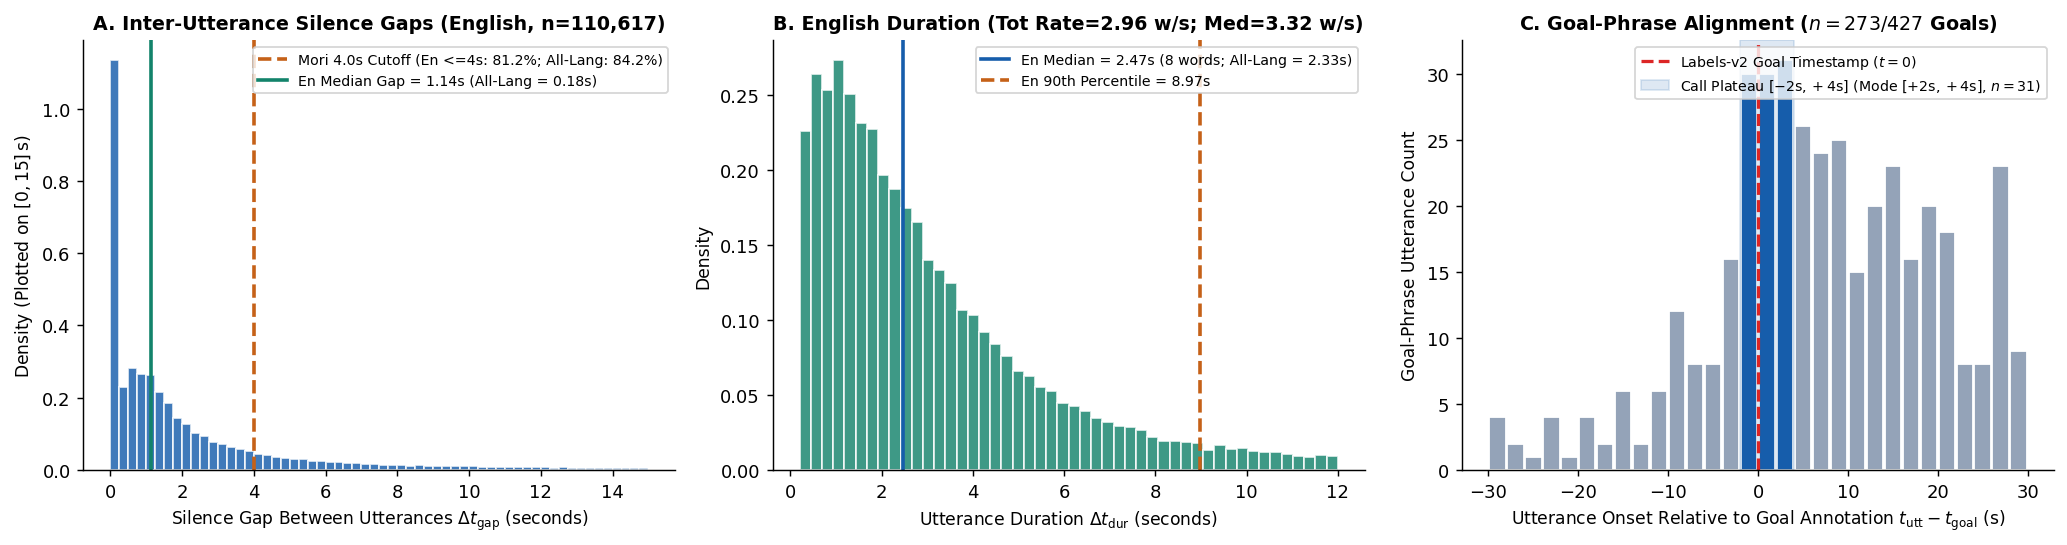

In [2]:
# STEP 1 EXECUTION: Audit LFCBI All-Language vs. English Subsets, Splits, Pacing & Clock Alignment
scbi = pd.read_csv(
    f"{LFCBI_DIR}/commentary/scbi-v2.csv",
    usecols=["id", "game", "half", "start", "end", "text", "付加的情報か", "language", "speaker", "league", "season"]
)
splits_df = pd.concat([
    pd.read_csv(f"{LFCBI_DIR}/spotting/{s}.csv", usecols=["id", "game", "half", "start", "end", "text", "language", "speaker", "付加的情報か", "target_label", "split"])
    for s in ["train", "valid", "test"]
], ignore_index=True)

# A few rows carry GPT-3.5 label values other than 0/1 (apparent parse failures). Count only 1 as "background";
# keep missing values missing so later dropna() calls are unaffected.
LBL = "付加的情報か"
bad_scbi = scbi[LBL].notna() & ~scbi[LBL].isin([0, 1])
bad_split = splits_df[LBL].notna() & ~splits_df[LBL].isin([0, 1])
print(f"Rows with a GPT-3.5 label other than 0/1 -> treated as 0: scbi-v2 {int(bad_scbi.sum())} {scbi.loc[bad_scbi, LBL].value_counts().to_dict()} | spotting splits {int(bad_split.sum())} {splits_df.loc[bad_split, LBL].value_counts().to_dict()}")
scbi[LBL] = np.where(scbi[LBL].isna(), np.nan, (scbi[LBL] == 1).astype(float))
splits_df[LBL] = np.where(splits_df[LBL].isna(), np.nan, (splits_df[LBL] == 1).astype(float))

scbi = scbi.dropna(subset=["half", "start", "end", "text"]).copy()
scbi["half"] = scbi["half"].astype(int)
scbi = scbi.sort_values(["game", "half", "start"]).reset_index(drop=True)
scbi["dur"] = scbi["end"] - scbi["start"]
scbi["gap"] = scbi.groupby(["game", "half"])["start"].shift(-1) - scbi["end"]
scbi["n_words"] = scbi["text"].str.split().str.len()
scbi["wps_raw"] = np.where(scbi["dur"] > 0, scbi["n_words"] / scbi["dur"], np.nan)

en_scbi = scbi[scbi["language"] == "en"].copy()

# 1A. Summary table by language + explicit ALL-LANGUAGE vs ENGLISH-ONLY comparison
lang_summary = scbi.groupby("language").agg(
    games=("game", "nunique"),
    halves=("half", lambda s: len(set(zip(scbi.loc[s.index, "game"], s)))),
    utterances=("id", "size"),
    bg_rate=("付加的情報か", "mean"),
    median_dur_s=("dur", "median"),
    median_words=("n_words", "median"),
    median_gap_s=("gap", lambda s: s.dropna().median()),
    frac_gap_le_4s=("gap", lambda s: (s.dropna() <= 4.0).mean()),
).sort_values("utterances", ascending=False).round(4)

print(f"=== 1A. LFCBI Corpus Summary by Language (Total = {len(scbi):,} Utterances, {scbi['game'].nunique()} Games, {scbi.groupby(['game','half']).ngroups} Halves) ===")
display(lang_summary)

# Explicit Scope Comparison Table: All 8 Languages vs. English Subset
def summarize_scope(df_sub, scope_name):
    g_all = df_sub["gap"].dropna()
    g_pos = g_all[g_all >= 0]
    dur_ge1 = df_sub[df_sub["dur"] >= 1.0]
    return {
        "Scope": scope_name,
        "Games": int(df_sub["game"].nunique()),
        "Halves": int(df_sub.groupby(["game", "half"]).ngroups),
        "Utterances": int(len(df_sub)),
        "Bg_Rate_pct": round(float(df_sub["付加的情報か"].mean() * 100), 2),
        "Median_Dur_s": round(float(df_sub["dur"].median()), 2),
        "P90_Dur_s": round(float(df_sub["dur"].quantile(0.90)), 2),
        "Median_Words": int(df_sub["n_words"].median()),
        "Median_Gap_All_s": round(float(g_all.median()), 2),
        "Median_Gap_NonOverlap_s": round(float(g_pos.median()), 2),
        "Gap_le_4s_All_pct": round(float((g_all <= 4.0).mean() * 100), 2),
        "Gap_le_4s_NonOverlap_pct": round(float((g_pos <= 4.0).mean() * 100), 2),
        "WPS_RatioOfTotals": round(float(df_sub["n_words"].sum() / df_sub["dur"].sum()), 2),
        "WPS_Median_DurGe1s": round(float(dur_ge1["wps_raw"].median()), 2),
        "WPS_Median_AllDur": round(float(df_sub["wps_raw"].median()), 2),
    }

scope_comp_df = pd.DataFrame([
    summarize_scope(scbi, "All 8 Languages (Full LFCBI)"),
    summarize_scope(en_scbi, "English Subset Only (en)"),
])
print("\n=== 1B. Exact Scope Comparison: All 8 Languages vs. English Subset ===")
display(scope_comp_df)
print(f"Gap counts: All-language n = {int(scbi['gap'].notna().sum()):,}; English n = {int(en_scbi['gap'].notna().sum()):,}")
print(f"All-language ratio-of-totals speaking rate: {scbi['n_words'].sum() / scbi['dur'].sum():.2f} words/sec ({scbi['n_words'].sum() / scbi['dur'].sum() * 60:.1f} WPM)")

# 1C. Match-level split counts (All Languages vs. English Subset) & SoccerNet Labels-v2 join check
all_splits_clean = splits_df.dropna(subset=["half", "start", "end", "target_label", "text"]).copy()
en_splits_raw = splits_df[splits_df["language"] == "en"].copy()
en_splits = all_splits_clean[all_splits_clean["language"] == "en"].copy()
en_splits["has_labels_v2"] = en_splits["game"].apply(lambda g: os.path.exists(f"{SN_LABELS_DIR}/{g}/Labels-v2.json"))

split_rows = []
for s in ["train", "valid", "test"]:
    sub_all = all_splits_clean[all_splits_clean["split"] == s]
    sub_en_raw = en_splits_raw[en_splits_raw["split"] == s]
    sub_en = en_splits[en_splits["split"] == s]
    split_rows.append({
        "split": s,
        "all_lang_games": int(sub_all["game"].nunique()),
        "all_lang_utterances": int(len(sub_all)),
        "all_lang_utterances_raw": int((splits_df["split"] == s).sum()),
        "en_games": int(sub_en["game"].nunique()),
        "en_games_with_labels_v2": int(sub_en.groupby("game")["has_labels_v2"].first().sum()),
        "en_utterances_raw": int(len(sub_en_raw)),
        "en_utterances_valid": int(len(sub_en)),
        "en_bg_rate": round(float((sub_en["target_label"] == 2.0).mean()), 4),
    })
split_summary = pd.DataFrame(split_rows)
# Verify zero game overlap across splits
train_g, valid_g, test_g = [set(all_splits_clean[all_splits_clean["split"] == s]["game"].unique()) for s in ["train", "valid", "test"]]
overlap_games = len((train_g & valid_g) | (train_g & test_g) | (valid_g & test_g))

print(f"\n=== 1C. Match-Level Split Summary (Cross-Split Game Overlap = {overlap_games} Games) ===")
display(split_summary)
print(f"English utterances with non-null target_label (valid): {int(split_summary['en_utterances_valid'].sum()):,}")

# 1D. Cross-modal clock alignment check: Goal events vs. Goal-vocabulary utterances in English games
goal_pat = re.compile(r"\b(?:goa+l|he scores|scores|it's in|back of the net)\b(?! kick)", re.I)
all_goal_lags, nearest_goal_lags = [], []
inter_event_gaps = []   # seconds between consecutive Labels-v2 events in the same English half
total_en_goals = 0

for (g, h), u in en_scbi.groupby(["game", "half"]):
    lp = f"{SN_LABELS_DIR}/{g}/Labels-v2.json"
    if not os.path.exists(lp):
        continue
    ann = json.load(open(lp))["annotations"]
    goal_times = [int(a["position"]) / 1000.0 for a in ann if a["label"] == "Goal" and int(a["gameTime"].split(" - ")[0]) == h]
    ev_times_h = np.sort([int(a["position"]) / 1000.0 for a in ann if int(a["gameTime"].split(" - ")[0]) == h])
    inter_event_gaps.extend(np.diff(ev_times_h).tolist())
    total_en_goals += len(goal_times)
    gu = u[u["text"].fillna("").str.contains(goal_pat)]
    for t0 in goal_times:
        cand = gu[(gu["start"] >= t0 - 30) & (gu["start"] <= t0 + 30)]["start"] - t0
        all_goal_lags.extend(cand.tolist())
        if len(cand):
            nearest_goal_lags.append(float(cand.iloc[cand.abs().argmin()]))

all_goal_lags = np.array(all_goal_lags)
nearest_goal_lags = np.array(nearest_goal_lags)
hist_counts, hist_edges = np.histogram(all_goal_lags, bins=np.arange(-30, 32, 2))
peak_idx = int(hist_counts.argmax())
peak_bin_lo, peak_bin_hi = float(hist_edges[peak_idx]), float(hist_edges[peak_idx + 1])
peak_bin_count = int(hist_counts[peak_idx])
plateau_mask = (hist_edges[:-1] >= -2) & (hist_edges[1:] <= 4)
plateau_count = int(hist_counts[plateau_mask].sum())

med_near = float(np.median(nearest_goal_lags))
iqr_lo, iqr_hi = float(np.percentile(nearest_goal_lags, 25)), float(np.percentile(nearest_goal_lags, 75))
en_wps_tot = float(en_scbi["n_words"].sum() / en_scbi["dur"].sum())
en_wps_med1s = float(en_scbi[en_scbi["dur"] >= 1.0]["wps_raw"].median())
en_med_dur = float(en_scbi["dur"].median())
en_p90_dur = float(en_scbi["dur"].quantile(0.90))
en_med_words = int(en_scbi["n_words"].median())
en_gaps_clean = en_scbi["gap"].dropna()
en_gaps_pos = en_gaps_clean[en_gaps_clean >= 0]

print(f"\n=== 1D. Cross-Modal Clock Alignment Around English Goals ===")
print(f"Total Goal annotations in {en_scbi.groupby(['game','half']).ngroups} English halves : {total_en_goals}")
print(f"Goals with >=1 explicit goal-phrase match in [-30s, +30s] : {len(nearest_goal_lags)} / {total_en_goals} ({len(nearest_goal_lags)/total_en_goals:.1%})")
print(f"Total goal-phrase utterances in [-30s, +30s]              : {len(all_goal_lags)}")
print(f"Single highest 2-second histogram bin (Mode)              : [{peak_bin_lo:+.0f}s, {peak_bin_hi:+.0f}s] (n = {peak_bin_count} utterances)")
print(f"3-bin call plateau [-2s, +4s]                             : n = {plateau_count} / {len(all_goal_lags)} utterances ({plateau_count/len(all_goal_lags):.1%})")
print(f"Nearest goal-mention median lag                           : {med_near:+.2f}s (IQR = [{iqr_lo:+.2f}s, {iqr_hi:+.2f}s])")
print(f"Plateau bin counts [-2,0) / [0,2) / [2,4)                 : {' / '.join(str(int(c)) for c in hist_counts[plateau_mask])}")
print(f"Goals with NO goal-phrase match in [-30s, +30s]           : {total_en_goals - len(nearest_goal_lags)} / {total_en_goals} ({1 - len(nearest_goal_lags)/total_en_goals:.1%})")
print(f"Nearest goal-mention MEAN |lag| (matched goals only)      : {np.abs(nearest_goal_lags).mean():.2f}s; within +/-10s: {(np.abs(nearest_goal_lags) <= 10).mean():.1%} (bounded by the +/-30s search window)")
print(f"English speaking rate (ratio of totals sum(w)/sum(dur))   : {en_wps_tot:.2f} words/sec ({en_wps_tot*60:.1f} WPM)")
print(f"English speaking rate (per-utterance median, dur >= 1.0s) : {en_wps_med1s:.2f} words/sec ({en_wps_med1s*60:.1f} WPM)")

# 1E. What can bound an utterance's length? (input for the word budget)
iei = np.array(inter_event_gaps)
print(f"\n=== 1E. Word-budget inputs (English) ===")
print(f"Utterance length: median {en_scbi['n_words'].median():.0f} words (90th pct {en_scbi['n_words'].quantile(0.90):.0f}); median {en_med_dur:.2f} s (90th pct {en_p90_dur:.2f} s)")
print(f"Time between consecutive Labels-v2 events (n = {len(iei):,}): median {np.median(iei):.1f} s, IQR [{np.percentile(iei, 25):.1f}, {np.percentile(iei, 75):.1f}] s")
print(f"Budget if bounded by the median PAUSE   : floor({en_gaps_clean.median():.2f} s x {en_wps_tot:.2f} w/s) = {int(np.floor(en_gaps_clean.median() * en_wps_tot))} words  <- pauses separate diarized segments; they do not bound talk")
print(f"Budget if bounded by the median INTER-EVENT time: floor({np.median(iei):.1f} s x {en_wps_tot:.2f} w/s) = {int(np.floor(np.median(iei) * en_wps_tot))} words")
print(f"Budget implied by the 90th-pct utterance duration: floor({en_p90_dur:.2f} s x {en_wps_tot:.2f} w/s) = {int(np.floor(en_p90_dur * en_wps_tot))} words")

# Visualization 1: 3-Panel Overview of Pacing, Duration & Clock Alignment (All labels dynamically interpolated)
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.3))

# Panel A: Inter-utterance silence gap distribution (English)
gaps_clipped = en_gaps_clean[(en_gaps_clean >= 0) & (en_gaps_clean <= 15)]
axes[0].hist(gaps_clipped, bins=60, color="#165DAB", alpha=0.82, edgecolor="white", density=True)
axes[0].axvline(
    4.0, color="#C56118", linestyle="--", linewidth=2,
    label=f"Mori 4.0s Cutoff (En <=4s: {(en_gaps_clean <= 4.0).mean():.1%}; All-Lang: {(scbi['gap'].dropna() <= 4.0).mean():.1%})"
)
axes[0].axvline(
    en_gaps_clean.median(), color="#13836B", linestyle="-", linewidth=2,
    label=f"En Median Gap = {en_gaps_clean.median():.2f}s (All-Lang = {scbi['gap'].dropna().median():.2f}s)"
)
axes[0].set_title(f"A. Inter-Utterance Silence Gaps (English, n={len(en_gaps_clean):,})")
axes[0].set_xlabel("Silence Gap Between Utterances $\\Delta t_{\\mathrm{gap}}$ (seconds)")
axes[0].set_ylabel("Density (Plotted on $[0, 15]\\,\\mathrm{s}$)")
axes[0].legend(loc="upper right", fontsize=7.8)

# Panel B: Utterance duration distribution (English)
durs_clipped = en_scbi[(en_scbi["dur"] > 0.2) & (en_scbi["dur"] <= 12)]["dur"]
axes[1].hist(durs_clipped, bins=48, color="#13836B", alpha=0.82, edgecolor="white", density=True)
axes[1].axvline(
    en_med_dur, color="#165DAB", linestyle="-", linewidth=2,
    label=f"En Median = {en_med_dur:.2f}s ({en_med_words} words; All-Lang = {scbi['dur'].median():.2f}s)"
)
axes[1].axvline(
    en_p90_dur, color="#C56118", linestyle="--", linewidth=2,
    label=f"En 90th Percentile = {en_p90_dur:.2f}s"
)
axes[1].set_title(f"B. English Duration (Tot Rate={en_wps_tot:.2f} w/s; Med={en_wps_med1s:.2f} w/s)")
axes[1].set_xlabel("Utterance Duration $\\Delta t_{\\mathrm{dur}}$ (seconds)")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=7.8)

# Panel C: Goal-call lag histogram
bin_centers = 0.5 * (hist_edges[:-1] + hist_edges[1:])
bar_colors = ["#165DAB" if -2 <= hist_edges[i] and hist_edges[i+1] <= 4 else "#94A3B8" for i in range(len(hist_counts))]
axes[2].bar(bin_centers, hist_counts, width=1.85, color=bar_colors, edgecolor="white")
axes[2].axvline(0, color="#DC2626", linestyle="--", linewidth=1.8, label="Labels-v2 Goal Timestamp ($t=0$)")
axes[2].axvspan(
    -2, 4, color="#165DAB", alpha=0.14,
    label=f"Call Plateau $[-2\\mathrm{{s}}, +4\\mathrm{{s}}]$ (Mode $[{peak_bin_lo:+.0f}\\mathrm{{s}}, {peak_bin_hi:+.0f}\\mathrm{{s}}]$, $n={peak_bin_count}$)"
)
axes[2].set_title(f"C. Goal-Phrase Alignment ($n={len(nearest_goal_lags)}/{total_en_goals}$ Goals)")
axes[2].set_xlabel("Utterance Onset Relative to Goal Annotation $t_{\\mathrm{utt}} - t_{\\mathrm{goal}}$ (s)")
axes[2].set_ylabel("Goal-Phrase Utterance Count")
axes[2].legend(loc="upper right", fontsize=7.8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_step1_corpus_and_alignment.png", bbox_inches="tight")
plt.show()


### Results [OBSERVED]

**Scale and splits.**

| | All 8 languages | English |
|---|---|---|
| Utterances | 338,023 | 110,879 |
| Games (halves) | 339 (678) | 133 (262) |
| Train / valid / test games | 207 / 62 / 70 | 81 / 27 / 25 |
| Games shared across splits | 0 | 0 |
| GPT-3.5 "background" rate | 18.54% | 19.51% (test split: 19.43%) |
| Games joined to `Labels-v2` | — | 133 / 133 |

Labeled utterances per split, all languages: 208,857 / 60,169 / 68,989 (raw rows: 208,861 / 60,171 / 68,991). English: 67,444 / 21,861 / 21,571 labeled (110,876 in total).

Eight rows in `scbi-v2.csv` (and eight in the split files) carry GPT-3.5 label values other than 0/1 (six 2s and two −1s). We count only 1 as background; no rate above changes at the reported precision.

**Pacing.**

| | All 8 languages | English |
|---|---|---|
| Median pause between utterances | 0.18 s (n = 337,345) | 1.14 s (n = 110,617) |
| Pauses ≤ 4 s | 84.22% | 81.19% |
| Median utterance duration (90th percentile) | 2.33 s (7.28 s) | 2.47 s (8.97 s) |
| Median words per utterance | 8 | 8 |
| Speaking rate, ratio of totals | 3.12 words/s (187.3 WPM) | 2.96 words/s (177.3 WPM) |
| Speaking rate, median of utterances ≥ 1 s | 3.33 words/s | 3.32 words/s (199.3 WPM) |

Spanish, German and French have a median pause of just 0.06 s, which is why the all-language median is much lower than the English one.

**Goal-call alignment (English).**
- Of 427 goals, 273 (63.9%) have at least one goal phrase within ±30 s (402 matching utterances). The other 154 (36.1%) have none, for example when the goal is called only by shouting a player's name.
- Goal phrases form a flat plateau from −2 s to +4 s: 30, 30 and 31 utterances in the three 2-second bins (peak bin +2 to +4 s), 91 of 402 (22.6%) in total.
- Nearest mention per goal: median +3.82 s (IQR −0.69 to +12.04 s), mean absolute lag 9.07 s, 64.8% within ±10 s. Replay mentions pull these values to the right.

**What can bound an utterance's length (1E).**

| Basis | Value | Implied budget at 2.96 words/s |
|---|---|---|
| Median pause between segments | 1.14 s | 3 words: unusable, because pauses separate diarized segments and do not bound talk |
| Median time between consecutive match events | 17.4 s (IQR 7.8–32.6 s, n = 28,231) | 51 words |
| 90th-percentile utterance duration | 8.97 s | 26 words (the 90th-percentile utterance is 25 words) |

### Design implications [INFERRED]
1. **LFCBI is usable** for timing and turn-taking work: it has end times, speaker IDs and clean match-level splits, and it joins to event annotations.
2. **Word budget.** Pauses can't set the budget: the median pause gives 3 words, yet real utterances are a median 8 words, because pauses separate diarized segments rather than ending turns. Bound each utterance instead by (a) the time until the next event is likely, $W = \lfloor r \cdot \hat{T}_{\text{next event}} \rfloor$ (median 17.4 s, so ~51 words, but often much less), and (b) a length cap near the human 90th percentile (~25 words). For $r$, use the *TTS voice's* measured rate (Exp 5), with 2.96 words/s as the human reference.
3. **Use English statistics** for an English system. Pooled statistics are dominated by Spanish broadcasts, whose pauses are much shorter.

### Caveats
- The ±30 s nearest-mention check is a different metric from MatchTime's 16.63 s offset, so the two numbers should not be compared directly.
- A lexical goal-phrase match misses goals called only with a player's name.
- `Labels-v2` timestamps mark when the action happens in the video, not when a live data feed would report it.

---
## Step 2 — What went wrong in the closest published system?

**Background.** Mori et al. (ACL 2025 System Demonstrations [CITED: `football-commentary.pdf`]) built a single-voice system with four parts. It (1) labels each utterance as play-by-play (0) or background information (1) with `gpt-3.5-turbo-1106`, (2) triggers background comments with a timing rule, (3) retrieves facts from Wikipedia, and (4) generates the commentary. Their reported results [CITED: Tables 2–3, Sec 4.3]:
- Background-timing F1 of 22.93% with gold utterance timing (P 19.87%, R 27.08%) and 22.67% with predicted timing.
- Human-rated relevance of 1.73 / 3, rising to 2.05 with gold players and 2.55 with gold players plus gold documents.
- 355 s of offline preprocessing plus 27 s of online latency per 30-second clip.

**Questions.** We inspect their released files to answer four:
1. Why did their 100-utterance human labeling pilot reach only κ = 0.122?
2. Do the human annotators agree with the GPT-3.5 labels used to build the dataset?
3. How much post-match and wrong-person content does their Wikipedia corpus feed into prompts?
4. What causes the errors in their demo clips?

**Why it matters.** Steps 3–4 use the GPT-3.5 label, and our design replaces their retrieval with a pre-kickoff notebook. Both choices need evidence.

**Method.**
- **Cohen's κ** corrects agreement for chance: $\kappa = (p_o - p_e)/(1 - p_e)$. Landis & Koch (1977) [CITED] call 0.00–0.20 "slight" and 0.61–0.80 "substantial" agreement. Krippendorff (2004) [CITED] recommends α ≥ 0.80, or ≥ 0.667 for tentative conclusions.
- **Annotators vs GPT-3.5.** Join the pilot comments to the released GPT-3.5 labels on exact game and text.
- **Retrieval simulation.** Following `addinfo_retrieval.py` and `construct_query.py`, retrieve the top-10 TF-IDF chunks for all 25 demo clips and count those mentioning a year later than the match. The query combines the match, the players in frame within ±2 s and up to 256 characters of preceding commentary. We split documents into fixed 1,000-character windows with 100-character overlap. Mori et al. use LangChain's `RecursiveCharacterTextSplitter` with the same sizes (printed in 2B), so our chunk boundaries and counts are an approximation.
- **Wrong-person pages.** Flag page titles that name another sport, or a birth year outside 1970–2000 (implausible for players in 2014–2017 matches).


Row-by-row check passed: both files list the same 100 (game, comment) items in the same order
=== 2A. Inter-Annotator Agreement on Mori et al.'s 100-Utterance Binary Pilot ===
Annotator 1 (haruki) Positive Rate : 64.0% (64/100)
Annotator 2 (sakou)  Positive Rate : 13.0% (13/100)
GPT-3.5-turbo-1106   Positive Rate : 18.54% (All-Lang, n=338,023) | 19.51% (English, n=110,879)
2x2 Contingency Table              : (H=0,S=0)=35, (H=1,S=1)=12, (H=1,S=0)=52, (H=0,S=1)=1
Total Disagreements                : 53/100 (52/53 are Haruki=1, Sakou=0; 1/53 is Haruki=0, Sakou=1)
Raw Agreement (p_o)                : 47.0% | Cohen's Kappa (κ) = 0.122


Pilot items matched verbatim to scbi-v2.csv : 12/100 (GPT-3.5 pos rate = 0.0%; raw agree: Haruki=25.0%, Sakou=91.7%; kappa undefined: GPT-3.5 has a single class on these items)


Pilot items matched verbatim to v1 500game_1_llm_annotation.csv : 20/100 (English pre-resegmentation subset; GPT-3.5 pos rate = 15.0%)
  On those 20 v1-matched items: kappa(haruki, GPT) = 0.100 (raw agree = 55.0%) | kappa(sakou, GPT) = 0.773 (raw agree = 95.0%)
  Full 100-item kappa vs GPT-3.5 : NOT COMPUTED (the 2023 pilot source CSV `gpt-3.5-turbo-1106_42_1_llm_annotation-20231217.csv` is not in the public release)

Random Sample (n=8, random_state=42) of the 53 Disagreements (showing Haruki's Japanese notes):


,row_idx,comment,haruki_label,sakou_label,haruki_note
36,36,Great switch from Alonso.,1,0,具体的動作の説明
87,87,He's caught the ball.,1,0,動作の説明
94,94,"Denis, more from Brais, Brais in the first, th...",1,0,パスがどう回ったのかの説明
21,21,Going down.,1,0,下に進んでいることを明示
90,90,He passes it to Casemiro to pick up the ball.,1,0,パスしたことを説明
11,11,The goalkeeper is in the box.,1,0,キーパーの場所を示している
28,28,Now Willian.,1,0,ボールが誰の他に渡ったかを教えている
97,97,"Lobotka, pressed by Kroos.",1,0,試合状況



=== 2B. Recomputed Forensic Audit of Mori et al.'s Released Wikipedia Corpus & Top-10 Retrieval ===


...

,start_time,end_time,action,name,team,text
0,13.760,14.040,CROSS,Boateng,Bayern Munich,Bayern Munich player crosses brilliantly!
1,14.240,14.600,SHOT,Kresic,Bayer Leverkusen,Shot by a Bayer Leverkusen player! Right top!
2,14.800,16.300,GOAL,Kresic,Bayer Leverkusen,And it's a GOAL! Bayer Leverkusen scores! Unbe...


players_in_frames_sn_gamestate.csv rows for sample_id=8 naming 'Kre*': 124


,game,half,time,team,name,short_name,jersey_number,country,long_name,image_id,x1,y1,x2,y2,sample_id,ball_x1,ball_y1,ball_x2,ball_y2,ball_conf
638,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.4573,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,277,302,381,334,477,8,613.0,464.0,626.0,477.0,0.27
646,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.4973,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,278,302,381,336,477,8,613.0,464.0,626.0,477.0,0.22
656,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.5373,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,279,302,381,336,477,8,612.0,464.0,626.0,477.0,0.23
665,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.5773,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,280,302,381,337,477,8,612.0,464.0,626.0,477.0,0.22
673,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.6173,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,281,302,381,337,477,8,612.0,464.0,625.0,477.0,0.20
683,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.6573,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,282,303,381,338,477,8,612.0,464.0,625.0,477.0,0.21
691,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.6973,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,283,303,381,339,477,8,612.0,464.0,625.0,477.0,0.22
701,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.7373,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,284,304,381,341,477,8,612.0,464.0,625.0,477.0,0.25
710,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.7773,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,285,306,381,342,477,8,612.0,464.0,625.0,477.0,0.37
720,germany_bundesliga/2015-2016/2015-08-29 - 19-3...,2,868.8173,Bayer Leverkusen,Kresic D.,Kresic,25.0,Croatia,Dario Kresic,286,308,382,343,477,8,612.0,464.0,625.0,477.0,0.39



Clip 0010: Juventus 3 - 2 Fiorentina (T-DEED duplicate action trigger: calls TWO goals 0.56s apart at 16.96s & 17.52s with 'BALL PLAYER BLOCK' in between)


,start_time,end_time,action,name,team,text
0,16.560,16.760,SHOT,Joaquin,Fiorentina,Fiorentina player shoots fiercely!
1,16.960,17.000,GOAL,Joaquin,Fiorentina,And it's an electrifying goal!
2,17.200,17.320,BALL PLAYER BLOCK,Joaquin,Fiorentina,Deflected and blocked brilliantly by a Fiorent...
3,17.520,19.020,GOAL,Joaquin,Fiorentina,Another sensational goal by a Fiorentina player!


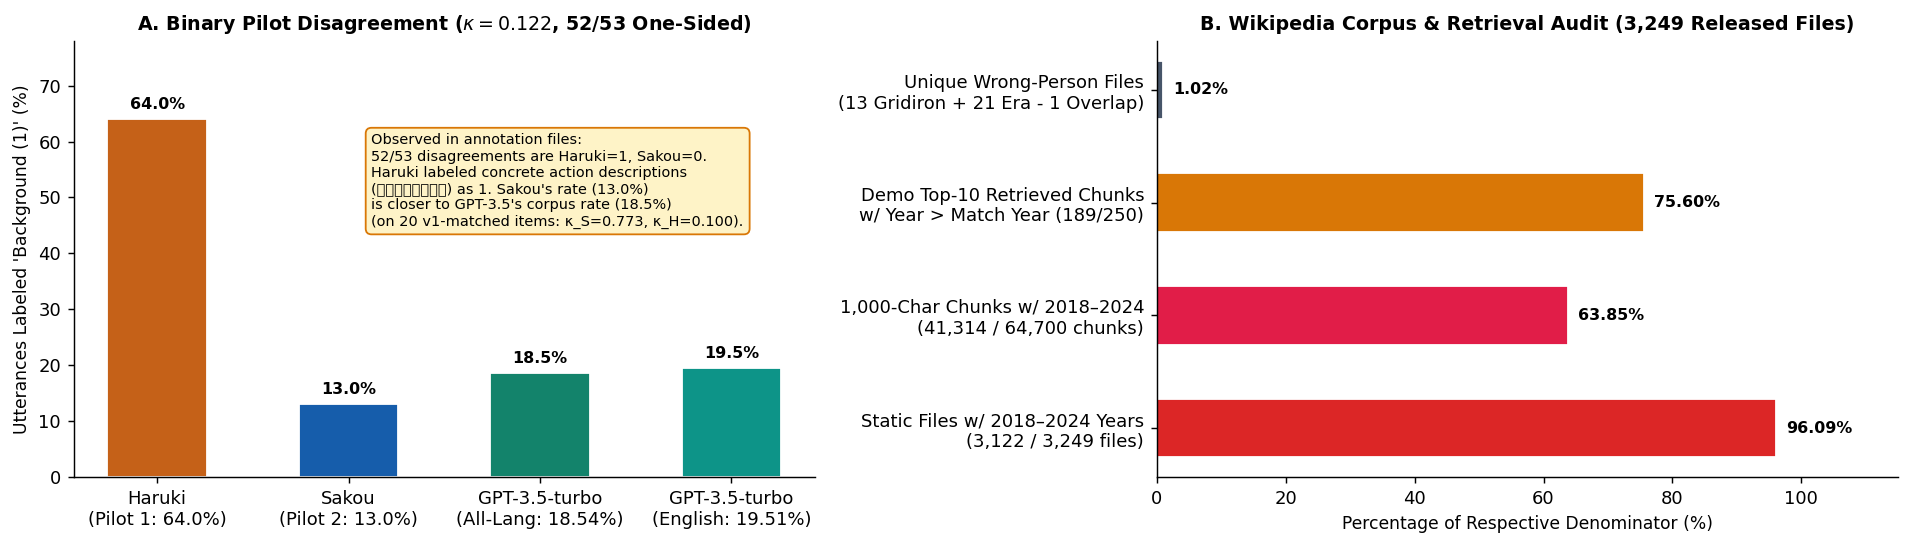

In [3]:
# STEP 2 EXECUTION: Primary-Source Audit of Mori et al.'s Annotations, Wikipedia Corpus, Retrieval & Demo Clips

# 2A. Parse Mori's 100-utterance double-annotation pilot (haruki vs. sakou)
def parse_mori_annotation_file(filepath):
    blocks = open(filepath, encoding="utf-8", errors="ignore").read().split("- game =>")[1:]
    rows = []
    for blk in blocks:
        game = blk.splitlines()[0].strip()
        m_comm = re.search(r"- comment => (.*)", blk)
        m_cat = re.search(r"category =>\s*([01])", blk)
        m_note = re.search(r"note =>\s*(.*)", blk)
        if m_comm and m_cat:
            rows.append({
                "game": game,
                "comment": m_comm.group(1).strip(),
                "cat": int(m_cat.group(1)),
                "note": m_note.group(1).strip() if m_note else ""
            })
    return pd.DataFrame(rows)

haruki_df = parse_mori_annotation_file(f"{SBS_DIR}/annotation_tool/haruki_annotation-target.txt")
sakou_df = parse_mori_annotation_file(f"{SBS_DIR}/annotation_tool/sakou_42_1_target_prompt.txt")
ann_compare = pd.DataFrame({
    "row_idx": range(len(haruki_df)),
    "game": haruki_df["game"],
    "comment": haruki_df["comment"],
    "haruki_label": haruki_df["cat"],
    "sakou_label": sakou_df["cat"],
    "haruki_note": haruki_df["note"],
    "sakou_note": sakou_df["note"],
})

# The two annotation files must list the same items in the same order, otherwise row-wise kappa is meaningless
assert len(haruki_df) == len(sakou_df) == 100, (len(haruki_df), len(sakou_df))
assert (haruki_df["comment"].to_numpy() == sakou_df["comment"].to_numpy()).all(), "comment texts differ between files"
assert (haruki_df["game"].to_numpy() == sakou_df["game"].to_numpy()).all(), "game names differ between files"
print("Row-by-row check passed: both files list the same 100 (game, comment) items in the same order")

p_obs = float((ann_compare["haruki_label"] == ann_compare["sakou_label"]).mean())
kappa_hs = float(cohen_kappa_score(ann_compare["haruki_label"], ann_compare["sakou_label"]))
n_dis = int((ann_compare["haruki_label"] != ann_compare["sakou_label"]).sum())
n_h1_s0 = int(((ann_compare["haruki_label"] == 1) & (ann_compare["sakou_label"] == 0)).sum())
n_h0_s1 = int(((ann_compare["haruki_label"] == 0) & (ann_compare["sakou_label"] == 1)).sum())
n_both0 = int(((ann_compare["haruki_label"] == 0) & (ann_compare["sakou_label"] == 0)).sum())
n_both1 = int(((ann_compare["haruki_label"] == 1) & (ann_compare["sakou_label"] == 1)).sum())

print("=== 2A. Inter-Annotator Agreement on Mori et al.'s 100-Utterance Binary Pilot ===")
print(f"Annotator 1 (haruki) Positive Rate : {ann_compare['haruki_label'].mean():.1%} ({ann_compare['haruki_label'].sum()}/100)")
print(f"Annotator 2 (sakou)  Positive Rate : {ann_compare['sakou_label'].mean():.1%} ({ann_compare['sakou_label'].sum()}/100)")
print(f"GPT-3.5-turbo-1106   Positive Rate : {scbi['付加的情報か'].mean():.2%} (All-Lang, n={len(scbi):,}) | {en_scbi['付加的情報か'].mean():.2%} (English, n={len(en_scbi):,})")
print(f"2x2 Contingency Table              : (H=0,S=0)={n_both0}, (H=1,S=1)={n_both1}, (H=1,S=0)={n_h1_s0}, (H=0,S=1)={n_h0_s1}")
print(f"Total Disagreements                : {n_dis}/100 ({n_h1_s0}/{n_dis} are Haruki=1, Sakou=0; {n_h0_s1}/{n_dis} is Haruki=0, Sakou=1)")
print(f"Raw Agreement (p_o)                : {p_obs:.1%} | Cohen's Kappa (κ) = {kappa_hs:.3f}")

# Item-level agreement of each annotator with GPT-3.5:
# Note: exp0-1.sh shows the 100-item pilot was sampled in Dec 2023 from an earlier ASR pass
# (`denoised_1_tokenized_224p_all.csv` / `gpt-3.5-turbo-1106_42_1_llm_annotation-20231217.csv`, not in the archive)
# before `scbi-v2.csv` re-segmented/re-translated the audio with WhisperX large-v3 and dropped 2 of the 15 pilot games.
# We check exact `(game_tail, text)` joins against both `scbi-v2.csv` and the earlier v1 half-1 file `gpt-3.5-turbo-1106_500game_1_llm_annotation.csv`.
scbi_keys = scbi.assign(
    game_tail=scbi["game"].astype(str).str.split("/").str[-1].str.strip(),
    text_key=scbi["text"].astype(str).str.strip(),
)
gpt_lookup_v2 = scbi_keys.groupby(["game_tail", "text_key"])["付加的情報か"].agg(["nunique", "first"]).reset_index()
gpt_lookup_v2 = gpt_lookup_v2[gpt_lookup_v2["nunique"] == 1].rename(columns={"first": "gpt_label"})[["game_tail", "text_key", "gpt_label"]]
ann_gpt_v2 = ann_compare.assign(
    game_tail=ann_compare["game"].str.strip(), text_key=ann_compare["comment"].str.strip()
).merge(gpt_lookup_v2, on=["game_tail", "text_key"], how="inner")
gl_v2 = ann_gpt_v2["gpt_label"].astype(int)
kappa_v2 = ("kappa undefined: GPT-3.5 has a single class on these items" if gl_v2.nunique() < 2 else
            f"kappa(haruki, GPT) = {cohen_kappa_score(ann_gpt_v2['haruki_label'], gl_v2):.3f}, kappa(sakou, GPT) = {cohen_kappa_score(ann_gpt_v2['sakou_label'], gl_v2):.3f}")
print(f"Pilot items matched verbatim to scbi-v2.csv : {len(ann_gpt_v2)}/100 (GPT-3.5 pos rate = {gl_v2.mean():.1%}; raw agree: Haruki={(ann_gpt_v2['haruki_label']==gl_v2).mean():.1%}, Sakou={(ann_gpt_v2['sakou_label']==gl_v2).mean():.1%}; {kappa_v2})")

v1_path = f"{LFCBI_DIR}/commentary/gpt-3.5-turbo-1106_500game_1_llm_annotation.csv"
if os.path.exists(v1_path):
    g1_df = pd.read_csv(v1_path, usecols=["game", "text", "付加的情報か"]).dropna(subset=["text", "付加的情報か"])
    g1_keys = g1_df.assign(
        game_tail=g1_df["game"].astype(str).str.split("/").str[-1].str.strip(),
        text_key=g1_df["text"].astype(str).str.strip(),
    )
    gpt_lookup_v1 = g1_keys.groupby(["game_tail", "text_key"])["付加的情報か"].agg(["nunique", "first"]).reset_index()
    gpt_lookup_v1 = gpt_lookup_v1[gpt_lookup_v1["nunique"] == 1].rename(columns={"first": "gpt_label"})[["game_tail", "text_key", "gpt_label"]]
    ann_gpt_v1 = ann_compare.assign(
        game_tail=ann_compare["game"].str.strip(), text_key=ann_compare["comment"].str.strip()
    ).merge(gpt_lookup_v1, on=["game_tail", "text_key"], how="inner")
    gl_v1 = ann_gpt_v1["gpt_label"].astype(int)
    print(f"Pilot items matched verbatim to v1 500game_1_llm_annotation.csv : {len(ann_gpt_v1)}/100 (English pre-resegmentation subset; GPT-3.5 pos rate = {gl_v1.mean():.1%})")
    print(f"  On those {len(ann_gpt_v1)} v1-matched items: kappa(haruki, GPT) = {cohen_kappa_score(ann_gpt_v1['haruki_label'], gl_v1):.3f} (raw agree = {(ann_gpt_v1['haruki_label']==gl_v1).mean():.1%}) | kappa(sakou, GPT) = {cohen_kappa_score(ann_gpt_v1['sakou_label'], gl_v1):.3f} (raw agree = {(ann_gpt_v1['sakou_label']==gl_v1).mean():.1%})")
    print(f"  Full 100-item kappa vs GPT-3.5 : NOT COMPUTED (the 2023 pilot source CSV `gpt-3.5-turbo-1106_42_1_llm_annotation-20231217.csv` is not in the public release)")
else:
    ann_gpt_v1 = None   # all v1 comparisons depend on this file; nothing below uses ann_gpt_v1
    print(f"v1 file {os.path.basename(v1_path)} not found -> pilot-vs-GPT kappa on v1 items NOT COMPUTED")

# Show a fixed-seed RANDOM sample (n=8, seed=42) of the 53 disagreements (Rule 7: never cherry-pick head())
dis_df = ann_compare[ann_compare["haruki_label"] != ann_compare["sakou_label"]]
print(f"\nRandom Sample (n=8, random_state=42) of the {n_dis} Disagreements (showing Haruki's Japanese notes):")
display(dis_df.sample(8, random_state=42)[["row_idx", "comment", "haruki_label", "sakou_label", "haruki_note"]])

# 2B. Recompute Wikipedia Corpus Audit & Top-10 TF-IDF Retrieval Simulation Directly from Raw Files
wiki_dir = f"{LFCBI_DIR}/addinfo_retrieval"
wiki_files = sorted([f for f in os.listdir(wiki_dir) if f.endswith(".txt")])
decoded_names = [urllib.parse.unquote(f[:-4]) for f in wiki_files]

wrong_sport = sorted([n for n in decoded_names if any(k in n.lower() for k in ["gridiron", "american_football", "baseball", "basketball", "rugby"])])
wrong_era = sorted([n for n in decoded_names if (m := re.search(r"born_(\d{4})", n)) and (int(m.group(1)) < 1970 or int(m.group(1)) > 2000)])
overlap_wrong = sorted(set(wrong_sport) & set(wrong_era))
unique_wrong_entity = sorted(set(wrong_sport) | set(wrong_era))

post_2017_files = 0
chunks = []
for f in wiki_files:
    txt = open(f"{wiki_dir}/{f}", encoding="utf-8", errors="ignore").read()
    if re.search(r"\b20(18|19|20|21|22|23|24)\b", txt):
        post_2017_files += 1
    # Fixed-width approximation of addinfo_retrieval.py (chunk_size=1000, chunk_overlap=100 -> step=900);
    # a separator-aware splitter would place boundaries differently (its splitter lines are printed below)
    for i in range(0, max(1, len(txt)), 900):
        c = txt[i:i + 1000]
        if c.strip():
            chunks.append(c)
        if i + 1000 >= len(txt):
            break

post_2017_chunks = sum(bool(re.search(r"\b20(18|19|20|21|22|23|24)\b", c)) for c in chunks)

# Simulate Mori et al.'s TF-IDF top-10 retrieval (addinfo_retrieval.py + construct_query.py) on the 25 demo clips
sample_meta = pd.read_csv(f"{LFCBI_DIR}/demo/sample_metadata.csv")
pif = pd.read_csv(f"{LFCBI_DIR}/demo/players_in_frames_sn_gamestate.csv")
vec_wiki = TfidfVectorizer()
X_chunks = vec_wiki.fit_transform(chunks)

demo_queries = []
for r in sample_meta.itertuples():
    t_mid = (r.start + r.end) / 2.0
    u_prev = scbi[(scbi["game"] == r.game) & (scbi["half"] == r.half) & (scbi["end"] < t_mid)].sort_values("start")
    prev_texts, tot_len = [], 0
    for txt in reversed(u_prev["text"].dropna().tolist()):
        if tot_len + len(str(txt)) > 256:
            break
        prev_texts.append(str(txt))
        tot_len += len(str(txt)) + 1
    q = "Previous comments: " + " ".join(reversed(prev_texts))
    p_sub = pif[(pif["sample_id"] == r.id) & (pif["time"] >= t_mid - 2) & (pif["time"] <= t_mid + 2)].dropna(subset=["long_name"])
    if len(p_sub):
        p_str = ", ".join([f"{row.long_name} from {row.team}" for row in p_sub.drop_duplicates(subset=["long_name", "team"]).itertuples()])
        q = f"Players shown in this frame: {p_str}\n" + q
    m_year = int(re.search(r"(201\d)-(\d{2})-(\d{2})", r.game).group(1))
    demo_queries.append((r.id, r.game, m_year, f"Game: {r.game}\n" + q))

sims_demo = linear_kernel(vec_wiki.transform([q[3] for q in demo_queries]), X_chunks)
n_demo_queries = len(demo_queries)
k_top = 10
total_retrieved_chunks = n_demo_queries * k_top
future_retrieved_chunks = 0
queries_with_future_chunk = 0

for i, (_, _, m_year, _) in enumerate(demo_queries):
    top_idx = np.argsort(sims_demo[i])[::-1][:k_top]
    fut_c = 0
    for idx in top_idx:
        years = [int(y) for y in re.findall(r"\b(20(?:1[5-9]|2[0-4]))\b", chunks[idx])]
        if any(y > m_year for y in years):
            fut_c += 1
    future_retrieved_chunks += fut_c
    if fut_c > 0:
        queries_with_future_chunk += 1

audit_df = pd.DataFrame([
    {"Metric": "Wikipedia files in paper (Sec 3.2) vs. released archive", "Count": f"{len(wiki_files)} (paper: 3,257)", "Pct": "100.0%", "Scope / Note": "8 fewer .txt files in released data/addinfo_retrieval/"},
    {"Metric": "Static files containing 2018-2024 years", "Count": f"{post_2017_files} / {len(wiki_files)}", "Pct": f"{post_2017_files/len(wiki_files):.1%}", "Scope / Note": "2024 Wikipedia snapshots used for 2014-2017 matches"},
    {"Metric": "1,000-char chunks containing 2018-2024 years", "Count": f"{post_2017_chunks:,} / {len(chunks):,}", "Pct": f"{post_2017_chunks/len(chunks):.1%}", "Scope / Note": "Fixed-width approximation of addinfo_retrieval.py (1000 chars, 100 overlap)"},
    {"Metric": "Retrieved top-10 chunks with year > match_year (25 demo clips)", "Count": f"{future_retrieved_chunks} / {total_retrieved_chunks}", "Pct": f"{future_retrieved_chunks/total_retrieved_chunks:.1%}", "Scope / Note": f"Affects {queries_with_future_chunk}/{n_demo_queries} ({queries_with_future_chunk/n_demo_queries:.0%}) demo queries; LLM output leakage NOT COMPUTED"},
    {"Metric": "Wrong sport disambiguation (gridiron / American football)", "Count": f"{len(wrong_sport)} / {len(wiki_files)}", "Pct": f"{len(wrong_sport)/len(wiki_files):.2%}", "Scope / Note": "; ".join(wrong_sport[:4])},
    {"Metric": "Wrong birth era (<1970 or >2000 for 2014-2017 matches)", "Count": f"{len(wrong_era)} / {len(wiki_files)}", "Pct": f"{len(wrong_era)/len(wiki_files):.2%}", "Scope / Note": "; ".join(wrong_era[:4])},
    {"Metric": "Unique wrong-person entity files (deduplicated union; heuristic lower bound)", "Count": f"{len(unique_wrong_entity)} / {len(wiki_files)}", "Pct": f"{len(unique_wrong_entity)/len(wiki_files):.2%}", "Scope / Note": f"Overlap ({len(overlap_wrong)} file): {overlap_wrong[0]}"},
])
audit_df.to_csv(f"{OUT_DIR}/table_mori_corpus_audit.csv", index=False)

print("\n=== 2B. Recomputed Forensic Audit of Mori et al.'s Released Wikipedia Corpus & Top-10 Retrieval ===")
display(audit_df)
print(f"All {len(wrong_sport)} Gridiron/American Football files: {wrong_sport}")
print(f"All {len(wrong_era)} Wrong-Birth-Era files: {wrong_era}")
print(f"Overlap between lists ({len(overlap_wrong)} file): {overlap_wrong} -> Unique union = {len(unique_wrong_entity)} files (heuristic lower bound)")

# Show how addinfo_retrieval.py actually splits documents, so the chunking approximation can be checked
retr_src = glob.glob(f"{MORI_CODE_DIR}/**/addinfo_retrieval.py", recursive=True)
if retr_src:
    splitter_lines = [ln.strip() for ln in open(retr_src[0], encoding="utf-8", errors="ignore") if re.search(r"Splitter|chunk_size|chunk_overlap", ln)]
    print(f"Splitter-related lines in {os.path.relpath(retr_src[0], MORI_CODE_DIR)}:")
    for ln in splitter_lines:
        print(f"  {ln}")
else:
    print("addinfo_retrieval.py not found under MORI_CODE_DIR -> chunking equivalence NOT VERIFIED")

# 2C. Inspect Demo Play-by-Play Bugs (Clips 0008 and 0010 from T-DEED + Visual Entity Linking)
print("\n=== 2C. Demo Output Bugs in data/demo/pbp/ (Driven by T-DEED Action Spotting & Visual OCR Linking) ===")
for clip_id, desc in [
    ("0008", "Bayern Munich 3 - 0 Bayer Leverkusen (credits Bayern's goal to Leverkusen's 'Kresic'; cause INFERRED: visual entity linking)"),
    ("0010", "Juventus 3 - 2 Fiorentina (T-DEED duplicate action trigger: calls TWO goals 0.56s apart at 16.96s & 17.52s with 'BALL PLAYER BLOCK' in between)"),
]:
    print(f"\nClip {clip_id}: {desc}")
    clip_rows = [json.loads(line) for line in open(f"{LFCBI_DIR}/demo/pbp/{clip_id}/play-by-play-en.jsonl")]
    display(pd.DataFrame(clip_rows)[["start_time", "end_time", "action", "name", "team", "text"]])
    if clip_id == "0008":
        kres = pif[(pif["sample_id"] == int(clip_id)) & pif["long_name"].fillna("").str.contains("kre", case=False)]
        print(f"players_in_frames_sn_gamestate.csv rows for sample_id={int(clip_id)} naming 'Kre*': {len(kres)}")
        if len(kres):
            display(kres.head(10))
        else:
            print("  No rows matched -> check the sample_id <-> clip-folder mapping before attributing the cause")

# Visualization 2: 2-Panel Forensic Summary (All numbers dynamically interpolated from computed variables)
fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.3))

# Panel A: Annotation rate & Kappa comparison
labels_a = [
    f"Haruki\n(Pilot 1: {ann_compare['haruki_label'].mean()*100:.1f}%)",
    f"Sakou\n(Pilot 2: {ann_compare['sakou_label'].mean()*100:.1f}%)",
    f"GPT-3.5-turbo\n(All-Lang: {scbi['付加的情報か'].mean()*100:.2f}%)",
    f"GPT-3.5-turbo\n(English: {en_scbi['付加的情報か'].mean()*100:.2f}%)"
]
rates_a = [
    ann_compare["haruki_label"].mean() * 100,
    ann_compare["sakou_label"].mean() * 100,
    scbi["付加的情報か"].mean() * 100,
    en_scbi["付加的情報か"].mean() * 100,
]
bars = axes[0].bar(labels_a, rates_a, color=["#C56118", "#165DAB", "#13836B", "#0D9488"], width=0.52, edgecolor="white")
for b, v in zip(bars, rates_a):
    axes[0].text(b.get_x() + b.get_width()/2, v + 1.8, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=8.8)
axes[0].set_ylim(0, 78)
axes[0].set_ylabel("Utterances Labeled 'Background (1)' (%)")
axes[0].set_title(f"A. Binary Pilot Disagreement ($\\kappa = {kappa_hs:.3f}$, {n_h1_s0}/{n_dis} One-Sided)")
axes[0].annotate(
    f"Observed in annotation files:\n{n_h1_s0}/{n_dis} disagreements are Haruki=1, Sakou=0.\nHaruki labeled concrete action descriptions\n(具体的動作の説明) as 1. Sakou's rate ({ann_compare['sakou_label'].mean()*100:.1f}%)\nis closer to GPT-3.5's corpus rate ({scbi['付加的情報か'].mean()*100:.1f}%)\n(on 20 v1-matched items: κ_S={cohen_kappa_score(ann_gpt_v1['sakou_label'], gl_v1):.3f}, κ_H={cohen_kappa_score(ann_gpt_v1['haruki_label'], gl_v1):.3f}).",
    xy=(0.4, 52), xytext=(1.12, 45),
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF3C7", edgecolor="#D97706"),
    fontsize=8.0
)

# Panel B: Wikipedia corpus & retrieved chunk audit
cats_b = [
    f"Static Files w/ 2018–2024 Years\n({post_2017_files:,} / {len(wiki_files):,} files)",
    f"1,000-Char Chunks w/ 2018–2024\n({post_2017_chunks:,} / {len(chunks):,} chunks)",
    f"Demo Top-10 Retrieved Chunks\nw/ Year > Match Year ({future_retrieved_chunks}/{total_retrieved_chunks})",
    f"Unique Wrong-Person Files\n({len(wrong_sport)} Gridiron + {len(wrong_era)} Era - {len(overlap_wrong)} Overlap)"
]
pcts_b = [
    post_2017_files / len(wiki_files) * 100,
    post_2017_chunks / len(chunks) * 100,
    future_retrieved_chunks / total_retrieved_chunks * 100,
    len(unique_wrong_entity) / len(wiki_files) * 100,
]
bars_b = axes[1].barh(cats_b, pcts_b, color=["#DC2626", "#E11D48", "#D97706", "#475569"], height=0.52, edgecolor="white")
for b, p_val in zip(bars_b, pcts_b):
    axes[1].text(p_val + 1.5, b.get_y() + b.get_height()/2, f"{p_val:.2f}%", va="center", fontweight="bold", fontsize=8.8)
axes[1].set_xlim(0, 115)
axes[1].set_xlabel("Percentage of Respective Denominator (%)")
axes[1].set_title(f"B. Wikipedia Corpus & Retrieval Audit ({len(wiki_files):,} Released Files)")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_step2_mori_forensic_audit.png", bbox_inches="tight")
plt.show()

### Results [OBSERVED]

**2A. Why κ = 0.122.**
- The two annotation files list the same 100 (game, comment) items in the same order; the code checks this row by row before computing κ. Raw agreement was 47%. Annotator *haruki* labeled 64% of items as background; *sakou* labeled 13%.
- 52 of the 53 disagreements go the same way (haruki = 1, sakou = 0). In the random sample above, haruki marked plain action calls such as *"Great switch from Alonso."*, *"He's caught the ball."* and *"Now Willian."* as background, with notes like 具体的動作の説明 ("explains the concrete action").
- The guideline does not support that reading. `annotation-human.md` tells annotators to follow the few-shot examples in `annotation-description.txt` [CITED]. There, Shot 9 labels a plain action description `0`, and Shots 5, 6, 10 and 12 also label subjective or analytical remarks `0` (*"A terrific season as a Marseille player"*, *"enjoying quite a renaissance"*, *"that would have had a bearing on the Zouma decision"*).
- The repository also contains a separate 4-category video guideline (`annotation_guideline.md`). It was not used for this binary pilot.

**2A. Annotators vs GPT-3.5.** The pilot was sampled in December 2023 from an earlier transcription pass that is not in the public release [CITED: `scripts/experiment-llm-annotation/exp0-1.sh`, which reads `gpt-3.5-turbo-1106_42_1_llm_annotation-20231217.csv` and `denoised_1_tokenized_224p_all.csv`]. As a result, most pilot texts no longer match the released data verbatim.
- 12 of 100 items match `scbi-v2.csv`. All 12 have GPT = 0, so κ is undefined; sakou agrees on 91.7% of them and haruki on 25.0%.
- 20 of 100 English items match the earlier v1 file `gpt-3.5-turbo-1106_500game_1_llm_annotation.csv`. On those, κ(sakou, GPT) = 0.773 (95% agreement) and κ(haruki, GPT) = 0.100 (55%).
- κ on the full 100 items against GPT-3.5 is NOT COMPUTED, because the source file is not public.

**2B. Wikipedia corpus and retrieval.**

| Check | Result |
|---|---|
| Pages in the release vs the paper (Sec 3.2) | 3,249 files vs 3,257 reported |
| Files mentioning any year 2018–2024 (the matches are 2014–2017) | 3,122 / 3,249 (96.1%) |
| Chunks mentioning 2018–2024 | 41,314 / 64,700 (63.9%) |
| Top-10 retrieved chunks mentioning a year after the match (25 demo clips) | 189 / 250 (75.6%); all 25 queries affected |
| Wrong-sport pages (gridiron / American football) | 13 |
| Wrong-era pages (born before 1970 or after 2000) | 21 |
| Unique wrong-person pages (1 page appears in both lists) | at least 33 (1.02%) |

- A later year is not always post-match information (a contract "until 2019" signed in 2015 is fine), so 75.6% is an **upper bound** on post-match content in the prompt.
- Mori et al.'s prompt tells GPT-4o *"Do not use information dated after this"* [CITED: `constants.py`]. Their generated outputs are not released, so how often GPT-4o actually used post-match facts is NOT COMPUTED.
- The 33 wrong-person pages are a **lower bound**: a wrong person under a title with no disambiguator would not be caught.
- The "gold documents" in `reference_documents/evaluation-samples.yaml` are a human-evaluation oracle condition (Sec 5.2.1 [CITED]), not the automatic corpus. On manual inspection, some are post-match reports stating the final score [UNVERIFIED in code: not printed by the cell above].

**2C. Demo clip errors.** The demo play-by-play is driven by T-DEED action spotting and visual player identification, not by `Labels-v2` [CITED: `mthesis-actioin-spotting-over_1sec.sh`, `players_in_frames_sn_gamestate.csv`].
- **Clip 0010 (Juventus vs Fiorentina):** T-DEED fires GOAL at 16.96 s and again at 17.52 s with a BALL PLAYER BLOCK in between, so the system calls two goals 0.56 s apart.
- **Clip 0008 (Bayern vs Leverkusen):** the goal is credited to Leverkusen's Dario Kresic. The player-identification table has 124 rows for this clip naming Kresic (#25, Leverkusen), so the error is already present in the visual linking, before any text is generated.

### Design implications [INFERRED]
1. **Don't treat the GPT-3.5 label as ground truth.** On the 20 items we could match it agrees well with one annotator, but the sample is small. Our own taxonomy (Exp 1) must first reach human κ > 0.60.
2. **Replace live retrieval with a pre-kickoff notebook** holding only facts dated before kick-off, each tied to a verified entity ID. This targets both measured failures: post-match years and wrong-person pages.
3. **Deduplicate same-class events** (two GOALs 0.56 s apart) before anything is spoken.
4. **Check entity links against match context**, for example that the scorer belongs to the attacking team and is on the pitch. A coalescer cannot fix a wrong name.

### Caveats
- The annotator-vs-GPT κ rests on 20 items.
- The retrieval is a re-implementation with approximate chunking.
- A later year is only a proxy for post-match information.

---
## Step 3 — Can match events predict the single-voice "background" label?

**Question.** A live system can't hear what the human commentator is about to say; it knows only past events, the clock and the timing of earlier speech. Using only those causal features, how well can we predict whether an utterance carries Mori et al.'s GPT-3.5 "background information" label? We compare against trivial baselines and against a model that reads the words.

**Why it matters.** If events can't predict this label, it is a poor routing target and we need a different decomposition (Step 4).

**Setup.** English only. We train on 81 games (67,444 utterances), choose thresholds on 27 validation games (21,861) and test on 25 held-out games (21,571 utterances; 19.43% positive). The 95% confidence intervals come from 200 game-level bootstrap resamples.

| # | Model | Inputs |
|---|---|---|
| 1a | Always predict "background" | None. F1 = 2p/(1+p) = 0.3254 at p = 0.1943; AUROC 0.5 |
| 1b | Same label as the previous utterance | The previous label. This is an *oracle*: a live system would first have to classify the previous utterance |
| 2a | Mori rule, causal | p = 1.0 within 15 s after kick-off, 0.5 within 15 s after an out-of-play event, otherwise 0.18 [CITED: `spotting_module.py`; paper Sec 3.1] |
| 2b | Mori rule, two-sided | The same rule with events within ±15 s, so it uses future events [CITED: footnote 7] |
| 3 | Gradient-boosted trees (HGB) | 22 event and clock features: half, clock, event counts in the last 60 s and 15 s, the last event's visibility, and time since each of 17 event classes |
| 4 | HGB + timing | Adds the pause before the utterance and the previous utterance's duration (24 features) |
| 5 | HGB + timing + oracle | Adds the previous label (25 features) |
| 6 | TF-IDF + logistic regression | Reads the utterance's own text. A reference point, not a live model |

`spotting_module.py` uses a default rate of 0.185 rather than 0.18. That doesn't change AUROC, which depends only on how utterances are ranked, though it shifts F1 slightly.

**Terminology.** HGB scores are the performance of *one* model on *these* features, not a ceiling. TF-IDF is a lexical reference: the label was produced by an LLM reading the same text, so a stronger text model would score higher still.


=== 3A. Recomputed Binary Background Benchmark on Held-Out English Test Split (n = 21,571, 25 Games) ===


,model,f1,auc,ap,f1_ci,auc_ci,ap_ci
0,1a. Constant Always-Background (all 1),0.3254,0.5000,0.1943,"[0.304,0.346]","[0.500,0.500]","[0.179,0.209]"
1,"1b. Persistence Baseline (same as prev_y, ORACLE)",0.3261,0.5833,0.2380,"[0.303,0.348]","[0.571,0.597]","[0.223,0.256]"
2,"2a. Mori Rule Causal [0,+15s] (p=0.18, 20 seeds)",0.2544,0.5483,0.2159,"[0.239,0.269]","[0.539,0.560]","[0.203,0.234]"
3,"2b. Mori Rule Two-Sided [-15s,+15s] (p=0.18, n...",0.2668,0.5237,0.2067,"[0.250,0.285]","[0.512,0.535]","[0.194,0.223]"
4,3. HGB: Events + Clock (22 features),0.3546,0.6095,0.2627,"[0.335,0.374]","[0.595,0.624]","[0.245,0.280]"
5,4. HGB: Events + Clock + Utterance Timing (24 ...,0.3680,0.6342,0.2757,"[0.351,0.385]","[0.620,0.649]","[0.260,0.297]"
6,5. HGB: Events + Timing + Oracle prev_y (25 fe...,0.3836,0.6632,0.3088,"[0.367,0.403]","[0.647,0.678]","[0.291,0.329]"
7,6. TF-IDF + LR Text Reference (sees spoken words),0.5910,0.8487,0.6479,"[0.574,0.611]","[0.839,0.860]","[0.628,0.673]"



=== 3B. Side-by-Side Comparison: Mori Table 6 vs. Recomputed All-Language vs. English [0, +15s] Background Rates ===


,Event Context,Mori_Paper_Table6_After_pct,Mori_Released_CSV_After_pct,Recomp_AllLang_After_pct,Recomp_English_After_pct,n_English_Turns
0,Unconditional Baseline (All Turns),NaN,NaN,18.54,19.51,110876
1,"Within [0, +15s] after Penalty",46.03,46.03,47.15,50.00,106
2,"Within [0, +15s] after Goal",32.06,32.02,32.99,30.65,1044
3,"Within [0, +15s] after Substitution",25.06,25.08,24.94,29.04,1498
4,"Within [0, +15s] after Yellow card",31.50,31.51,31.18,27.28,1272
5,"Within [0, +15s] after Foul",24.41,24.40,24.62,24.83,6223
6,"Within [0, +15s] after Shots on target",22.58,22.57,23.04,21.72,3969
7,"Within [0, +15s] after Throw-in",17.90,17.89,17.74,19.15,10962
8,"Within [0, +15s] after Corner",17.01,16.99,17.01,15.38,3393


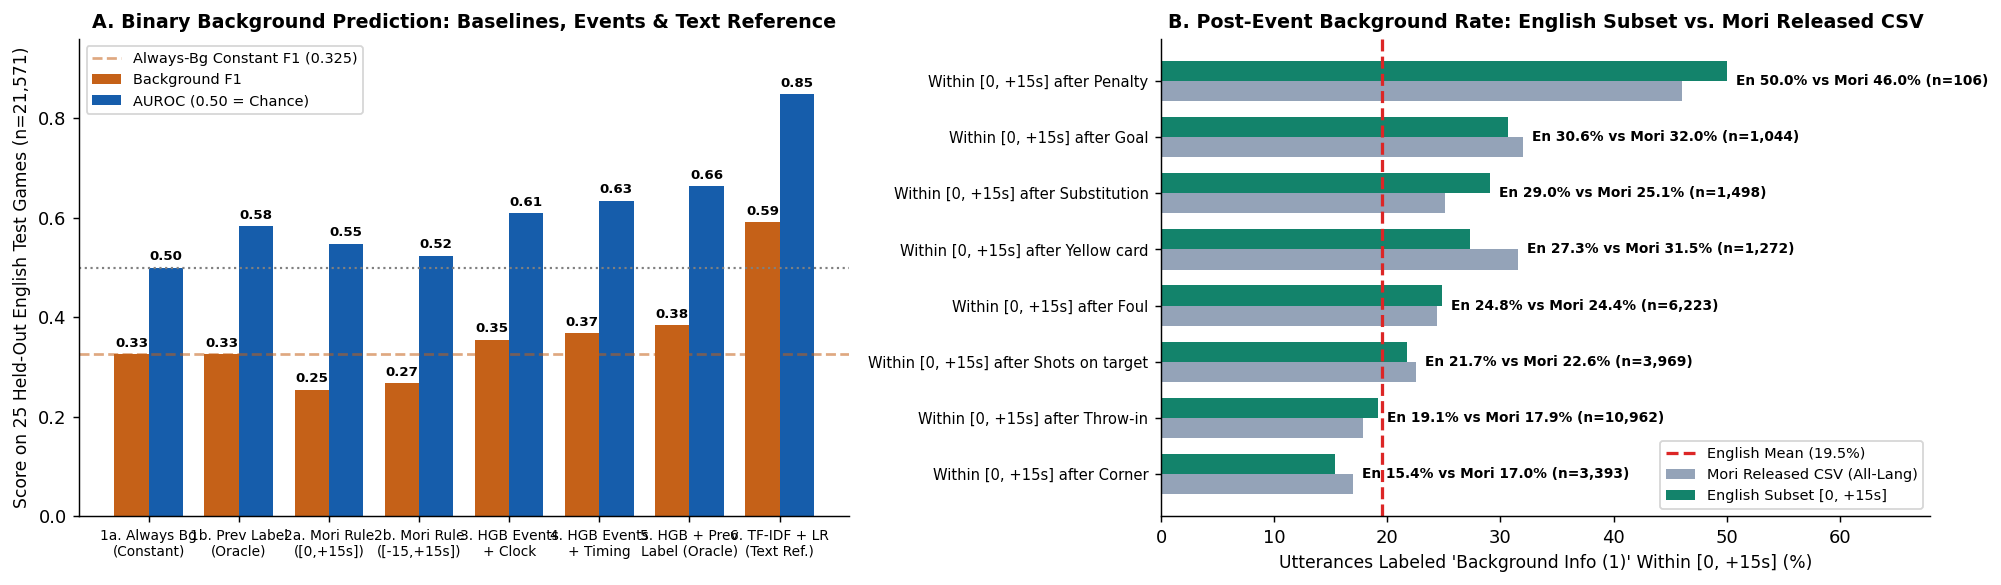

In [4]:
# STEP 3 EXECUTION: Train & Evaluate All Binary Background Predictors Directly on LFCBI + Labels-v2
CLASSES = [
    "Penalty", "Kick-off", "Goal", "Substitution", "Offside", "Shots on target", "Shots off target",
    "Clearance", "Ball out of play", "Throw-in", "Foul", "Indirect free-kick", "Direct free-kick",
    "Corner", "Yellow card", "Red card", "Yellow->red card"
]
OFFPLAY_A = ["Foul", "Goal", "Penalty", "Red card", "Yellow card", "Yellow->red card", "Substitution", "Offside", "Ball out of play"]
CAP = 300.0

utt = en_splits.copy()
utt["half"] = utt["half"].astype(int)
utt["y"] = (utt["target_label"] == 2.0).astype(int)

# Load all 133 English games' Labels-v2.json
events_dict = {}
for g in utt["game"].unique():
    p = f"{SN_LABELS_DIR}/{g}/Labels-v2.json"
    if os.path.exists(p):
        ann = json.load(open(p))["annotations"]
        ev = pd.DataFrame([{
            "half": int(a["gameTime"].split(" - ")[0]),
            "t": int(a["position"]) / 1000.0,
            "label": a["label"],
            "shown": a.get("visibility") == "visible"
        } for a in ann])
        events_dict[g] = ev.sort_values("t")

# Build features at each human utterance onset t
feature_rows = []
for (g, h), u in utt.sort_values("start").groupby(["game", "half"]):
    ev = events_dict[g]
    ev = ev[ev["half"] == h]
    et, el, es = ev["t"].to_numpy(), ev["label"].to_numpy(), ev["shown"].to_numpy()
    prev_end, prev_dur, prev_y = np.nan, np.nan, np.nan
    for r in u.itertuples():
        t = r.start
        m = et <= t
        f = {"half": h, "clock": t / 60.0}
        for c in CLASSES:
            tt = et[m & (el == c)]
            f["since_" + c] = min(t - tt[-1], CAP) if len(tt) else CAP
        f["n_ev_60"] = int(((et > t - 60) & m).sum())
        f["n_ev_15"] = int(((et > t - 15) & m).sum())
        f["last_shown"] = float(es[m][-1]) if m.any() else -1.0
        f["gap"] = t - prev_end if prev_end == prev_end else -1.0
        f["prev_dur"] = prev_dur if prev_dur == prev_dur else -1.0
        f["prev_y"] = prev_y if prev_y == prev_y else -1.0

        # Mori rule 2a: Causal [0, +15s] after event, p=0.18 (Sec 3.1 / spotting_module.py line 225)
        past15 = [b for a, b in zip(et[m], el[m]) if t - a <= 15.0]
        if "Kick-off" in past15:
            f["mori_p_causal"] = 1.0
        elif any(b in OFFPLAY_A for b in past15):
            f["mori_p_causal"] = 0.5
        else:
            f["mori_p_causal"] = 0.18

        # Mori rule 2b: Two-sided [-15s, +15s] around event, p=0.18 (Footnote 7, non-causal)
        win15 = [b for a, b in zip(et, el) if abs(t - a) <= 15.0]
        if "Kick-off" in win15:
            f["mori_p_twosided"] = 1.0
        elif any(b in OFFPLAY_A for b in win15):
            f["mori_p_twosided"] = 0.5
        else:
            f["mori_p_twosided"] = 0.18

        f.update(game=g, split=r.split, y=r.y, text=r.text if isinstance(r.text, str) else "")
        feature_rows.append(f)
        prev_end, prev_dur, prev_y = r.end, r.end - r.start, r.y

df_step3 = pd.DataFrame(feature_rows)
tr3, va3, te3 = (df_step3[df_step3["split"] == s].copy() for s in ["train", "valid", "test"])

EV_COLS = ["half", "clock", "n_ev_60", "n_ev_15", "last_shown"] + ["since_" + c for c in CLASSES]

def best_thr_full(y_true, p_pred):
    thrs = np.quantile(p_pred, np.linspace(0.05, 0.95, 91))
    return max(thrs, key=lambda th: f1_score(y_true, p_pred >= th))

def boot_ci_step3(df_eval, p_col, thr=None, is_bernoulli=False, n_boot=200, seed=42):
    b_rng = np.random.default_rng(seed)
    games = df_eval["game"].unique()
    grouped = {g: df_eval[df_eval["game"] == g] for g in games}
    f1s, aucs, aps = [], [], []
    for _ in range(n_boot):
        sg = b_rng.choice(games, len(games), replace=True)
        sub = pd.concat([grouped[g] for g in sg], ignore_index=True)
        yb = sub["y"].to_numpy()
        pb = sub[p_col].to_numpy()
        if is_bernoulli:
            yhat = b_rng.random(len(pb)) < pb
            f1s.append(f1_score(yb, yhat))
        else:
            f1s.append(f1_score(yb, pb >= thr))
        aucs.append(roc_auc_score(yb, pb))
        aps.append(average_precision_score(yb, pb))
    return (
        f"[{np.percentile(f1s, 2.5):.3f},{np.percentile(f1s, 97.5):.3f}]",
        f"[{np.percentile(aucs, 2.5):.3f},{np.percentile(aucs, 97.5):.3f}]",
        f"[{np.percentile(aps, 2.5):.3f},{np.percentile(aps, 97.5):.3f}]",
    )

# Train and evaluate all models live
step3_rows = []
te3["p_const1"] = 1.0
f1_ci, auc_ci, ap_ci = boot_ci_step3(te3, "p_const1", thr=0.5)
step3_rows.append({
    "model": "1a. Constant Always-Background (all 1)",
    "f1": round(float(f1_score(te3["y"], np.ones(len(te3)))), 4),
    "auc": 0.5000,
    "ap": round(float(te3["y"].mean()), 4),
    "f1_ci": f1_ci, "auc_ci": "[0.500,0.500]", "ap_ci": ap_ci
})

te3["p_persist"] = np.where(te3["prev_y"] >= 0, te3["prev_y"], tr3["y"].mean())
f1_ci, auc_ci, ap_ci = boot_ci_step3(te3, "p_persist", thr=0.5)
step3_rows.append({
    "model": "1b. Persistence Baseline (same as prev_y, ORACLE)",
    "f1": round(float(f1_score(te3["y"], te3["p_persist"] >= 0.5)), 4),
    "auc": round(float(roc_auc_score(te3["y"], te3["p_persist"])), 4),
    "ap": round(float(average_precision_score(te3["y"], te3["p_persist"])), 4),
    "f1_ci": f1_ci, "auc_ci": auc_ci, "ap_ci": ap_ci
})

for col_m, label_m in [
    ("mori_p_causal", "2a. Mori Rule Causal [0,+15s] (p=0.18, 20 seeds)"),
    ("mori_p_twosided", "2b. Mori Rule Two-Sided [-15s,+15s] (p=0.18, non-causal)"),
]:
    s_rng = np.random.default_rng(0)
    mf1 = float(np.mean([f1_score(te3["y"], s_rng.random(len(te3)) < te3[col_m].to_numpy()) for _ in range(20)]))
    f1_ci, auc_ci, ap_ci = boot_ci_step3(te3, col_m, is_bernoulli=True)
    step3_rows.append({
        "model": label_m,
        "f1": round(mf1, 4),
        "auc": round(float(roc_auc_score(te3["y"], te3[col_m])), 4),
        "ap": round(float(average_precision_score(te3["y"], te3[col_m])), 4),
        "f1_ci": f1_ci, "auc_ci": auc_ci, "ap_ci": ap_ci
    })

for name, cols in [
    ("3. HGB: Events + Clock (22 features)", EV_COLS),
    ("4. HGB: Events + Clock + Utterance Timing (24 features)", EV_COLS + ["gap", "prev_dur"]),
    ("5. HGB: Events + Timing + Oracle prev_y (25 features)", EV_COLS + ["gap", "prev_dur", "prev_y"]),
]:
    clf = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300, random_state=0)
    clf.fit(tr3[cols], tr3["y"])
    pv = clf.predict_proba(va3[cols])[:, 1]
    th = best_thr_full(va3["y"].to_numpy(), pv)
    pcol = f"p_{name[:2]}"
    te3[pcol] = clf.predict_proba(te3[cols])[:, 1]
    f1_ci, auc_ci, ap_ci = boot_ci_step3(te3, pcol, thr=th)
    step3_rows.append({
        "model": name,
        "f1": round(float(f1_score(te3["y"], te3[pcol] >= th)), 4),
        "auc": round(float(roc_auc_score(te3["y"], te3[pcol])), 4),
        "ap": round(float(average_precision_score(te3["y"], te3[pcol])), 4),
        "f1_ci": f1_ci, "auc_ci": auc_ci, "ap_ci": ap_ci
    })

vec3 = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)
Xtr3 = vec3.fit_transform(tr3["text"])
Xva3 = vec3.transform(va3["text"])
Xte3 = vec3.transform(te3["text"])
lr3 = LogisticRegression(max_iter=500, C=2.0).fit(Xtr3, tr3["y"])
pv_txt = lr3.predict_proba(Xva3)[:, 1]
th_txt = best_thr_full(va3["y"].to_numpy(), pv_txt)
te3["p_txt"] = lr3.predict_proba(Xte3)[:, 1]
f1_ci, auc_ci, ap_ci = boot_ci_step3(te3, "p_txt", thr=th_txt)
step3_rows.append({
    "model": "6. TF-IDF + LR Text Reference (sees spoken words)",
    "f1": round(float(f1_score(te3["y"], te3["p_txt"] >= th_txt)), 4),
    "auc": round(float(roc_auc_score(te3["y"], te3["p_txt"])), 4),
    "ap": round(float(average_precision_score(te3["y"], te3["p_txt"])), 4),
    "f1_ci": f1_ci, "auc_ci": auc_ci, "ap_ci": ap_ci
})

bench_df = pd.DataFrame(step3_rows)
bench_df.to_csv(f"{OUT_DIR}/table_binary_bg_benchmark_en.csv", index=False)
print(f"=== 3A. Recomputed Binary Background Benchmark on Held-Out English Test Split (n = {len(te3):,}, {te3['game'].nunique()} Games) ===")
display(bench_df)

# 3B. Side-by-side comparison of Post-Event [0, +15s] Background Rates: Mori Table 6 vs. Recomputed All-Lang vs. English
mori_t6_csv = pd.read_csv(f"{LFCBI_DIR}/demo/Additional_Info_Ratios__Before_and_After.csv").set_index("label")

# Compute All-Language [0, +15s] rates across scbi
all_events_map = {}
for g in scbi["game"].unique():
    p = f"{SN_LABELS_DIR}/{g}/Labels-v2.json"
    if os.path.exists(p):
        ann = json.load(open(p))["annotations"]
        all_events_map[g] = pd.DataFrame([{"half": int(a["gameTime"].split(" - ")[0]), "t": int(a["position"])/1000.0, "label": a["label"]} for a in ann])

target_ev_list = ["Penalty", "Goal", "Substitution", "Yellow card", "Foul", "Shots on target", "Throw-in", "Corner"]
all_lang_after = {c: [] for c in target_ev_list}
for (g, h), u in scbi.groupby(["game", "half"]):
    if g not in all_events_map:
        continue
    ev = all_events_map[g]
    ev = ev[ev["half"] == h]
    ut = u["start"].to_numpy()
    uy = u["付加的情報か"].to_numpy()
    for c in target_ev_list:
        et = ev[ev["label"] == c]["t"].to_numpy()
        if len(et) == 0:
            continue
        diff = ut[:, None] - et[None, :]
        m_after = ((diff >= 0) & (diff <= 15.0)).any(axis=1)
        all_lang_after[c].extend(uy[m_after].tolist())

# [CITED: football-commentary.pdf Table 6, "15 sec after" column]; the released CSV differs from it only by rounding
MORI_TABLE6_PAPER_AFTER = {
    "Penalty": 46.03, "Goal": 32.06, "Substitution": 25.06, "Yellow card": 31.50,
    "Foul": 24.41, "Shots on target": 22.58, "Throw-in": 17.90, "Corner": 17.01,
}
ev_cond_rows = [{
    "Event Context": "Unconditional Baseline (All Turns)",
    "Mori_Paper_Table6_After_pct": np.nan,  # the paper only states "the overall usage rate of 18%"
    "Mori_Released_CSV_After_pct": np.nan,
    "Recomp_AllLang_After_pct": round(float(scbi["付加的情報か"].mean() * 100), 2),
    "Recomp_English_After_pct": round(float(df_step3["y"].mean() * 100), 2),
    "n_English_Turns": len(df_step3),
}]
for c in target_ev_list:
    sub_en = df_step3[df_step3["since_" + c] <= 15.0]
    ev_cond_rows.append({
        "Event Context": f"Within [0, +15s] after {c}",
        "Mori_Paper_Table6_After_pct": MORI_TABLE6_PAPER_AFTER[c],
        "Mori_Released_CSV_After_pct": round(float(mori_t6_csv.loc[c, "rate_after"] * 100), 2),
        "Recomp_AllLang_After_pct": round(float(np.mean(all_lang_after[c]) * 100), 2),
        "Recomp_English_After_pct": round(float(sub_en["y"].mean() * 100), 2),
        "n_English_Turns": len(sub_en),
    })
ev_cond_df = pd.DataFrame(ev_cond_rows)
print("\n=== 3B. Side-by-Side Comparison: Mori Table 6 vs. Recomputed All-Language vs. English [0, +15s] Background Rates ===")
display(ev_cond_df)

# Visualization 3: 2-Panel Comparison of Binary Predictors & Side-by-Side Table 6 Rates
fig, axes = plt.subplots(1, 2, figsize=(15.6, 4.6))

# Panel A: F1 vs AUROC across the 8 evaluated predictors
models_short = [
    "1a. Always Bg\n(Constant)",
    "1b. Prev Label\n(Oracle)",
    "2a. Mori Rule\n([0,+15s])",
    "2b. Mori Rule\n([-15,+15s])",
    "3. HGB Events\n+ Clock",
    "4. HGB Events\n+ Timing",
    "5. HGB + Prev\nLabel (Oracle)",
    "6. TF-IDF + LR\n(Text Ref.)"
]
x_pos = np.arange(len(models_short))
w = 0.38
b1 = axes[0].bar(x_pos - w/2, bench_df["f1"], width=w, color="#C56118", label="Background F1")
b2 = axes[0].bar(x_pos + w/2, bench_df["auc"], width=w, color="#165DAB", label="AUROC (0.50 = Chance)")
axes[0].axhline(0.50, color="gray", linestyle=":", linewidth=1.2)
axes[0].axhline(
    bench_df["f1"].iloc[0], color="#C56118", linestyle="--", alpha=0.55,
    label=f"Always-Bg Constant F1 ({bench_df['f1'].iloc[0]:.3f})"
)
for bar in list(b1) + list(b2):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015, f"{bar.get_height():.2f}", ha="center", fontsize=7.4, fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(models_short, fontsize=7.6)
axes[0].set_ylim(0, 0.96)
axes[0].set_ylabel(f"Score on {te3['game'].nunique()} Held-Out English Test Games (n={len(te3):,})")
axes[0].set_title("A. Binary Background Prediction: Baselines, Events & Text Reference")
axes[0].legend(loc="upper left", fontsize=8.0)

# Panel B: Side-by-side Mori Table 6 (All-Lang) vs English [0, +15s] rates
cond_plot = ev_cond_df.iloc[1:].sort_values("Recomp_English_After_pct", ascending=True)
y_idx = np.arange(len(cond_plot))
h_bar = 0.36
axes[1].barh(y_idx - h_bar/2, cond_plot["Mori_Released_CSV_After_pct"], height=h_bar, color="#94A3B8", label="Mori Released CSV (All-Lang)")
axes[1].barh(y_idx + h_bar/2, cond_plot["Recomp_English_After_pct"], height=h_bar, color="#13836B", label="English Subset [0, +15s]")
axes[1].axvline(df_step3["y"].mean() * 100, color="#DC2626", linestyle="--", linewidth=1.8, label=f"English Mean ({df_step3['y'].mean()*100:.1f}%)")
for i, (m_val, e_val, n_val) in enumerate(zip(cond_plot["Mori_Released_CSV_After_pct"], cond_plot["Recomp_English_After_pct"], cond_plot["n_English_Turns"])):
    axes[1].text(max(m_val, e_val) + 0.8, i, f"En {e_val:.1f}% vs Mori {m_val:.1f}% (n={n_val:,})", va="center", fontsize=7.6, fontweight="bold")
axes[1].set_yticks(y_idx)
axes[1].set_yticklabels(cond_plot["Event Context"], fontsize=8.2)
axes[1].set_xlim(0, 68)
axes[1].set_xlabel("Utterances Labeled 'Background Info (1)' Within [0, +15s] (%)")
axes[1].set_title("B. Post-Event Background Rate: English Subset vs. Mori Released CSV")
axes[1].legend(loc="lower right", fontsize=8.0)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_step3_binary_bg_benchmark.png", bbox_inches="tight")
plt.show()


### Results [OBSERVED]

**3A. Held-out test (25 games, n = 21,571).**

| Model | F1 [95% CI] | AUROC [95% CI] | AP |
|---|---|---|---|
| 1a Always background | 0.3254 [0.304, 0.346] | 0.5000 | 0.1943 |
| 1b Previous label (oracle) | 0.3261 [0.303, 0.348] | 0.5833 [0.571, 0.597] | 0.2380 |
| 2a Mori rule, causal (mean of 20 seeds) | 0.2544 [0.239, 0.269] | 0.5483 [0.539, 0.560] | 0.2159 |
| 2b Mori rule, two-sided | 0.2668 [0.250, 0.285] | 0.5237 [0.512, 0.535] | 0.2067 |
| 3 HGB events + clock | 0.3546 [0.335, 0.374] | 0.6095 [0.595, 0.624] | 0.2627 |
| 4 HGB + timing | 0.3680 [0.351, 0.385] | 0.6342 [0.620, 0.649] | 0.2757 |
| 5 HGB + timing + oracle label | 0.3836 [0.367, 0.403] | 0.6632 [0.647, 0.678] | 0.3088 |
| 6 TF-IDF text reference | 0.5910 [0.574, 0.611] | 0.8487 [0.839, 0.860] | 0.6479 |

- Both Mori timing rules score **lower F1 than always predicting "background"**.
- The best causal model (events + clock) reaches only 0.61 AUROC. Model 4 reaches 0.63, but its pause feature uses the utterance's own start time, so it isn't causal. Reading the words reaches 0.85.

**3B. Background rate in the 15 s after each event.**

| Event | English (n turns) | All languages, recomputed | Mori released CSV | Mori paper, Table 6 |
|---|---|---|---|---|
| Penalty | 50.00% (106) | 47.15% | 46.03% | 46.03% |
| Goal | 30.65% (1,044) | 32.99% | 32.02% | 32.06% |
| Substitution | 29.04% (1,498) | 24.94% | 25.08% | 25.06% |
| Yellow card | 27.28% (1,272) | 31.18% | 31.51% | 31.50% |
| Foul | 24.83% (6,223) | 24.62% | 24.40% | 24.41% |
| Shots on target | 21.72% (3,969) | 23.04% | 22.57% | 22.58% |
| Throw-in | 19.15% (10,962) | 17.74% | 17.89% | 17.90% |
| Corner | 15.38% (3,393) | 17.01% | 16.99% | 17.01% |
| *Any time (baseline)* | *19.51%* | *18.54%* | — | — |

Our all-language recomputation closely matches Mori et al.'s released rates, which suggests theirs were computed across all languages [INFERRED]. The released CSV and the printed table differ only by rounding.

### Design implications [INFERRED]
- Even right after a penalty the label is "background" only half the time, and after a goal 31% of the time. **Events alone barely determine this label**, so it is a poor routing target.
- The text model's advantage shows the label tracks *wording*, not match context. This motivates Step 4, which looks at who speaks rather than what an LLM called the utterance.

### Caveats
- Models are scored only at moments when a human started speaking. Deciding *when* to speak is a separate, harder problem; Step 8 tackles it on a continuous grid.
- The pause feature uses the current utterance's start time, which a live system wouldn't know. Step 4 ablates it.

---
## Step 4 — Does a two-voice view reveal more structure?

**Question.** English broadcasts usually have two commentators: a **Lead PBP** who calls the action and a **Colour Analyst** who explains it during stoppages and replays. LFCBI keeps the diarized speaker IDs (`SPEAKER_00`, `SPEAKER_01`, …), which Mori et al. did not use. We ask:
1. How many English halves have a clear two-person booth, and can we tell which speaker is which?
2. How does the colour analyst's share of speech change from 60 s before to 60 s after a goal or other event?
3. What does GPT-3.5 label as "background" around goals?
4. Is *who speaks next* more predictable than the background label, once we account for the fact that speakers usually keep talking?

**Why it matters.** This tests the core design choice: a router that picks a voice before it picks content.

**Method.**
- **Role assignment, out of window.** Drop every utterance within −60 to +90 s of any goal. In each half, keep the two most frequent speakers, and keep the half only if the second has ≥ 20 such utterances. The speaker with more short (≤ 4-word) utterances is labeled Lead PBP. Excluding goal windows keeps the role labels from being shaped by the very pattern we want to measure.
- **Event curves.** For each event type, compute the colour analyst's share of utterances in time windows from −60 to +60 s, with 95% CIs from a 500-sample game-level bootstrap. As a control, use 2 random times per half.
- **Prediction (25 test games).** On the *same* test turns, predict `is_colour` (speaker role), `switched` (the speaker changes) and the GPT-3.5 label `y_bg`, using four models:
  - **Baseline:** same speaker as the previous turn.
  - **Events only:** 22 features.
  - **Events + turn state:** adds the pause before the turn, the previous duration, the previous speaker and how long the current speaker has been talking (26 features).
  - **Events + turn state, no pause:** 25 features. The pause is measured up to the current turn's start, which a live system wouldn't know.

**Caveats up front.**
- Diarization has not been checked by ear, and crowd noise around goals may swap speaker IDs.
- The role checks below are consistency checks, not ground truth.
- The turn pattern after goals is a known TV production convention. We quantify it; we did not discover it.


=== 4A. Diarized Booth Filtering & Out-of-Window Role Assignment Audit ===
Total English utterances (valid timestamps)    : 110,879 across 133 games (262 halves)
Utterances with non-null speaker ID and label  : 109,931 (948 rows dropped: speaker or label is NaN)
Two-speaker halves (2nd speaker >=20 ng turns) : 245 / 262 halves (17 single/sparse halves excluded)
Total utterances in the 245 two-speaker halves : 103,229 (Top-2 speaker pair = 99,800 turns; 3rd+ diarized clusters = 3,429)
Check 1 — Lead_PBP speaks 1st turn of half     : 218 / 245 halves (89.0%)
Check 2 — Lead_PBP speaks 1st at Kick-off      : 216 / 245 halves (88.2%)
Check 3 — Lead_PBP is #1 volume speaker in half: 230 / 245 halves (93.9%)



=== 4B. Recomputed Post-Goal Turn-Taking Table Across 408 Goals in 245 Two-Speaker Halves ===


,event,window_s,n_utt,colour_share,colour_ci,gpt_bg_rate,gpt_bg_ci,median_words,median_dur_s
0,Goal,"(-60, -30]",1835,0.399,"[0.362,0.445]",0.202,"[0.177,0.225]",8.0,2.52
1,Goal,"(-30, -15]",855,0.384,"[0.344,0.432]",0.195,"[0.164,0.226]",8.0,2.50
2,Goal,"(-15, -5]",628,0.205,"[0.159,0.250]",0.177,"[0.140,0.213]",6.0,2.09
3,Goal,"(-5, 0]",414,0.060,"[0.035,0.090]",0.140,"[0.102,0.178]",6.0,1.88
4,Goal,"(0, 5]",249,0.060,"[0.025,0.102]",0.289,"[0.228,0.350]",6.0,2.22
5,Goal,"(5, 15]",540,0.531,"[0.456,0.607]",0.309,"[0.260,0.355]",10.0,3.38
6,Goal,"(15, 30]",1143,0.911,"[0.875,0.938]",0.221,"[0.191,0.256]",10.0,2.80
7,Goal,"(30, 45]",1036,0.869,"[0.831,0.907]",0.248,"[0.218,0.275]",9.0,2.52
8,Goal,"(45, 60]",860,0.423,"[0.367,0.471]",0.386,"[0.352,0.426]",10.0,3.18



=== 4C. Peak Colour Analyst Share in (+5s, +45s] Across Event Types ===


,Event Type,Peak Window,n_Utterances,Colour_Analyst_Share,Colour_95CI,GPT_Bg_Rate
0,Goal,"(15, 30]",1143,0.911,"[0.875,0.938]",0.221
1,Yellow card,"(5, 15]",823,0.738,"[0.689,0.783]",0.253
2,Shots on target,"(5, 15]",2225,0.653,"[0.619,0.689]",0.214
3,Foul,"(5, 15]",3675,0.603,"[0.576,0.628]",0.252
4,Substitution,"(5, 15]",885,0.338,"[0.285,0.384]",0.298
5,Corner,"(15, 30]",2715,0.449,"[0.413,0.481]",0.185
6,Random_Control,"(30, 45]",1096,0.408,"[0.364,0.451]",0.183


Random-time control: unweighted mean Colour share across its 9 windows = 0.382

=== 4D. Audit of Utterances Labeled y_bg=1 by GPT-3.5 After Goals (Random Sample, seed=42) ===
Window (0, 5]s (n_bg=72): random sample of 10 utterances labeled y_bg=1:
  [dt= +2.6s | Lead_PBP      ] What a strike from Matic!
  [dt= +2.4s | Lead_PBP      ] Carlitos Tevez, he very rarely misses.
  [dt= +0.5s | Lead_PBP      ] West Ham in front.
  [dt= +3.8s | Lead_PBP      ] And that could be the match as it was when he scored at West Bromwich Albion on Monday night.
  [dt= +2.5s | Lead_PBP      ] What a sensational start within five minutes.
  [dt= +4.8s | Lead_PBP      ] He brings up his half century of goals for the club and has them back on the road to the final in Berlin.
  [dt= +4.0s | Lead_PBP      ] 2 in under 13 minutes!
  [dt= +0.5s | Lead_PBP      ] Squeeze it in for the equaliser.
  [dt= +3.3s | Colour_Analyst] It's a very good penalty, Man City are raging, but Spurs have taken full advantage.
  [


Feature counts: Events Only (EV4) = 22, Events + Turn State = 26, Events + Turn State w/o gap = 25

=== 4E. Held-Out Test Benchmark: Matching Subsets & Persistence Baselines (25 Test Games) ===


,target,subset,model,n,pos_rate,auroc,auroc_ci,ap,ap_ci
0,y_bg (GPT Binary Bg),All 2-Voice Test Turns,Events Only (HGB),20852,0.196,0.6066,"[0.595,0.620]",0.2618,"[0.245,0.280]"
1,y_bg (GPT Binary Bg),<=45s After Goal,Events Only (HGB),617,0.269,0.5690,"[0.528,0.607]",0.3086,"[0.264,0.361]"
2,is_colour (Speaker Role),All 2-Voice Test Turns,Baseline: Same Speaker as Prev Turn,20852,0.368,0.7763,"[0.756,0.792]",0.6192,"[0.578,0.647]"
3,is_colour (Speaker Role),All 2-Voice Test Turns,Events Only (HGB),20852,0.368,0.7113,"[0.695,0.731]",0.6082,"[0.562,0.642]"
4,is_colour (Speaker Role),All 2-Voice Test Turns,Events + Turn State (HGB),20852,0.368,0.8929,"[0.880,0.906]",0.8578,"[0.830,0.880]"
5,is_colour (Speaker Role),<=45s After Goal,Baseline: Same Speaker as Prev Turn,617,0.687,0.8279,"[0.785,0.852]",0.8759,"[0.833,0.915]"
6,is_colour (Speaker Role),<=45s After Goal,Events Only (HGB),617,0.687,0.7921,"[0.702,0.871]",0.8489,"[0.732,0.942]"
7,is_colour (Speaker Role),<=45s After Goal,Events + Turn State (HGB),617,0.687,0.9344,"[0.913,0.949]",0.9700,"[0.951,0.983]"
8,is_colour (Speaker Role),<=45s After Shot on Target,Events Only (HGB),2037,0.542,0.7726,"[0.736,0.823]",0.7782,"[0.707,0.848]"
9,switched (Speaker Handoff),All 2-Voice Test Turns (t>1),Events Only (HGB),20802,0.208,0.5879,"[0.577,0.602]",0.2683,"[0.250,0.291]"


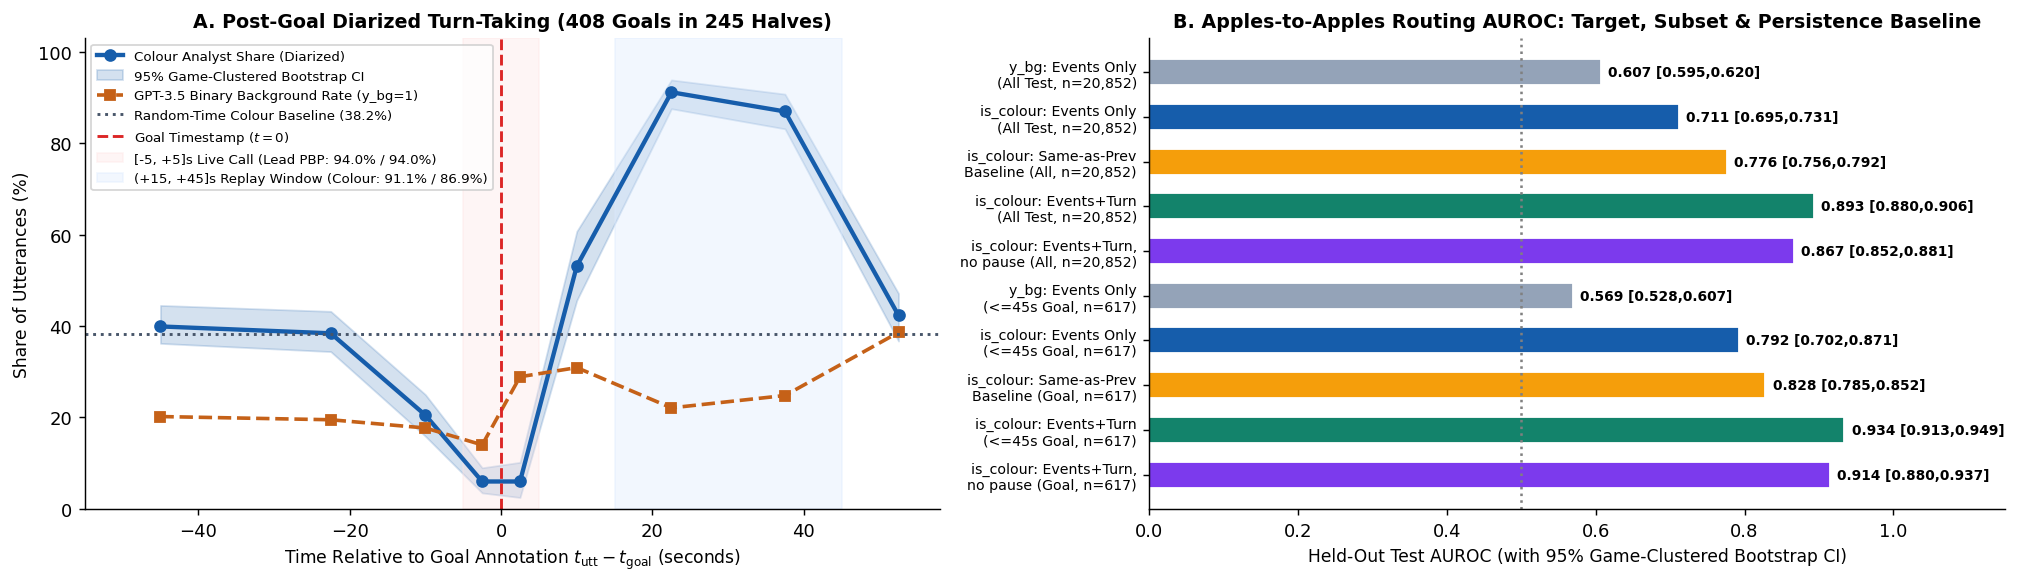

In [5]:
# STEP 4 EXECUTION: Recompute Diarized Speaker Roles, Post-Event Handoff Curves & Speaker Routing Benchmarks
en_full = splits_df[splits_df["language"] == "en"].dropna(subset=["half", "start", "end", "text"]).copy()
en_spk = splits_df[splits_df["language"] == "en"].dropna(subset=["half", "start", "end", "speaker", "付加的情報か", "text"]).copy()
en_spk["half"] = en_spk["half"].astype(int)
en_spk["n_words"] = en_spk["text"].str.split().str.len()
en_spk["dur"] = en_spk["end"] - en_spk["start"]
en_spk["y_bg"] = en_spk["付加的情報か"].astype(int)

# 4A. Out-of-goal speaker role assignment (excluding [-60s, +90s] around all Goals).
# A helper, because Step 6 rebuilds the same booth with the same rule.
def assign_booth_roles(utts, events_by_game, pre=60, post=90, min_second=20, short_words=4):
    """Return (top-2 speaker table with role/rk_utt/n_utt/n_short, set of valid (game, half))."""
    keep = []
    for (g, h), u in utts.groupby(["game", "half"]):
        if g not in events_by_game:
            continue
        gt = events_by_game[g].query('half == @h and label == "Goal"')["t"].to_numpy()
        m = np.ones(len(u), dtype=bool)
        for t0 in gt:
            m &= ~((u["start"].to_numpy() >= t0 - pre) & (u["start"].to_numpy() <= t0 + post))
        keep.append(u[m])
    ng = pd.concat(keep, ignore_index=True)
    st = ng.groupby(["game", "half", "speaker"]).agg(n_utt=("id", "size"), n_short=("n_words", lambda s: (s <= short_words).sum())).reset_index()
    st["rk_utt"] = st.groupby(["game", "half"])["n_utt"].rank(ascending=False, method="first").astype(int)
    top2 = st[st["rk_utt"].isin([1, 2])].copy()
    valid = set(top2[top2["rk_utt"] == 2].query("n_utt >= @min_second").set_index(["game", "half"]).index)
    top2 = top2[top2.set_index(["game", "half"]).index.isin(valid)].copy()
    top2["role"] = top2.groupby(["game", "half"])["n_short"].rank(ascending=False, method="first").map({1.0: "Lead_PBP", 2.0: "Colour_Analyst"})
    return top2, valid

top2_spk, valid_two_halves = assign_booth_roles(en_spk, events_dict)

en_in_valid_halves = en_spk[en_spk.set_index(["game", "half"]).index.isin(valid_two_halves)]
en2 = en_spk.merge(top2_spk[["game", "half", "speaker", "role"]], on=["game", "half", "speaker"])
en2["is_colour"] = (en2["role"] == "Colour_Analyst").astype(int)

# Cross-checks on out-of-window role assignment
first_utt_per_half = en2.sort_values("start").groupby(["game", "half"]).first()
n_first_is_lead = int((first_utt_per_half["role"] == "Lead_PBP").sum())
n_valid_halves = len(first_utt_per_half)

ko_is_lead = []
for (g, h), u in en2.sort_values("start").groupby(["game", "half"]):
    ko_t = events_dict[g].query('half == @h and label == "Kick-off"')["t"].to_numpy()
    t0 = ko_t[0] if len(ko_t) else 0.0
    sub_ko = u[(u["start"] >= t0 - 2) & (u["start"] <= t0 + 15)]
    if len(sub_ko):
        ko_is_lead.append(sub_ko.iloc[0]["role"] == "Lead_PBP")
n_ko_is_lead = int(sum(ko_is_lead))
n_ko_halves = len(ko_is_lead)
n_vol_is_lead = int((top2_spk[top2_spk["role"] == "Lead_PBP"]["rk_utt"] == 1).sum())

total_halves_en = en_spk.groupby(["game", "half"]).ngroups
excluded_halves = total_halves_en - n_valid_halves

print("=== 4A. Diarized Booth Filtering & Out-of-Window Role Assignment Audit ===")
print(f"Total English utterances (valid timestamps)    : {len(en_full):,} across {en_full['game'].nunique()} games ({total_halves_en} halves)")
print(f"Utterances with non-null speaker ID and label  : {len(en_spk):,} ({len(en_full) - len(en_spk):,} rows dropped: speaker or label is NaN)")
print(f"Two-speaker halves (2nd speaker >=20 ng turns) : {n_valid_halves} / {total_halves_en} halves ({excluded_halves} single/sparse halves excluded)")
print(f"Total utterances in the {n_valid_halves} two-speaker halves : {len(en_in_valid_halves):,} (Top-2 speaker pair = {len(en2):,} turns; 3rd+ diarized clusters = {len(en_in_valid_halves)-len(en2):,})")
print(f"Check 1 — Lead_PBP speaks 1st turn of half     : {n_first_is_lead} / {n_valid_halves} halves ({n_first_is_lead/n_valid_halves:.1%})")
print(f"Check 2 — Lead_PBP speaks 1st at Kick-off      : {n_ko_is_lead} / {n_ko_halves} halves ({n_ko_is_lead/n_ko_halves:.1%})")
print(f"Check 3 — Lead_PBP is #1 volume speaker in half: {n_vol_is_lead} / {n_valid_halves} halves ({n_vol_is_lead/n_valid_halves:.1%})")

# 4B. Recompute Three-Phase Event-Handoff Curves Around Goals & Other Events (500-iteration Game-Clustered Bootstrap)
rng4 = np.random.default_rng(42)
bins = [-60, -30, -15, -5, 0, 5, 15, 30, 45, 60]
handoff_rows = []
n_goals_two_voice = 0

for ev_type in ["Goal", "Foul", "Yellow card", "Shots on target", "Corner", "Substitution", "Random_Control"]:
    w_list = []
    for (g, h), u in en2.groupby(["game", "half"]):
        if ev_type == "Random_Control":
            ts = rng4.uniform(120, 2500, size=2)
        else:
            ts = events_dict[g].query("half == @h and label == @ev_type")["t"].to_numpy()
            if ev_type == "Goal":
                n_goals_two_voice += len(ts)
        for t0 in ts:
            sub = u[(u["start"] >= t0 - 60) & (u["start"] <= t0 + 60)].copy()
            sub["dt"] = sub["start"] - t0
            sub["win"] = pd.cut(sub["dt"], bins=bins)
            w_list.append(sub[["game", "win", "is_colour", "y_bg", "n_words", "dur", "role", "text", "dt"]])
    w = pd.concat(w_list, ignore_index=True).dropna(subset=["win"])
    if ev_type == "Goal":
        goal_window_utterances_df = w.copy()
    for win, grp in w.groupby("win", observed=True):
        ug = grp["game"].unique()
        idx = {g: grp.index[grp["game"] == g].to_numpy() for g in ug}
        col_vals = grp["is_colour"].to_numpy()
        bg_vals = grp["y_bg"].to_numpy()
        base = grp.index.to_numpy()
        pos = {k: np.searchsorted(base, v) for k, v in idx.items()}
        b_col, b_bg = [], []
        for _ in range(500):
            s = np.concatenate([pos[g] for g in rng4.choice(ug, len(ug))])
            b_col.append(col_vals[s].mean())
            b_bg.append(bg_vals[s].mean())
        c_lo, c_hi = np.percentile(b_col, [2.5, 97.5])
        nb_lo, nb_hi = np.percentile(b_bg, [2.5, 97.5])
        handoff_rows.append({
            "event": ev_type, "window_s": str(win), "n_utt": len(grp),
            "colour_share": round(float(grp["is_colour"].mean()), 3),
            "colour_ci": f"[{c_lo:.3f},{c_hi:.3f}]",
            "gpt_bg_rate": round(float(grp["y_bg"].mean()), 3),
            "gpt_bg_ci": f"[{nb_lo:.3f},{nb_hi:.3f}]",
            "median_words": float(grp["n_words"].median()),
            "median_dur_s": round(float(grp["dur"].median()), 2),
        })

handoff_df = pd.DataFrame(handoff_rows)
handoff_df.to_csv(f"{OUT_DIR}/table_two_voice_handoff_en.csv", index=False)

goal_handoff_tab = handoff_df[handoff_df["event"] == "Goal"].reset_index(drop=True)
ctrl_handoff_tab = handoff_df[handoff_df["event"] == "Random_Control"].reset_index(drop=True)
print(f"\n=== 4B. Recomputed Post-Goal Turn-Taking Table Across {n_goals_two_voice} Goals in {n_valid_halves} Two-Speaker Halves ===")
display(goal_handoff_tab)

# Peak Colour Analyst share across different event types in (+5s, +45s]
ev_peak_rows = []
for ev_t in ["Goal", "Yellow card", "Shots on target", "Foul", "Substitution", "Corner", "Random_Control"]:
    sub_ev = handoff_df[(handoff_df["event"] == ev_t) & (handoff_df["window_s"].isin(["(5, 15]", "(15, 30]", "(30, 45]"]))]
    peak_row = sub_ev.sort_values("colour_share", ascending=False).iloc[0]
    ev_peak_rows.append({
        "Event Type": ev_t,
        "Peak Window": peak_row["window_s"],
        "n_Utterances": int(peak_row["n_utt"]),
        "Colour_Analyst_Share": peak_row["colour_share"],
        "Colour_95CI": peak_row["colour_ci"],
        "GPT_Bg_Rate": peak_row["gpt_bg_rate"],
    })
ev_peak_df = pd.DataFrame(ev_peak_rows)
print("\n=== 4C. Peak Colour Analyst Share in (+5s, +45s] Across Event Types ===")
display(ev_peak_df)
print(f"Random-time control: unweighted mean Colour share across its {len(ctrl_handoff_tab)} windows = {ctrl_handoff_tab['colour_share'].mean():.3f}")

# 4D. Inspect random samples of what GPT-3.5 labels as y_bg=1 in (0, +5]s vs (+45, +60]s after Goals (Issue 9)
print("\n=== 4D. Audit of Utterances Labeled y_bg=1 by GPT-3.5 After Goals (Random Sample, seed=42) ===")
audit_samples = []
for win_str in ["(0, 5]", "(45, 60]"]:
    sub_w = goal_window_utterances_df[(goal_window_utterances_df["win"].astype(str) == win_str) & (goal_window_utterances_df["y_bg"] == 1)]
    print(f"Window {win_str}s (n_bg={len(sub_w)}): random sample of {min(10, len(sub_w))} utterances labeled y_bg=1:")
    for r in sub_w.sample(min(10, len(sub_w)), random_state=42).itertuples():
        print(f"  [dt={r.dt:+5.1f}s | {r.role:14s}] {r.text}")
    audit_samples.append(sub_w.sample(min(40, len(sub_w)), random_state=42).assign(window=win_str))
audit_path = f"{OUT_DIR}/audit_goal_window_ybg1_sample.csv"
pd.concat(audit_samples, ignore_index=True)[["window", "game", "dt", "role", "text"]].assign(hand_label="").to_csv(audit_path, index=False)
print(f"Exported up to 40 random y_bg=1 utterances per window for hand-labelling -> {os.path.basename(audit_path)} (share of reactions vs. recall NOT COMPUTED until labelled)")

# 4E. Train & Evaluate Speaker Routing & Handoff Models on Held-Out Test Split (With Persistence Baseline & Matching Subsets!)
rows4 = []
for (g, h), u in en2.sort_values("start").groupby(["game", "half"]):
    ev = events_dict[g]
    ev = ev[ev["half"] == h]
    et, el = ev["t"].to_numpy(), ev["label"].to_numpy()
    prev_end, prev_dur, prev_col, run_sec = np.nan, np.nan, np.nan, 0.0
    for r in u.itertuples():
        t = r.start
        m = et <= t
        f = {"half": h, "clock": t / 60.0}
        for c in CLASSES:
            tt = et[m & (el == c)]
            f["since_" + c] = min(t - tt[-1], CAP) if len(tt) else CAP
        f["min_since_any"] = min((t - et[m][-1]), CAP) if m.any() else CAP
        f["n_ev_60"] = int(((et > t - 60) & m).sum())
        f["n_ev_15"] = int(((et > t - 15) & m).sum())
        f["gap"] = t - prev_end if prev_end == prev_end else -1.0
        f["prev_dur"] = prev_dur if prev_dur == prev_dur else -1.0
        f["prev_colour"] = prev_col if prev_col == prev_col else -1.0
        f["run_sec"] = run_sec
        f.update(game=g, split=r.split, is_colour=r.is_colour, y_bg=r.y_bg)
        rows4.append(f)
        if prev_col == r.is_colour and (t - prev_end) < 10.0:
            run_sec += r.dur
        else:
            run_sec = r.dur
        prev_end, prev_dur, prev_col = r.end, r.dur, r.is_colour

feat4_df = pd.DataFrame(rows4)
tr4, va4, te4 = (feat4_df[feat4_df["split"] == s].copy() for s in ["train", "valid", "test"])
EV4 = ["half", "clock", "min_since_any", "n_ev_60", "n_ev_15"] + ["since_" + c for c in CLASSES]
TURN4 = EV4 + ["gap", "prev_dur", "prev_colour", "run_sec"]
TURN4_NOGAP = EV4 + ["prev_dur", "prev_colour", "run_sec"]  # ablation: drop the onset-dependent gap feature

clf_spk_ev = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4[EV4], tr4["is_colour"])
clf_spk_tu = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4[TURN4], tr4["is_colour"])
clf_bg_ev4 = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4[EV4], tr4["y_bg"])

te4["p_spk_ev"] = clf_spk_ev.predict_proba(te4[EV4])[:, 1]
te4["p_spk_tu"] = clf_spk_tu.predict_proba(te4[TURN4])[:, 1]
te4["p_bg_ev"] = clf_bg_ev4.predict_proba(te4[EV4])[:, 1]
te4["p_spk_persist"] = np.where(te4["prev_colour"] >= 0, te4["prev_colour"], tr4["is_colour"].mean())
clf_spk_tu_ng = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4[TURN4_NOGAP], tr4["is_colour"])
te4["p_spk_tu_nogap"] = clf_spk_tu_ng.predict_proba(te4[TURN4_NOGAP])[:, 1]

tr4_v = tr4[tr4["prev_colour"] >= 0].copy()
te4_v = te4[te4["prev_colour"] >= 0].copy()
tr4_v["switched"] = (tr4_v["is_colour"] != tr4_v["prev_colour"]).astype(int)
te4_v["switched"] = (te4_v["is_colour"] != te4_v["prev_colour"]).astype(int)
clf_sw_ev = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4_v[EV4], tr4_v["switched"])
clf_sw_tu = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4_v[TURN4], tr4_v["switched"])
te4_v["p_sw_ev"] = clf_sw_ev.predict_proba(te4_v[EV4])[:, 1]
te4_v["p_sw_tu"] = clf_sw_tu.predict_proba(te4_v[TURN4])[:, 1]
clf_sw_tu_ng = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(tr4_v[TURN4_NOGAP], tr4_v["switched"])
te4_v["p_sw_tu_nogap"] = clf_sw_tu_ng.predict_proba(te4_v[TURN4_NOGAP])[:, 1]

def boot_auc_ap_step4(df_sub, y_col, p_col, n_boot=200, seed=42):
    b_rng = np.random.default_rng(seed)
    games = df_sub["game"].unique()
    grouped = {g: df_sub[df_sub["game"] == g] for g in games}
    aucs, aps = [], []
    for _ in range(n_boot):
        sg = b_rng.choice(games, size=len(games), replace=True)
        sub = pd.concat([grouped[g] for g in sg], ignore_index=True)
        if sub[y_col].nunique() < 2:
            continue
        aucs.append(roc_auc_score(sub[y_col], sub[p_col]))
        aps.append(average_precision_score(sub[y_col], sub[p_col]))
    return (
        f"[{np.percentile(aucs, 2.5):.3f},{np.percentile(aucs, 97.5):.3f}]",
        f"[{np.percentile(aps, 2.5):.3f},{np.percentile(aps, 97.5):.3f}]"
    )

te4_goal45 = te4[te4["since_Goal"] <= 45].copy()
te4_shot45 = te4[te4["since_Shots on target"] <= 45].copy()

eval_specs4 = [
    ("y_bg (GPT Binary Bg)", "All 2-Voice Test Turns", te4, "y_bg", "p_bg_ev", "Events Only (HGB)"),
    ("y_bg (GPT Binary Bg)", "<=45s After Goal", te4_goal45, "y_bg", "p_bg_ev", "Events Only (HGB)"),
    ("is_colour (Speaker Role)", "All 2-Voice Test Turns", te4, "is_colour", "p_spk_persist", "Baseline: Same Speaker as Prev Turn"),
    ("is_colour (Speaker Role)", "All 2-Voice Test Turns", te4, "is_colour", "p_spk_ev", "Events Only (HGB)"),
    ("is_colour (Speaker Role)", "All 2-Voice Test Turns", te4, "is_colour", "p_spk_tu", "Events + Turn State (HGB)"),
    ("is_colour (Speaker Role)", "<=45s After Goal", te4_goal45, "is_colour", "p_spk_persist", "Baseline: Same Speaker as Prev Turn"),
    ("is_colour (Speaker Role)", "<=45s After Goal", te4_goal45, "is_colour", "p_spk_ev", "Events Only (HGB)"),
    ("is_colour (Speaker Role)", "<=45s After Goal", te4_goal45, "is_colour", "p_spk_tu", "Events + Turn State (HGB)"),
    ("is_colour (Speaker Role)", "<=45s After Shot on Target", te4_shot45, "is_colour", "p_spk_ev", "Events Only (HGB)"),
    ("switched (Speaker Handoff)", "All 2-Voice Test Turns (t>1)", te4_v, "switched", "p_sw_ev", "Events Only (HGB)"),
    ("switched (Speaker Handoff)", "All 2-Voice Test Turns (t>1)", te4_v, "switched", "p_sw_tu", "Events + Turn State (HGB)"),
    # Ablation rows (appended last so the figure's row indices are unchanged)
    ("is_colour (Speaker Role)", "All 2-Voice Test Turns", te4, "is_colour", "p_spk_tu_nogap", "Events + Turn State w/o gap (HGB, ablation)"),
    ("is_colour (Speaker Role)", "<=45s After Goal", te4_goal45, "is_colour", "p_spk_tu_nogap", "Events + Turn State w/o gap (HGB, ablation)"),
    ("switched (Speaker Handoff)", "All 2-Voice Test Turns (t>1)", te4_v, "switched", "p_sw_tu_nogap", "Events + Turn State w/o gap (HGB, ablation)"),
]

spk_res_rows = []
for tgt, subset_name, d_sub, y_c, p_c, m_name in eval_specs4:
    auc_ci, ap_ci = boot_auc_ap_step4(d_sub, y_c, p_c)
    spk_res_rows.append({
        "target": tgt,
        "subset": subset_name,
        "model": m_name,
        "n": len(d_sub),
        "pos_rate": round(float(d_sub[y_c].mean()), 3),
        "auroc": round(float(roc_auc_score(d_sub[y_c], d_sub[p_c])), 4),
        "auroc_ci": auc_ci,
        "ap": round(float(average_precision_score(d_sub[y_c], d_sub[p_c])), 4),
        "ap_ci": ap_ci,
    })

spk_routing_df = pd.DataFrame(spk_res_rows)
spk_routing_df.to_csv(f"{OUT_DIR}/table_speaker_routing_en.csv", index=False)
print(f"\nFeature counts: Events Only (EV4) = {len(EV4)}, Events + Turn State = {len(TURN4)}, Events + Turn State w/o gap = {len(TURN4_NOGAP)}")
print(f"\n=== 4E. Held-Out Test Benchmark: Matching Subsets & Persistence Baselines ({te4['game'].nunique()} Test Games) ===")
display(spk_routing_df)

# Visualization 4: 2-Panel Plot of Post-Goal Turn-Taking Curve & Matching-Subset Routing AUROCs
fig, axes = plt.subplots(1, 2, figsize=(15.8, 4.6))

# Panel A: Post-goal trajectory across [-60s, +60s]
win_centers = np.array([-45.0, -22.5, -10.0, -2.5, 2.5, 10.0, 22.5, 37.5, 52.5])
col_shares = goal_handoff_tab["colour_share"].to_numpy() * 100
bg_shares = goal_handoff_tab["gpt_bg_rate"].to_numpy() * 100
ctrl_mean = ctrl_handoff_tab["colour_share"].mean() * 100

col_ci_lo = np.array([float(s.strip("[]").split(",")[0]) * 100 for s in goal_handoff_tab["colour_ci"]])
col_ci_hi = np.array([float(s.strip("[]").split(",")[1]) * 100 for s in goal_handoff_tab["colour_ci"]])

axes[0].plot(win_centers, col_shares, "-o", color="#165DAB", linewidth=2.4, markersize=6, label="Colour Analyst Share (Diarized)")
axes[0].fill_between(win_centers, col_ci_lo, col_ci_hi, color="#165DAB", alpha=0.18, label="95% Game-Clustered Bootstrap CI")
axes[0].plot(win_centers, bg_shares, "--s", color="#C56118", linewidth=2.0, markersize=5.5, label="GPT-3.5 Binary Background Rate (y_bg=1)")
axes[0].axhline(ctrl_mean, color="#475569", linestyle=":", linewidth=1.6, label=f"Random-Time Colour Baseline ({ctrl_mean:.1f}%)")
axes[0].axvline(0, color="#DC2626", linestyle="--", linewidth=1.6, label="Goal Timestamp ($t=0$)")
axes[0].axvspan(-5, 5, color="#FEE2E2", alpha=0.32, label=f"[-5, +5]s Live Call (Lead PBP: {100-col_shares[3]:.1f}% / {100-col_shares[4]:.1f}%)")
axes[0].axvspan(15, 45, color="#DBEAFE", alpha=0.35, label=f"(+15, +45]s Replay Window (Colour: {col_shares[6]:.1f}% / {col_shares[7]:.1f}%)")
axes[0].set_xlim(-55, 58)
axes[0].set_ylim(0, 103)
axes[0].set_xlabel("Time Relative to Goal Annotation $t_{\\mathrm{utt}} - t_{\\mathrm{goal}}$ (seconds)")
axes[0].set_ylabel("Share of Utterances (%)")
axes[0].set_title(f"A. Post-Goal Diarized Turn-Taking ({n_goals_two_voice} Goals in {n_valid_halves} Halves)")
axes[0].legend(loc="upper left", fontsize=7.4, ncol=1)

# Panel B: Apples-to-apples AUROC comparison on All Test Turns vs <=45s Post-Goal
n_all4, n_goal4 = len(te4), len(te4_goal45)
labels_b = [
    f"y_bg: Events Only\n(All Test, n={n_all4:,})",
    f"is_colour: Events Only\n(All Test, n={n_all4:,})",
    f"is_colour: Same-as-Prev\nBaseline (All, n={n_all4:,})",
    f"is_colour: Events+Turn\n(All Test, n={n_all4:,})",
    f"is_colour: Events+Turn,\nno pause (All, n={n_all4:,})",
    f"y_bg: Events Only\n(<=45s Goal, n={n_goal4:,})",
    f"is_colour: Events Only\n(<=45s Goal, n={n_goal4:,})",
    f"is_colour: Same-as-Prev\nBaseline (Goal, n={n_goal4:,})",
    f"is_colour: Events+Turn\n(<=45s Goal, n={n_goal4:,})",
    f"is_colour: Events+Turn,\nno pause (Goal, n={n_goal4:,})",
]
indices_b = [0, 3, 2, 4, 11, 1, 6, 5, 7, 12]   # rows 11-12 are the no-pause ablation (live-feasible)
aurocs_b = [spk_routing_df.loc[idx, "auroc"] for idx in indices_b]
colors_b = ["#94A3B8", "#165DAB", "#F59E0B", "#13836B", "#7C3AED", "#94A3B8", "#165DAB", "#F59E0B", "#13836B", "#7C3AED"]

y_b = np.arange(len(labels_b))
bars4 = axes[1].barh(y_b, aurocs_b, color=colors_b, height=0.58, edgecolor="white")
axes[1].axvline(0.50, color="gray", linestyle=":", linewidth=1.4, label="Chance (0.50)")
for bar, idx in zip(bars4, indices_b):
    row_b = spk_routing_df.loc[idx]
    axes[1].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f"{row_b['auroc']:.3f} {row_b['auroc_ci']}", va="center", fontsize=7.6, fontweight="bold")
axes[1].set_yticks(y_b)
axes[1].set_yticklabels(labels_b, fontsize=7.8)
axes[1].set_xlim(0, 1.15)
axes[1].invert_yaxis()
axes[1].set_xlabel("Held-Out Test AUROC (with 95% Game-Clustered Bootstrap CI)")
axes[1].set_title("B. Apples-to-Apples Routing AUROC: Target, Subset & Persistence Baseline")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_step4_two_voice_handoff.png", bbox_inches="tight")
plt.show()


### Results [OBSERVED]

**4A. Booth coverage and role checks.**
- 245 of 262 English halves (93.5%) have a two-speaker booth. They contain 103,229 utterances: 99,800 from the main pair and 3,429 from minor diarized clusters.
- 109,931 English utterances have both a speaker ID and a label (948 dropped).
- The Lead PBP label agrees with who speaks first in the half in 218 of 245 halves (89.0%), with who speaks first at kick-off in 216 (88.2%) and with who speaks most in 230 (93.9%).
- These checks are not independent. The last is close to circular, because the speaker with more short utterances usually has more utterances overall, and the first two test nearly the same moment.

**4B. Colour analyst's share around 408 goals.**

| Window (s from goal) | −60 to −30 | −15 to −5 | −5 to 0 | 0 to +5 | +5 to +15 | +15 to +30 | +30 to +45 | +45 to +60 |
|---|---|---|---|---|---|---|---|---|
| Colour share | 0.399 | 0.205 | 0.060 | 0.060 | 0.531 | **0.911** | 0.869 | 0.423 |
| 95% CI | [0.362, 0.445] | [0.159, 0.250] | [0.035, 0.090] | [0.025, 0.102] | [0.456, 0.607] | [0.875, 0.938] | [0.831, 0.907] | [0.367, 0.471] |
| Utterances | 1,835 | 628 | 414 | 249 | 540 | 1,143 | 1,036 | 860 |
| GPT-3.5 "background" rate | 0.202 | 0.177 | 0.140 | 0.289 | 0.309 | 0.221 | 0.248 | 0.386 |

Random-time control: the colour share averages 0.382 across its 9 windows (peak 0.408). The pattern has three phases:
1. **Live call (±5 s):** the Lead PBP speaks 94% of utterances, in short bursts (median 6 words).
2. **Replay breakdown (+15 to +45 s):** the Colour Analyst takes over, with 87–91% of utterances.
3. **Walk-back (+45 to +60 s):** the balance returns toward normal, and the GPT-3.5 "background" rate peaks at 0.386.

**4C. Other events.** The colour share peaks earlier, at +5 to +15 s, after yellow cards (0.738 [0.689, 0.783]), shots on target (0.653 [0.619, 0.689]) and fouls (0.603 [0.576, 0.628]). After substitutions it stays below the random control (peak 0.338).

**4D. What GPT-3.5 calls "background" around goals.** The label is also common in the first 5 s after a goal (0.289). The printed random sample mixes immediate reactions and score updates (*"West Ham in front."*, *"Squeeze it in for the equaliser."*, *"What a strike from Matic!"*) with genuine background (*"He brings up his half century of goals for the club…"*). The share of reactions is NOT COMPUTED until the exported sample (`audit_goal_window_ybg1_sample.csv`, up to 40 per window) is hand-labeled.

**4E. Prediction on the same 25 test games (AUROC with 95% CI).**

| Target | Model | All test turns | ≤ 45 s after a goal |
|---|---|---|---|
| GPT-3.5 label `y_bg` | Events only | 0.6066 [0.595, 0.620] | 0.5690 [0.528, 0.607] |
| Speaker role `is_colour` | Same speaker as previous turn | 0.7763 [0.756, 0.792] | 0.8279 [0.785, 0.852] |
| | Events only | 0.7113 [0.695, 0.731] | 0.7921 [0.702, 0.871] |
| | Events + turn state | 0.8929 [0.880, 0.906] | 0.9344 [0.913, 0.949] |
| | Events + turn state, no pause | **0.8665 [0.852, 0.881]** | **0.9145 [0.880, 0.937]** |
| Speaker change `switched` | Events only | 0.5879 [0.577, 0.602] | — |
| | Events + turn state | 0.8162 [0.799, 0.834] | — |
| | Events + turn state, no pause | 0.7624 [0.749, 0.776] | — |

Figure B shows the "no pause" rows in purple, because they are the ones a live system could actually use. All test turns: n = 20,852 (20,802 for `switched`). After goals: n = 617. Positive rates: `y_bg` 0.196, `is_colour` 0.368, `switched` 0.208.

- With the same 22 event features on the same turns, **the speaker role is far more predictable than the GPT-3.5 label**: 0.71 vs 0.61 overall, and 0.79 vs 0.57 after goals.
- Speakers keep talking: consecutive turns share a speaker 79.2% of the time, so "same as before" is already a strong baseline (0.776).
- Without the onset-dependent pause, turn state still adds +0.090 AUROC over that baseline (0.8665 vs 0.7763). That is 77% of the gain made with the pause (+0.117).
- For predicting **speaker changes**, the pause matters more: without it, AUROC drops from 0.816 to 0.762 and AP from 0.614 to 0.470.

### Design implications [INFERRED]
1. **Route by voice first.** Who speaks next is predictable from events and turn state alone, without hearing any words.
2. **The colour analyst has lead time.** After a goal the colour share stays at 6% for 5 s and reaches 53% only at +5 to +15 s. The system can start preparing the replay breakdown the moment the goal is confirmed and still be on time; the PBP call is the only truly time-critical output.
3. **A small CPU model is enough for routing.** Gradient-boosted trees already reach these scores.
4. **Speaker changes depend on pauses**, which a live system must predict rather than observe. This is why Step 8 moves to a continuous time grid that uses only the silence so far.

### Caveats
- Diarization and roles are unvalidated (Exp 1 includes a listening audit).
- All scores are onset-conditioned.
- The post-goal subset is small (617 turns), so its CIs are wide.

---
## Step 5 — Event timing and camera visibility

**Questions.**
1. **Event collisions (500 SoccerNet-v2 games, 110,458 events).** How often does a goal, penalty or card follow another event within 2 s? Are these exact co-annotations (the same timestamp) or genuine sequences (for example, a shot followed 0.6 s later by a goal)?
2. **Camera visibility (PFF World Cup 2022, 200 frames from one match).** Broadcast cameras follow the ball, so tracking providers flag each player as `VISIBLE` or `ESTIMATED` (off-camera and extrapolated). How many players are visible, and how much would tactical geometry change if a system used only the visible ones?

**Why it matters.**
- Collisions decide how the event coalescer should merge events and how long it must wait.
- Visibility decides when tactical claims need hedging.

**Method.**
- **Collisions.** For each event, compute the time since the previous event in the same half. Report exact co-annotations (0 s) separately from 0–2 s sequences, and identify the most common preceding event.
- **Visibility.** On a 105 × 68 m pitch at 0.5 m resolution, compute each player's Voronoi area (the region closer to them than to anyone else), first with all players and then with visible players only. Removing players can only enlarge the remaining players' areas. This is a **worst case**: it mimics a camera-only detector with no off-camera extrapolation.
- **Delayed-live clock.** Holding events for up to 2 s to merge Shot → Goal adds up to 2 s of delay. A sub-second audio target therefore only makes sense measured from the moment an event is *released*, with the video played back at a matching delay.


=== 5A. Recomputed Inter-Event Collision Summary Across 500 SoccerNet-v2 Games (110,458 Events) ===


,target_event,n_events,frac_eq_0s_coannot,frac_gt0_le_2s,frac_prev_le_1s,frac_prev_le_2s,frac_prev_le_5s,frac_prev_le_10s,dominant_preceding_event,dom_share_all_lags,dom_share_le_2s,median_lag_from_dominant_s
0,Goal,1703,0.001,0.907,0.788,0.908,0.920,0.928,Shots on target,0.838,0.825,0.61
1,Penalty,173,0.387,0.081,0.468,0.468,0.468,0.468,Shots on target,0.405,0.405,0.00
2,Yellow card,2047,0.001,0.030,0.015,0.032,0.209,0.685,Foul,0.850,0.008,7.14
3,Red card,55,0.000,0.018,0.018,0.018,0.236,0.709,Foul,0.800,0.000,6.77
4,Corner,4836,0.000,0.001,0.001,0.001,0.005,0.038,Ball out of play,0.961,0.000,24.78
5,Substitution,2839,0.023,0.020,0.034,0.043,0.058,0.089,Ball out of play,0.510,0.001,29.36


Goal Collision Breakdown (n = 1,703 goals):
  - Preceded by ANY event at dt == 0.00s (simultaneous)        : 2 / 1703 (0.12%)
  - Preceded by ANY event at 0.00s < dt <= 2.00s (sequential)  : 1,545 / 1,703 (90.72%)
  - Preceded by ANY event at 0.00s <= dt <= 2.00s (total <=2s) : 1,547 / 1,703 (90.84%)
  - Preceded specifically by 'Shots on target' (any lag)       : 1,427 / 1,703 (83.79%, median lag = 0.61s)
  - Preceded specifically by 'Shots on target' within <= 2.00s : 1,405 / 1,703 (82.50%)
  - Of the 1,427 Shot->Goal pairs, lag <= 2.00s          : 1,405 / 1,427 (98.46%)
Penalty (n = 173; with a preceding event = 173): dt == 0s: 67 (38.73%); 0 < dt <= 2s: 14 (8.09%); dt <= 2s: 46.82%; dt <= 10s: 46.82%
Yellow card (n = 2,047; with a preceding event = 2,046): dt == 0s: 3 (0.15%); 0 < dt <= 2s: 62 (3.03%); dt <= 2s: 3.18%; dt <= 10s: 68.52%



=== 5B. PFF World Cup 2022 Sample Visibility & Voronoi Audit (Game 10517, 200 Frames) ===
All 200 frames (including 59 zero-visible camera-cut/replay frames):
  - Mean tracked players = 21.89; Mean VISIBLE = 12.16 (55.3% of 22)
Active pitch frames with >=1 VISIBLE player (n = 141 frames):
  - Mean VISIBLE = 17.25 / 22 (78.4%), Median = 19.0, Range = [11, 20]
  - Per-frame mean Voronoi area inflation when ESTIMATED players are dropped: mean = +255.4%, median = +70.7%
  - Pooled visible player-frames (n = 2,432): mean = +200.9%, median = +2.4%, IQR = [+0.0%, +50.2%]

=== 5C. Illustrative Frame idx=100 (frameNum=197541): 19 Visible + 3 Off-Camera Estimated ===
Frame 100 visible-player Voronoi inflation: mean = +30.3%, max = +233.1%
Frame 100's mean inflation sits at the 10% percentile of active frames (per-frame median = +70.7%) -> illustrative, not representative


,team,jersey,x,y,voronoi_all22_m2,voronoi_vis_only_m2,space_inflation_pct
12,Away (FRA),5,-30.8,-3.3,197.0,656.2,233.1
10,Home (ARG),4,20.8,6.8,787.8,2285.0,190.1
14,Away (FRA),8,-18.0,2.8,54.2,83.0,53.0
11,Away (FRA),4,-27.3,-6.8,211.8,288.5,36.2
15,Away (FRA),18,-24.1,12.0,581.5,751.2,29.2
9,Home (ARG),8,-0.2,-8.7,566.2,670.2,18.4



=== 5D. SkillCorner Sample Match 1925299 (483 Phase Rows, 5,222 Dynamic Events; 1 of 10 Public Repo Matches; context only, not used in any conclusion) ===


,n_phases,time_share_pct,lead_to_shot_rate,lead_to_goal_rate
team_out_of_possession_phase_type,,,,
medium_block,160,37.6,0.106,0.006
low_block,95,27.9,0.189,0.011
high_block,66,15.8,0.061,0.015
chaotic,96,9.2,0.000,0.000
defending_direct,42,3.8,0.071,0.024
defending_quick_break,9,2.7,0.667,0.000
defending_set_play,13,2.2,0.308,0.000
defending_transition,2,0.7,0.000,0.000


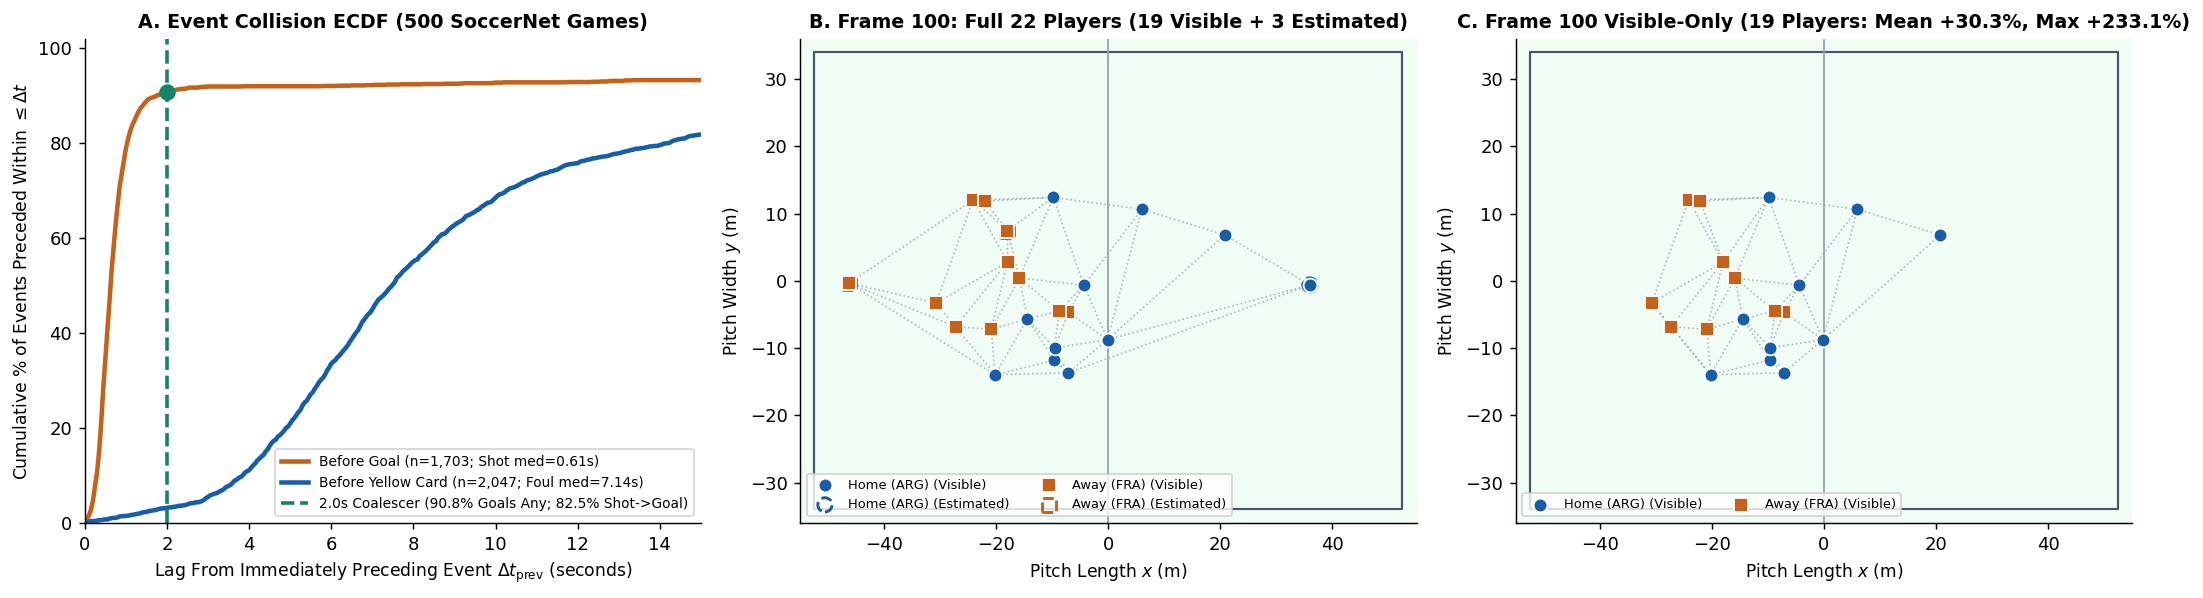

In [6]:
# STEP 5 EXECUTION: Recompute 500-Game Event Collisions, PFF 200-Frame Visibility/Voronoi & SkillCorner Sample Audit

# 5A. Recompute inter-event collision table directly from all 500 SoccerNet-v2 Labels-v2.json files
all_sn_files = sorted(glob.glob(f"{SN_LABELS_DIR}/**/Labels-v2.json", recursive=True))
ev_records = []
for f in all_sn_files:
    g = f[len(SN_LABELS_DIR)+1:-len("/Labels-v2.json")]
    for a in json.load(open(f))["annotations"]:
        ev_records.append({
            "game": g,
            "half": int(a["gameTime"].split(" - ")[0]),
            "t": int(a["position"]) / 1000.0,
            "label": a["label"]
        })
edf_all = pd.DataFrame(ev_records).sort_values(["game", "half", "t"]).reset_index(drop=True)
edf_all["prev_t"] = edf_all.groupby(["game", "half"])["t"].shift(1)
edf_all["prev_label"] = edf_all.groupby(["game", "half"])["label"].shift(1)
edf_all["dt_prev"] = edf_all["t"] - edf_all["prev_t"]

coll_rows = []
for tgt in ["Goal", "Penalty", "Yellow card", "Red card", "Corner", "Substitution"]:
    sub = edf_all[edf_all["label"] == tgt].dropna(subset=["dt_prev"])
    dom = sub["prev_label"].value_counts().index[0]
    dom_sub = sub[sub["prev_label"] == dom]
    coll_rows.append({
        "target_event": tgt,
        "n_events": len(edf_all[edf_all["label"] == tgt]),
        "frac_eq_0s_coannot": round(float((sub["dt_prev"] == 0.0).mean()), 3),
        "frac_gt0_le_2s": round(float(((sub["dt_prev"] > 0.0) & (sub["dt_prev"] <= 2.0)).mean()), 3),
        "frac_prev_le_1s": round(float((sub["dt_prev"] <= 1.0).mean()), 3),
        "frac_prev_le_2s": round(float((sub["dt_prev"] <= 2.0).mean()), 3),
        "frac_prev_le_5s": round(float((sub["dt_prev"] <= 5.0).mean()), 3),
        "frac_prev_le_10s": round(float((sub["dt_prev"] <= 10.0).mean()), 3),
        "dominant_preceding_event": dom,
        "dom_share_all_lags": round(float((sub["prev_label"] == dom).mean()), 3),
        "dom_share_le_2s": round(float(((sub["prev_label"] == dom) & (sub["dt_prev"] <= 2.0)).mean()), 3),
        "median_lag_from_dominant_s": round(float(dom_sub["dt_prev"].median()), 2),
    })

collisions_df = pd.DataFrame(coll_rows)
collisions_df.to_csv(f"{OUT_DIR}/table_event_collisions_500games.csv", index=False)

goal_sub_coll = edf_all[edf_all["label"] == "Goal"].dropna(subset=["dt_prev"])
n_goals_500 = len(edf_all[edf_all["label"] == "Goal"])
n_goal_eq0 = int((goal_sub_coll["dt_prev"] == 0.0).sum())
n_goal_gt0_le2 = int(((goal_sub_coll["dt_prev"] > 0.0) & (goal_sub_coll["dt_prev"] <= 2.0)).sum())
n_goal_le2 = int((goal_sub_coll["dt_prev"] <= 2.0).sum())
n_goal_from_shot_all = int((goal_sub_coll["prev_label"] == "Shots on target").sum())
n_goal_from_shot_le2 = int(((goal_sub_coll["prev_label"] == "Shots on target") & (goal_sub_coll["dt_prev"] <= 2.0)).sum())
med_shot_to_goal = float(goal_sub_coll[goal_sub_coll["prev_label"] == "Shots on target"]["dt_prev"].median())

yc_sub_coll = edf_all[edf_all["label"] == "Yellow card"].dropna(subset=["dt_prev"])
n_yc_500 = len(edf_all[edf_all["label"] == "Yellow card"])
med_foul_to_yc = float(yc_sub_coll[yc_sub_coll["prev_label"] == "Foul"]["dt_prev"].median())

print(f"=== 5A. Recomputed Inter-Event Collision Summary Across {edf_all['game'].nunique()} SoccerNet-v2 Games ({len(edf_all):,} Events) ===")
display(collisions_df)
print(f"Goal Collision Breakdown (n = {n_goals_500:,} goals):")
print(f"  - Preceded by ANY event at dt == 0.00s (simultaneous)        : {n_goal_eq0} / {n_goals_500} ({n_goal_eq0/n_goals_500:.2%})")
print(f"  - Preceded by ANY event at 0.00s < dt <= 2.00s (sequential)  : {n_goal_gt0_le2:,} / {n_goals_500:,} ({n_goal_gt0_le2/n_goals_500:.2%})")
print(f"  - Preceded by ANY event at 0.00s <= dt <= 2.00s (total <=2s) : {n_goal_le2:,} / {n_goals_500:,} ({n_goal_le2/n_goals_500:.2%})")
print(f"  - Preceded specifically by 'Shots on target' (any lag)       : {n_goal_from_shot_all:,} / {n_goals_500:,} ({n_goal_from_shot_all/n_goals_500:.2%}, median lag = {med_shot_to_goal:.2f}s)")
print(f"  - Preceded specifically by 'Shots on target' within <= 2.00s : {n_goal_from_shot_le2:,} / {n_goals_500:,} ({n_goal_from_shot_le2/n_goals_500:.2%})")
print(f"  - Of the {n_goal_from_shot_all:,} Shot->Goal pairs, lag <= 2.00s          : {n_goal_from_shot_le2:,} / {n_goal_from_shot_all:,} ({n_goal_from_shot_le2/n_goal_from_shot_all:.2%})")
for tgt_det in ["Penalty", "Yellow card"]:
    s_det = edf_all[edf_all["label"] == tgt_det].dropna(subset=["dt_prev"])
    n_det = int((edf_all["label"] == tgt_det).sum())
    eq0, seq2 = s_det["dt_prev"] == 0.0, (s_det["dt_prev"] > 0.0) & (s_det["dt_prev"] <= 2.0)
    print(f"{tgt_det} (n = {n_det:,}; with a preceding event = {len(s_det):,}): dt == 0s: {int(eq0.sum())} ({eq0.mean():.2%}); "
          f"0 < dt <= 2s: {int(seq2.sum())} ({seq2.mean():.2%}); dt <= 2s: {(s_det['dt_prev'] <= 2.0).mean():.2%}; dt <= 10s: {(s_det['dt_prev'] <= 10.0).mean():.2%}")

goal_lags_prev = goal_sub_coll["dt_prev"].to_numpy()
yc_lags_prev = yc_sub_coll["dt_prev"].to_numpy()

# 5B & 5C. PFF FIFA World Cup 2022 Tracking Visibility & Voronoi Inflation Across ALL 200 Sample Frames
pff_frames = [json.loads(line) for line in open(PFF_SAMPLE)]
gx, gy = np.meshgrid(np.arange(-52.25, 52.5, 0.5), np.arange(-33.75, 34.0, 0.5))
grid_pts = np.column_stack([gx.ravel(), gy.ravel()])
cell_area = 0.25

frame_vor_records = []
pooled_player_inflations = []

for idx_f, fr in enumerate(pff_frames):
    hp = fr.get("homePlayersSmoothed") or []
    ap = fr.get("awayPlayersSmoothed") or []
    pts_all, vis_mask = [], []
    for p in hp + ap:
        if p.get("x") is not None and p.get("y") is not None:
            pts_all.append([float(p["x"]), float(p["y"])])
            vis_mask.append(p.get("visibility") == "VISIBLE")
    n_tot = len(pts_all)
    n_vis = int(sum(vis_mask))
    mean_inf, med_inf, max_inf = np.nan, np.nan, np.nan
    if n_tot >= 20 and n_vis >= 4:
        xy_all = np.array(pts_all)
        vm = np.array(vis_mask, dtype=bool)
        d_all = np.linalg.norm(grid_pts[:, None, :] - xy_all[None, :, :], axis=2)
        own_all = d_all.argmin(axis=1)
        area_all = np.array([(own_all == i).sum() * cell_area for i in range(n_tot)])

        vis_indices = np.where(vm)[0]
        xy_vis = xy_all[vis_indices]
        d_vis = np.linalg.norm(grid_pts[:, None, :] - xy_vis[None, :, :], axis=2)
        own_vis = vis_indices[d_vis.argmin(axis=1)]
        area_vis = np.array([(own_vis == i).sum() * cell_area for i in vis_indices])
        area_all_vis = area_all[vis_indices]
        inf_pct = (area_vis - area_all_vis) / np.maximum(area_all_vis, 1e-6) * 100.0
        mean_inf = float(np.mean(inf_pct))
        med_inf = float(np.median(inf_pct))
        max_inf = float(np.max(inf_pct))
        pooled_player_inflations.extend(inf_pct.tolist())
    frame_vor_records.append({
        "idx": idx_f, "frameNum": fr["frameNum"],
        "n_tot": n_tot, "n_vis": n_vis, "n_est": n_tot - n_vis,
        "mean_inf_pct": mean_inf, "med_inf_pct": med_inf, "max_inf_pct": max_inf
    })

pff_vis_df = pd.DataFrame(frame_vor_records)
n_zero_vis = int((pff_vis_df["n_vis"] == 0).sum())
active_pff = pff_vis_df[pff_vis_df["n_vis"] > 0].copy()

print(f"\n=== 5B. PFF World Cup 2022 Sample Visibility & Voronoi Audit (Game 10517, {len(pff_vis_df)} Frames) ===")
print(f"All {len(pff_vis_df)} frames (including {n_zero_vis} zero-visible camera-cut/replay frames):")
print(f"  - Mean tracked players = {pff_vis_df['n_tot'].mean():.2f}; Mean VISIBLE = {pff_vis_df['n_vis'].mean():.2f} ({pff_vis_df['n_vis'].mean()/22:.1%} of 22)")
print(f"Active pitch frames with >=1 VISIBLE player (n = {len(active_pff)} frames):")
print(f"  - Mean VISIBLE = {active_pff['n_vis'].mean():.2f} / 22 ({active_pff['n_vis'].mean()/22:.1%}), Median = {active_pff['n_vis'].median():.1f}, Range = [{active_pff['n_vis'].min()}, {active_pff['n_vis'].max()}]")
print(f"  - Per-frame mean Voronoi area inflation when ESTIMATED players are dropped: mean = +{active_pff['mean_inf_pct'].mean():.1f}%, median = +{active_pff['mean_inf_pct'].median():.1f}%")
print(f"  - Pooled visible player-frames (n = {len(pooled_player_inflations):,}): mean = +{np.mean(pooled_player_inflations):.1f}%, median = +{np.median(pooled_player_inflations):.1f}%, IQR = [+{np.percentile(pooled_player_inflations, 25):.1f}%, +{np.percentile(pooled_player_inflations, 75):.1f}%]")

# Detailed inspection of Frame index 100
fr0_idx = 100
fr0 = pff_frames[fr0_idx]
players_f0 = []
for team_label, plist in [("Home (ARG)", fr0["homePlayersSmoothed"]), ("Away (FRA)", fr0["awayPlayersSmoothed"])]:
    for p in plist:
        players_f0.append({
            "team": team_label, "jersey": int(p["jerseyNum"]),
            "x": float(p["x"]), "y": float(p["y"]),
            "vis": p["visibility"] == "VISIBLE"
        })
pf0 = pd.DataFrame(players_f0)
all_xy0 = pf0[["x", "y"]].to_numpy()
d_all0 = np.linalg.norm(grid_pts[:, None, :] - all_xy0[None, :, :], axis=2)
owner_all0 = d_all0.argmin(axis=1)
pf0["voronoi_all22_m2"] = [(owner_all0 == i).sum() * cell_area for i in range(len(pf0))]

vis_idx0 = pf0.index[pf0["vis"]].to_numpy()
vis_xy0 = pf0.loc[vis_idx0, ["x", "y"]].to_numpy()
d_vis0 = np.linalg.norm(grid_pts[:, None, :] - vis_xy0[None, :, :], axis=2)
owner_vis0 = vis_idx0[d_vis0.argmin(axis=1)]
pf0["voronoi_vis_only_m2"] = [(owner_vis0 == i).sum() * cell_area if i in vis_idx0 else np.nan for i in range(len(pf0))]
pf0["space_inflation_pct"] = ((pf0["voronoi_vis_only_m2"] - pf0["voronoi_all22_m2"]) / pf0["voronoi_all22_m2"] * 100).round(1)

f0_n_vis = int(pf0["vis"].sum())
f0_n_est = int((~pf0["vis"]).sum())
f0_mean_inf = float(pf0.loc[pf0["vis"], "space_inflation_pct"].mean())
f0_max_inf = float(pf0.loc[pf0["vis"], "space_inflation_pct"].max())

print(f"\n=== 5C. Illustrative Frame idx={fr0_idx} (frameNum={fr0['frameNum']}): {f0_n_vis} Visible + {f0_n_est} Off-Camera Estimated ===")
print(f"Frame {fr0_idx} visible-player Voronoi inflation: mean = +{f0_mean_inf:.1f}%, max = +{f0_max_inf:.1f}%")
f0_pct_rank = float((active_pff["mean_inf_pct"].dropna() < f0_mean_inf).mean())
print(f"Frame {fr0_idx}'s mean inflation sits at the {f0_pct_rank:.0%} percentile of active frames (per-frame median = +{active_pff['mean_inf_pct'].median():.1f}%) -> illustrative, not representative")
display(pf0[pf0["vis"]].sort_values("space_inflation_pct", ascending=False)[["team", "jersey", "x", "y", "voronoi_all22_m2", "voronoi_vis_only_m2", "space_inflation_pct"]].head(6).round(1))

# 5D. SkillCorner Sample Match Audit (1 Sample Match in Local CSVs; 10 A-League Matches in Public Repo)
if os.path.exists(SKC_POP) and os.path.exists(SKC_DE):
    pop_df = pd.read_csv(SKC_POP)
    de_df = pd.read_csv(SKC_DE)
    skc_match_id = int(pop_df["match_id"].iloc[0])
    phase_tab = pop_df.groupby("team_out_of_possession_phase_type").agg(
        n_phases=("index", "size"),
        total_duration_s=("duration", "sum"),
        lead_to_shot_rate=("team_possession_lead_to_shot", "mean"),
        lead_to_goal_rate=("team_possession_lead_to_goal", "mean"),
    )
    phase_tab["time_share_pct"] = (phase_tab["total_duration_s"] / phase_tab["total_duration_s"].sum() * 100).round(1)
    phase_tab = phase_tab.sort_values("time_share_pct", ascending=False).round(3)
    print(f"\n=== 5D. SkillCorner Sample Match {skc_match_id} ({len(pop_df)} Phase Rows, {len(de_df):,} Dynamic Events; 1 of 10 Public Repo Matches; context only, not used in any conclusion) ===")
    display(phase_tab[["n_phases", "time_share_pct", "lead_to_shot_rate", "lead_to_goal_rate"]])

# Visualization 5: 3-Panel Plot (All numbers dynamically interpolated from computed variables!)
fig, axes = plt.subplots(1, 3, figsize=(16.6, 4.7))

# Panel A: ECDF of inter-event lags before Goal vs Yellow card
t_grid = np.linspace(0, 15, 301)
ecdf_goal = [(goal_lags_prev <= t).mean() * 100 for t in t_grid]
ecdf_yc = [(yc_lags_prev <= t).mean() * 100 for t in t_grid]
goal_le2_pct = float((goal_lags_prev <= 2.0).mean() * 100)
axes[0].plot(t_grid, ecdf_goal, color="#C56118", linewidth=2.5, label=f"Before Goal (n={n_goals_500:,}; Shot med={med_shot_to_goal:.2f}s)")
axes[0].plot(t_grid, ecdf_yc, color="#165DAB", linewidth=2.5, label=f"Before Yellow Card (n={n_yc_500:,}; Foul med={med_foul_to_yc:.2f}s)")
axes[0].axvline(2.0, color="#13836B", linestyle="--", linewidth=2, label=f"2.0s Coalescer ({goal_le2_pct:.1f}% Goals Any; {n_goal_from_shot_le2/n_goals_500*100:.1f}% Shot->Goal)")
axes[0].scatter([2.0], [goal_le2_pct], color="#13836B", s=65, zorder=5)
axes[0].set_xlim(0, 15)
axes[0].set_ylim(0, 102)
axes[0].set_xlabel("Lag From Immediately Preceding Event $\\Delta t_{\\mathrm{prev}}$ (seconds)")
axes[0].set_ylabel("Cumulative % of Events Preceded Within $\\leq \\Delta t$")
axes[0].set_title(f"A. Event Collision ECDF ({edf_all['game'].nunique()} SoccerNet Games)")
axes[0].legend(loc="lower right", fontsize=7.6)

# Helper to draw pitch + Delaunay + players on Panels B and C
def draw_pitch_panel(ax, df_p, only_visible=False, title=""):
    ax.set_facecolor("#F0FDF4")
    ax.plot([-52.5, 52.5, 52.5, -52.5, -52.5], [-34, -34, 34, 34, -34], color="#475569", linewidth=1.2)
    ax.axvline(0, color="#94A3B8", linestyle="-", linewidth=1)
    sub = df_p[df_p["vis"]].copy() if only_visible else df_p.copy()
    pts = sub[["x", "y"]].to_numpy()
    if len(pts) >= 4:
        tri = Delaunay(pts)
        ax.triplot(pts[:, 0], pts[:, 1], tri.simplices, color="#94A3B8", linestyle=":", linewidth=0.9, alpha=0.8)
    for team_name, col, marker in [("Home (ARG)", "#165DAB", "o"), ("Away (FRA)", "#C56118", "s")]:
        t_vis = sub[sub["team"] == team_name]
        ax.scatter(t_vis["x"], t_vis["y"], c=col, marker=marker, s=58, edgecolors="white", linewidth=1.0, zorder=4, label=f"{team_name} (Visible)")
        if not only_visible:
            t_est = df_p[(df_p["team"] == team_name) & (~df_p["vis"])]
            ax.scatter(t_est["x"], t_est["y"], facecolors="none", edgecolors=col, marker=marker, s=62, linewidth=1.6, linestyle="--", zorder=3, label=f"{team_name} (Estimated)")
    ax.set_xlim(-55, 55)
    ax.set_ylim(-36, 36)
    ax.set_xlabel("Pitch Length $x$ (m)")
    ax.set_ylabel("Pitch Width $y$ (m)")
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=7.2, ncol=2)

draw_pitch_panel(
    axes[1], pf0, only_visible=False,
    title=f"B. Frame {fr0_idx}: Full {len(pf0)} Players ({f0_n_vis} Visible + {f0_n_est} Estimated)"
)
draw_pitch_panel(
    axes[2], pf0, only_visible=True,
    title=f"C. Frame {fr0_idx} Visible-Only ({f0_n_vis} Players: Mean +{f0_mean_inf:.1f}%, Max +{f0_max_inf:.1f}%)"
)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_step5_collisions_and_visibility.png", bbox_inches="tight")
plt.show()


### Results [OBSERVED]

**5A. Event collisions.**

| Event (n) | Same timestamp (0 s) | 0–2 s after the previous event | Within 10 s | Most common previous event (share) | Median lag from it |
|---|---|---|---|---|---|
| Goal (1,703) | 0.1% | 90.7% | 92.8% | Shots on target (83.8%) | 0.61 s |
| Penalty (173) | 38.7% | 8.1% | 46.8% | Shots on target (40.5%) | 0.00 s |
| Yellow card (2,047) | 0.1% | 3.0% | 68.5% | Foul (85.0%) | 7.14 s |
| Red card (55) | 0.0% | 1.8% | 70.9% | Foul (80.0%) | 6.77 s |
| Corner (4,836) | 0.0% | 0.1% | 3.8% | Ball out of play (96.1%) | 24.78 s |
| Substitution (2,839) | 2.3% | 2.0% | 8.9% | Ball out of play (51.0%) | 29.36 s |

- 82.50% of all goals (1,405 of 1,703) follow a shot on target within 2 s. Put the other way, **98.46% of the 1,427 Shot → Goal pairs are ≤ 2 s apart**.
- 38.73% of penalties (67 of 173) share the exact timestamp of a shot on target, which is an annotation convention.
- Yellow cards come a median 7.14 s after the foul, far beyond any short hold.

**5B–5C. Camera visibility (PFF, match 10517).**
- 59 of 200 frames have no visible players at all (likely close-ups or replays [INFERRED]).
- In the 141 active frames, a mean of 17.25 of 22 players are visible (78.4%; median 19; range 11–20).
- Dropping off-camera players barely changes the **typical** visible player: the median Voronoi change is +2.4% (IQR +0.0% to +50.2%, n = 2,432 player-frames).
- Some frames change a lot, though: the per-frame mean inflation has a median of +70.7%. The means are larger still (+255.4% per frame, +200.9% pooled), driven by a few players next to the off-camera region.
- Frame 100 is shown for illustration only. It sits at the 10th percentile of active frames: mean +30.3%, max +233.1% (France #5 grows from 197 to 656 m²).

**5D. SkillCorner.** One sample match (1925299) of the 10 public A-League matches, with 483 phase rows and 5,222 dynamic events. It is context only and supports no conclusion here.

### Design implications [INFERRED]
1. **Make coalescing event-specific.** A short hold after a *shot* captures nearly all goals (98.5% within 2 s), penalties need same-timestamp merging, and cards and corners gain nothing from waiting. Same-class repeats should be deduplicated (Step 2C).
2. **End-to-end delay = feed delay + hold + audio start.** With a 2 s hold, the system needs a delayed-live playback clock to stay in sync with the picture.
3. **Make the visibility gate per claim.** Most players are barely affected, so hedge only the claims that involve players or zones next to off-camera regions.

### Caveats
- `Labels-v2` are clean, after-the-fact annotations. A live feed or detector (such as T-DEED, Step 2C) will have different timing and duplicates.
- Visibility comes from 200 frames of one match; Exp 2 extends the test to all public SkillCorner and PFF matches.
- The visible-only test is a worst case, and the providers' `ESTIMATED` positions are themselves estimates.


---
# Part B — The System 1 decision model

**What System 1 is.** System 1 is the fast decision layer. Moment to moment, it decides whether to speak, which voice speaks, whether to hold or release an event, and whether to hedge a claim. **System 2** is the slower LLM that writes the colour analyst's sentences.

The idea comes from "System One" decision models such as **Jev** (TypeSafe AI): structured state goes in, typed answers with calibrated probabilities come out, in one pass with no text generation. Jev is closed, so Step 7 surveys the open alternatives. Steps 8–12 test what our own data says each decision needs and what it would cost.

**Scope.** CPU-only, using the data in `data/`. No pretrained model was downloaded or run. GPU experiments are proposed in Part E.

---
## Step 6 — What must System 1 decide, and how often?

**Data.** We rebuild Step 4's English two-speaker booth with the identical out-of-window role assignment, so Part B connects directly to Part A.

**Why rates matter.** The cost of a decision model is its latency multiplied by how often it is called, so we measure how often each trigger occurs in real broadcasts.

In [7]:
# Step 6A. Rebuild the English two-speaker booth data exactly as in Step 4
CLASSES = ["Penalty", "Kick-off", "Goal", "Substitution", "Offside", "Shots on target", "Shots off target",
           "Clearance", "Ball out of play", "Throw-in", "Foul", "Indirect free-kick", "Direct free-kick",
           "Corner", "Yellow card", "Red card", "Yellow->red card"]
CAP = 300.0

sp = pd.concat([pd.read_csv(f"{LFCBI_DIR}/spotting/{s}.csv",
                            usecols=["id", "game", "half", "start", "end", "text", "language", "speaker", "付加的情報か", "split"])
                for s in ["train", "valid", "test"]], ignore_index=True)
en = sp[sp.language == "en"].dropna(subset=["half", "start", "end", "speaker", "付加的情報か", "text"]).copy()
en["half"] = en.half.astype(int)
en["n_words"] = en.text.str.split().str.len()
en["dur"] = en.end - en.start
en["y_bg"] = (en["付加的情報か"] == 1).astype(int)   # only 1 counts as background (Step 1 explains the few invalid values)

def load_events(games):
    out = {}
    for g in games:
        ann = json.load(open(f"{SN_LABELS_DIR}/{g}/Labels-v2.json"))["annotations"]
        out[g] = pd.DataFrame([{"half": int(a["gameTime"].split(" - ")[0]), "t": int(a["position"]) / 1000.0,
                                "label": a["label"]} for a in ann]).sort_values("t").reset_index(drop=True)
    return out
events = load_events(en.game.unique())

top2, valid_halves = assign_booth_roles(en, events)   # same helper and rule as Step 4A
en2 = en.merge(top2[["game", "half", "speaker", "role"]], on=["game", "half", "speaker"]).sort_values(["game", "half", "start"]).reset_index(drop=True)
en2["is_colour"] = (en2.role == "Colour_Analyst").astype(int)

split_games = en2.groupby("split").game.nunique().to_dict()
print(f"English utterances with speaker + label: {len(en):,}")
print(f"Two-speaker halves: {en2.groupby(['game', 'half']).ngroups} | top-2 turns: {len(en2):,} | games per split: {split_games}")


English utterances with speaker + label: 109,931
Two-speaker halves: 245 | top-2 turns: 99,800 | games per split: {'test': 25, 'train': 75, 'valid': 26}


In [8]:
# Step 6B. How often would System 1 be asked to decide? (English halves, observed broadcast rates)
span = en.groupby(["game", "half"]).agg(t0=("start", "min"), t1=("end", "max"))
span["minutes"] = (span.t1 - span.t0) / 60.0
total_min = float(span.minutes.sum())
n_events = int(sum(((events[g].half == h) & (events[g].t >= r.t0) & (events[g].t <= r.t1)).sum() for (g, h), r in span.iterrows()))
n_goals = int(sum(((events[g].half == h) & (events[g].label == "Goal") & (events[g].t >= r.t0) & (events[g].t <= r.t1)).sum() for (g, h), r in span.iterrows()))
en2_span = en2.groupby(["game", "half"]).agg(t0=("start", "min"), t1=("end", "max"))
en2_min = float(((en2_span.t1 - en2_span.t0) / 60).sum())
en2["prev_colour"] = en2.groupby(["game", "half"]).is_colour.shift(1)
n_switch = int(((en2.prev_colour.notna()) & (en2.prev_colour != en2.is_colour)).sum())

rates = pd.DataFrame([
    {"quantity": "Match events (Labels-v2) per minute", "scope": f"{len(span)} English halves", "count": n_events, "minutes": round(total_min, 1), "per_minute": n_events / total_min},
    {"quantity": "Goals per minute", "scope": f"{len(span)} English halves", "count": n_goals, "minutes": round(total_min, 1), "per_minute": n_goals / total_min},
    {"quantity": "Utterance onsets per minute", "scope": f"{len(span)} English halves", "count": len(en), "minutes": round(total_min, 1), "per_minute": len(en) / total_min},
    {"quantity": "Speaker changes per minute (top-2 pair)", "scope": f"{en2.groupby(['game','half']).ngroups} two-speaker halves", "count": n_switch, "minutes": round(en2_min, 1), "per_minute": n_switch / en2_min},
])
rates["per_minute"] = rates.per_minute.round(3)
display(rates)
EV_PER_MIN = n_events / total_min
UTT_PER_MIN = len(en) / total_min


,quantity,scope,count,minutes,per_minute
0,Match events (Labels-v2) per minute,262 English halves,28175,12052.5,2.338
1,Goals per minute,262 English halves,427,12052.5,0.035
2,Utterance onsets per minute,262 English halves,109931,12052.5,9.121
3,Speaker changes per minute (top-2 pair),245 two-speaker halves,20681,11269.3,1.835


### Results [OBSERVED]
- **Booth data.** 245 two-speaker halves and 99,800 top-2 turns, matching Step 4. The match-level splits are 75 / 26 / 25 games for train / valid / test. That is fewer than Step 1's 81 / 27 / 25 English games, because some games have no qualifying two-speaker half.
- **Rates.** Across 262 English halves (12,052.5 minutes), a broadcast has 2.338 match events per minute, 9.121 utterance onsets per minute and 0.035 goals per minute. In the two-speaker halves the speaker changes 1.835 times per minute.

**The decisions System 1 makes** (the triggers are observed above; deadlines are design targets [PLANNED]):

| Decision | Trigger | How often | Deadline | Input it needs | Handled by |
|---|---|---|---|---|---|
| Who speaks in the next second (nobody, PBP, colour) | Clock tick | 60 per minute | Well under 1 s | Numeric turn and event state | S1-fast |
| Hold, merge or release an event | Each event | ~2.3 per minute | Within the event-specific hold (Step 5) | Event type and timing | Rules |
| Cut off the colour analyst for a live event | Each event during colour speech | ≤ 2.3 per minute | Under 100 ms | Event type, audio state | Rules + S1-fast |
| Content class (C1–C7) for the next slot | Each slot | ~9 per minute | Before the slot starts | Events, match notebook, recent talk | S1-typed (needs Exp 1 labels) |
| Which notebook fact to use (up to 255 options) | Each colour or notebook slot | A few per minute | Before System 2 starts writing | Fact texts and match state | S1-typed |
| Does a System 2 draft match the state? | Each generated sentence | A few per minute | Before TTS starts | Draft text and event state | S1-typed |
| Hedge a tactical claim? | Each tactical sentence | A few per minute | Before TTS starts | Visibility flags and claim text | Rules + S1-typed |

Only the first decision runs every second. The others are triggered by events or utterances, roughly 2.3 + 9.1 ≈ 11.5 times per minute.

In the last column, **S1-fast** means a cheap model on numeric state that runs every second, and **S1-typed** means a text decision model that runs only when triggered. Steps 8–12 test whether this split is justified.

---
## Step 7 — Research: open alternatives to Jev

**What Jev is [CITED: TypeSafe AI, "Introducing System One Models & Jev", 15 Sep 2026].**
- A closed, hosted model: "unstructured state in, typed probabilistic decisions out" (`choice`, `score`, `noul` meaning yes/no), with calibrated probabilities from one parallel pass.
- Trained with what TypeSafe calls Reinforcement Learning for Calibrated Decisions (RLCD).
- 70–500 ms end-to-end response time, up to 255 options per choice.
- Architecture, weights and training data are not public, so it can't run locally and serves as a reference only.

**Open alternatives.** Figures are as published by each source; none was run here.

| Model | License | Backbone and size | Published speed | Published quality | Fit for this project |
|---|---|---|---|---|---|
| **Von 1.3** | Apache-2.0 [CITED: HF `wfzyx/von`] | ModernBERT-large encoder + Option-Marker head, 395M params, 1.5 GB fp32; post-hoc temperature calibration | p50 0.096 s on a 4-vCPU Xeon (OpenVINO), 0.023 s on an A10G [CITED: GitHub `wfzyx/von`] | Best open model on an independent 49-task benchmark: 0.704 macro accuracy vs Jev's 0.966 [CITED: jabr classifier benchmark, via Pinggy and Medium summaries] | **Best starting point** for typed decisions: CPU-servable, small, permissive license |
| **Laya** | Apache-2.0 [CITED: HF `convaiinnovations/laya`] | ModernBERT-large + 2-layer decision head, 421M (322M multilingual variant) | 32.8–39.5 ms per question on a T4 GPU [CITED: model card via aiweekly] | 0.583 on the same benchmark; its card calls it "a fast base to specialise, not a zero-shot decision engine" | Alternative base for fine-tuning |
| **Kev** | Open weights; license [UNVERIFIED] | Qwen3.5 0.8B / 4B / 9B + LoRA + pointer head; serves TypeSafe's `/v1/systemone` API; runs on MLX [CITED: GitHub `jaredpalmer/kev`] | Kev-9B median 51.4 ms on Cloudflare's GPUs [CITED: Cloudflare blog] | Below Clef and Jev in Cloudflare's table | Apple-native (MLX) option; would compete with System 2 for the GPU |
| **NanoJev** | Open; license [UNVERIFIED] | Qwen3-0.6B + choice and yes/no heads | — | — | Small replica with a full training pipeline |
| **Clef / Clef-flash** (Cloudflare) | Apache-2.0 [CITED: Cloudflare blog, 1 Oct 2026] | Frozen Qwen3.8-27B / Qwen3.5-9B + routing head, rank-256 LoRA; label-smoothed cross-entropy + Brier loss + an RLCD variant | Median 209.3 / 38.8 ms on Cloudflare's infrastructure | Leads the Jev Decision Index | Too large to share the laptop with System 2; **useful as an offline teacher** |
| **LEV** | Paper [CITED: arXiv 2610.20951]; weights [UNVERIFIED] | Looped 1.4B–3B decoders that re-run their layers on hard questions | Under 50 ms | 2.6B: 63.2% → 76.2% on JevBench from depth 1 to 4 | Later; adaptive depth could suit easy vs hard decisions |
| **Nimble** (Bespoke Labs) | Open recipe | Qwen3.5-9B + LoRA, scoring candidate logits | — | — | Reference training recipe |

**What the survey shows [INFERRED].**
1. **Every open decision model reads text.** Our most frequent decision (Step 6, 60 per minute) depends on numbers such as seconds since each event, who spoke last and the silence so far. Serializing those into text for a 0.4B encoder costs far more than the decision needs; Steps 8–12 test whether it would also add accuracy.
2. **There is a quality gap** of about 26 points to Jev on independent tests, so plan on fine-tuning, not zero-shot use.
3. **Placement matters on a laptop.** The encoders (Von, Laya) can run on the CPU, leaving the GPU to System 2. The Qwen-based models (Kev, Clef) would compete for it.
4. **Two other options were set aside.**
   - Tabular foundation models such as TabPFN need a login to accept their license before the weights download [CITED: GitHub `PriorLabs/tabpfn`], and zero-shot tabular models carry a high hardware cost [CITED: arXiv 2512.00888].
   - Audio turn-taking models predict *human* turn ends from sound, but our system already knows when its own TTS will finish.

---
## Step 8 — "Who speaks in the next second?" on a continuous grid

**Why a grid.** Every model in Steps 3–4 was scored only at moments when a human started speaking, so none had to decide *when* to speak. Here we score every second of every half, which is how System 1 will actually run.

**Definition.** At each tick $t$, predict who starts an utterance in $(t, t+1]$: nobody, Lead PBP or Colour Analyst. Every feature uses only information available at $t$:
- whether someone is speaking
- the silence so far, or the time into the current utterance
- the last speaker, and the word count of the last utterance that has already **ended**
- half, clock and recent event counts
- seconds since each of the 17 event classes

This replaces Step 4's onset-dependent `gap` feature with **silence so far**, which a live system does know.

In [9]:
# Step 8A. Build the continuous 1-second decision grid — every feature is causal at tick t
def build_grid(en2, events, delay=0.0):
    """One row per second per half. `delay` shifts event arrival by `delay` seconds (feed latency)."""
    rows = []
    for (g, h), u in en2.groupby(["game", "half"], sort=False):
        ev = events[g]; ev = ev[ev.half == h]
        et, el = ev.t.to_numpy() + delay, ev.label.to_numpy()
        us, ue, uc, uw = u.start.to_numpy(), u.end.to_numpy(), u.is_colour.to_numpy(), u.n_words.to_numpy()
        T = np.arange(np.floor(us[0]) + 1, np.floor(ue[-1]))
        order_end = np.argsort(ue, kind="stable")
        k_end = np.searchsorted(ue[order_end], T, side="right") - 1    # most recent utterance that has ENDED by t
        words_done = np.where(k_end >= 0, uw[order_end[np.maximum(k_end, 0)]], 0)
        i_last = np.searchsorted(us, T, side="right") - 1           # last utterance started at or before t
        i_next = np.searchsorted(us, T, side="right")               # first utterance starting after t
        has_next = i_next < len(us)
        j = np.minimum(i_next, len(us) - 1)
        y_onset = has_next & (us[j] <= T + 1.0)                      # an utterance starts in (t, t+1]
        cum_end = np.maximum.accumulate(ue)
        gap_before = us[j] - np.where(j >= 1, cum_end[np.maximum(j - 1, 0)], -np.inf)   # silence before that onset
        switch = (j >= 1) & (uc[j] != uc[np.maximum(j - 1, 0)])
        y_turn = y_onset & (switch | (gap_before >= 1.0))           # a TURN onset: new speaker, or >= 1 s of silence
        last_end = np.where(i_last >= 0, np.maximum.accumulate(ue)[np.maximum(i_last, 0)], -np.inf)
        speaking = last_end > T
        df = pd.DataFrame({
            "game": g, "half": h, "t": T, "split": u.split.iloc[0],
            "speaking": speaking.astype(int),
            "last_col": np.where(i_last >= 0, uc[np.maximum(i_last, 0)], -1),
            "silence": np.where(speaking, 0.0, np.minimum(T - last_end, CAP)),
            "into_utt": np.where(speaking, T - us[np.maximum(i_last, 0)], 0.0),
            "last_words": words_done,                                 # words of the last utterance that has ENDED (no look-ahead)
            "y_onset": y_onset.astype(int),
            "y_who": np.where(y_onset, 1 + uc[j], 0),                 # 0 = nobody, 1 = Lead PBP, 2 = Colour
            "y_turn": y_turn.astype(int),
            "y_turn_who": np.where(y_turn, 1 + uc[j], 0),
        })
        df["clock"] = T / 60.0
        for c in CLASSES:
            tt = et[el == c]
            k = np.searchsorted(tt, T, side="right") - 1
            df["since_" + c] = np.where(k >= 0, np.minimum(T - tt[np.maximum(k, 0)], CAP), CAP) if len(tt) else CAP
        cs = np.searchsorted(et, T, side="right")
        df["n_ev_60"] = cs - np.searchsorted(et, T - 60, side="right")
        df["n_ev_15"] = cs - np.searchsorted(et, T - 15, side="right")
        rows.append(df)
    return pd.concat(rows, ignore_index=True)

t_build = time.time()
grid = build_grid(en2, events)
F_TIMING = ["speaking", "silence", "into_utt"]
F_TURN = F_TIMING + ["last_col", "last_words"]
F_EVENTS = ["half", "clock", "n_ev_60", "n_ev_15"] + ["since_" + c for c in CLASSES]
F_ALL = F_TURN + F_EVENTS
gtr, gva, gte = (grid[grid.split == s].reset_index(drop=True) for s in ["train", "valid", "test"])
print(f"Grid built in {time.time() - t_build:.1f}s: {len(grid):,} ticks ({len(gtr):,} / {len(gva):,} / {len(gte):,} train/valid/test)")
print("Share of ticks by next-second outcome (all splits):", grid.y_who.value_counts(normalize=True).sort_index().round(4).rename({0: "nobody", 1: "Lead PBP", 2: "Colour"}).to_dict())
print(f"Share of ticks where someone is already speaking: {grid.speaking.mean():.4f}")
print(f"Features: {len(F_ALL)} total ({len(F_TURN)} turn/timing, {len(F_EVENTS)} event/clock)")
print(f"Turn-onset ticks (new speaker or >= 1 s of silence): {grid.y_turn.mean():.4f} of all ticks vs any-onset {grid.y_onset.mean():.4f}; colour turn onsets {(grid.y_turn_who == 2).mean():.4f}")

# Why "any onset" is dominated by same-speaker restarts: silence before each utterance and whether the speaker repeats
e2s = en2.sort_values(["game", "half", "start"])
prev_end_e2 = e2s.groupby(["game", "half"]).end.shift(1)
prev_spk_e2 = e2s.groupby(["game", "half"]).is_colour.shift(1)
has_prev = prev_spk_e2.notna()
same_spk = (e2s.is_colour == prev_spk_e2) & has_prev
sil_before = e2s.start - prev_end_e2
restart = {thr: float((same_spk & (sil_before < thr))[has_prev].mean()) for thr in [0.3, 1.0, 2.0]}
print(f"Utterances (n = {int(has_prev.sum()):,}, excluding the first of each half) that RESTART the same speaker after < 0.3 / < 1 / < 2 s of silence: "
      f"{restart[0.3]:.1%} / {restart[1.0]:.1%} / {restart[2.0]:.1%}")


Grid built in 1.8s: 675,835 ticks (402,690 / 134,633 / 138,512 train/valid/test)
Share of ticks by next-second outcome (all splits): {'nobody': 0.8553, 'Lead PBP': 0.0903, 'Colour': 0.0544}
Share of ticks where someone is already speaking: 0.5749
Features: 26 total (5 turn/timing, 21 event/clock)
Turn-onset ticks (new speaker or >= 1 s of silence): 0.0877 of all ticks vs any-onset 0.1447; colour turn onsets 0.0281
Utterances (n = 99,555, excluding the first of each half) that RESTART the same speaker after < 0.3 / < 1 / < 2 s of silence: 25.0% / 40.4% / 56.2%


**[OBSERVED]** 675,835 ticks: 402,690 train, 134,633 valid and 138,512 test. In 85.53% of ticks nobody starts speaking in the next second; Lead PBP starts in 9.03% and the Colour Analyst in 5.44%. Someone is already speaking in 57.49% of ticks. There are 26 features: 5 turn/timing and 21 event/clock.

**No look-ahead.** `last_words` is the word count of the most recent utterance that has *ended* by $t$. An earlier version used the utterance still in progress, which leaked its final length and inflated every score.

**Two targets.**
- **Any onset:** any utterance starts in the next second (14.47% of all ticks).
- **Turn onset:** an onset that either changes speaker or follows ≥ 1 s of silence (8.77% of ticks; colour turn onsets 2.81%).

The distinction matters because most onsets are not new turns. Of 99,555 utterances (excluding the first of each half), 25.0% / 40.4% / 56.2% restart the *same* speaker after < 0.3 / < 1 / < 2 s of silence. These are diarization segment boundaries inside one person's talk, not decisions to speak.

**Candidates**, all trained from scratch on the CPU with no pretrained weights:
- **0 Base rate:** predicts the training-set class frequencies.
- **1 Timing only:** silence and speaking state; a learned "pause rule".
- **2 Timing + last speaker:** the grid version of "same speaker as before".
- **3 Full features:** gradient-boosted trees.
- **4 Logistic regression.**
- **5 Small MLP:** 64 × 64, trained on a 200k-tick subsample.
- **6 Model 3 + isotonic calibration** fitted on the validation split.

**Metrics.** 3-class log-loss first, because it scores both ranking and calibration. Then AUROC (95% CIs from 200 game-level bootstrap resamples of the 25 test games), AP, and calibration error (ECE, 15 bins).

In [10]:
# Step 8B. System-1-fast candidates on the grid (trained from scratch on CPU; no pretrained weights)
def ece(y, p, bins=15):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.minimum((p * bins).astype(int), bins - 1)
    tot = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

test_games = gte.game.unique()
game_idx = {g: np.where(gte.game.to_numpy() == g)[0] for g in test_games}
boot_rng = np.random.default_rng(42)
BOOT = [np.concatenate([game_idx[g] for g in boot_rng.choice(test_games, len(test_games))]) for _ in range(200)]

def boot_ci(y, p, fn):
    vals = [fn(y[s], p[s]) for s in BOOT]
    return f"[{np.percentile(vals, 2.5):.3f}, {np.percentile(vals, 97.5):.3f}]"

y_on, y_col = gte.y_onset.to_numpy(), (gte.y_who == 2).to_numpy().astype(int)
y_on_va, y_col_va = gva.y_onset.to_numpy(), (gva.y_who == 2).to_numpy().astype(int)
preds, fit_s = {}, {}

def three_class(P):
    P = np.clip(P, 1e-6, 1); return P / P.sum(1, keepdims=True)

# (a) constant base rates
base = np.bincount(gtr.y_who, minlength=3) / len(gtr)
preds["0 Base rate (constant)"] = (np.tile(base, (len(gte), 1)), np.tile(base, (len(gva), 1)))
# (b) timing-only tree: silence / speaking state only (a learned "pause rule")
# (c) persistence-style: timing + who spoke last
# (d) full tree, (e) logistic regression, (f) small MLP
specs = [("1 Timing only (HGB)", F_TIMING, "hgb"), ("2 Timing + last speaker (HGB)", F_TURN, "hgb"),
         ("3 Full features (HGB)", F_ALL, "hgb"), ("4 Full features (logistic)", F_ALL, "lr"), ("5 Full features (MLP 64x64)", F_ALL, "mlp")]
models = {}
for name, F, kind in specs:
    t0 = time.time()
    if kind == "hgb":
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG_SEED).fit(gtr[F], gtr.y_who)
        pt, pv = m.predict_proba(gte[F]), m.predict_proba(gva[F])
    else:
        sc = StandardScaler().fit(gtr[F])
        if kind == "lr":
            m = LogisticRegression(max_iter=300, C=1.0).fit(sc.transform(gtr[F]), gtr.y_who)
        else:
            sub = gtr.sample(200_000, random_state=RNG_SEED)
            m = MLPClassifier(hidden_layer_sizes=(64, 64), early_stopping=True, max_iter=60, random_state=RNG_SEED).fit(sc.transform(sub[F]), sub.y_who)
        pt, pv = m.predict_proba(sc.transform(gte[F])), m.predict_proba(sc.transform(gva[F]))
        m = (sc, m)
    fit_s[name] = time.time() - t0
    preds[name] = (pt, pv); models[name] = (m, F, kind)

# (g) full HGB + isotonic calibration fitted on the validation split (per binary target)
pt, pv = preds["3 Full features (HGB)"]
iso_on = IsotonicRegression(out_of_bounds="clip").fit(1 - pv[:, 0], y_on_va)
iso_col = IsotonicRegression(out_of_bounds="clip").fit(pv[:, 2], y_col_va)
cal_on, cal_col = iso_on.predict(1 - pt[:, 0]), iso_col.predict(pt[:, 2])

rows = []
for name, (pt, pv) in preds.items():
    p_on, p_col = 1 - pt[:, 0], pt[:, 2]
    rows.append({"model": name,
                 "onset_AUROC": roc_auc_score(y_on, p_on), "onset_AUROC_CI": boot_ci(y_on, p_on, roc_auc_score) if name[0] != "0" else "—",
                 "onset_AP": average_precision_score(y_on, p_on),
                 "colour_AUROC": roc_auc_score(y_col, p_col), "colour_AUROC_CI": boot_ci(y_col, p_col, roc_auc_score) if name[0] != "0" else "—",
                 "colour_AP": average_precision_score(y_col, p_col),
                 "logloss_3class": log_loss(gte.y_who, three_class(pt)),
                 "onset_ECE": ece(y_on, p_on), "colour_ECE": ece(y_col, p_col),
                 "fit_seconds": round(fit_s.get(name, 0.0), 1)})
rows.append({"model": "6 Full HGB + isotonic (valid)", "onset_AUROC": roc_auc_score(y_on, cal_on), "onset_AUROC_CI": boot_ci(y_on, cal_on, roc_auc_score),
             "onset_AP": average_precision_score(y_on, cal_on), "colour_AUROC": roc_auc_score(y_col, cal_col),
             "colour_AUROC_CI": boot_ci(y_col, cal_col, roc_auc_score), "colour_AP": average_precision_score(y_col, cal_col),
             "logloss_3class": np.nan, "onset_ECE": ece(y_on, cal_on), "colour_ECE": ece(y_col, cal_col), "fit_seconds": np.nan})
s1_bench = pd.DataFrame(rows)
for c in ["onset_AUROC", "onset_AP", "colour_AUROC", "colour_AP", "logloss_3class", "onset_ECE", "colour_ECE"]:
    s1_bench[c] = s1_bench[c].round(4)
s1_bench.to_csv(f"{OUT_DIR}/s1_table_grid_benchmark.csv", index=False)
print(f"Test split: {len(gte):,} ticks from {len(test_games)} games | onset rate {y_on.mean():.4f} | colour-onset rate {y_col.mean():.4f}")
display(s1_bench)

# Turn-onset target (drops same-speaker segment restarts): trained and scored separately
y_t, y_tc = gte.y_turn.to_numpy(), (gte.y_turn_who == 2).to_numpy().astype(int)
base_t = np.bincount(gtr.y_turn_who, minlength=3) / len(gtr)
turn_rows = [{"model": "0 Base rate (constant)", "turn_AUROC": 0.5, "turn_AUROC_CI": "—", "turn_AP": round(float(y_t.mean()), 4),
              "colour_turn_AUROC": 0.5, "colour_turn_AUROC_CI": "—", "colour_turn_AP": round(float(y_tc.mean()), 4),
              "logloss_3class": round(log_loss(gte.y_turn_who, np.tile(base_t, (len(gte), 1))), 4)}]
for name, F, kind in specs[:3]:
    mt = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG_SEED).fit(gtr[F], gtr.y_turn_who)
    ptt = mt.predict_proba(gte[F]); p_t, p_tc = 1 - ptt[:, 0], ptt[:, 2]
    turn_rows.append({"model": name, "turn_AUROC": round(roc_auc_score(y_t, p_t), 4), "turn_AUROC_CI": boot_ci(y_t, p_t, roc_auc_score),
                      "turn_AP": round(average_precision_score(y_t, p_t), 4),
                      "colour_turn_AUROC": round(roc_auc_score(y_tc, p_tc), 4), "colour_turn_AUROC_CI": boot_ci(y_tc, p_tc, roc_auc_score),
                      "colour_turn_AP": round(average_precision_score(y_tc, p_tc), 4), "logloss_3class": round(log_loss(gte.y_turn_who, three_class(ptt)), 4)})
s1_turn = pd.DataFrame(turn_rows)
s1_turn.to_csv(f"{OUT_DIR}/s1_table_grid_turn_onset.csv", index=False)
print(f"\nTurn-onset target on the test split: turn-onset rate {y_t.mean():.4f} (any-onset {y_on.mean():.4f}); colour turn-onset rate {y_tc.mean():.4f}")
display(s1_turn)


Test split: 138,512 ticks from 25 games | onset rate 0.1478 | colour-onset rate 0.0547


,model,onset_AUROC,onset_AUROC_CI,onset_AP,colour_AUROC,colour_AUROC_CI,colour_AP,logloss_3class,onset_ECE,colour_ECE,fit_seconds
0,0 Base rate (constant),0.5000,—,0.1478,0.5000,—,0.0547,0.5163,0.0024,0.0005,0.0
1,1 Timing only (HGB),0.7216,"[0.708, 0.739]",0.3031,0.7007,"[0.689, 0.711]",0.1213,0.4700,0.0059,0.0018,9.3
2,2 Timing + last speaker (HGB),0.7305,"[0.718, 0.746]",0.3221,0.8126,"[0.801, 0.823]",0.2501,0.4370,0.0041,0.0012,14.1
3,3 Full features (HGB),0.7325,"[0.720, 0.748]",0.3337,0.8280,"[0.816, 0.839]",0.2795,0.4310,0.0044,0.0020,15.4
4,4 Full features (logistic),0.7161,"[0.703, 0.733]",0.3134,0.7824,"[0.771, 0.794]",0.2308,0.4513,0.0133,0.0067,1.3
5,5 Full features (MLP 64x64),0.7141,"[0.702, 0.730]",0.3030,0.7961,"[0.785, 0.809]",0.2281,0.4468,0.0105,0.0050,6.3
6,6 Full HGB + isotonic (valid),0.7323,"[0.720, 0.748]",0.3275,0.8278,"[0.815, 0.838]",0.2698,NaN,0.0083,0.0026,NaN



Turn-onset target on the test split: turn-onset rate 0.0895 (any-onset 0.1478); colour turn-onset rate 0.0282


,model,turn_AUROC,turn_AUROC_CI,turn_AP,colour_turn_AUROC,colour_turn_AUROC_CI,colour_turn_AP,logloss_3class
0,0 Base rate (constant),0.5000,—,0.0895,0.5000,—,0.0282,0.3570
1,1 Timing only (HGB),0.8437,"[0.832, 0.854]",0.2909,0.8107,"[0.799, 0.825]",0.0987,0.2829
2,2 Timing + last speaker (HGB),0.8446,"[0.833, 0.855]",0.2968,0.8453,"[0.835, 0.857]",0.1715,0.2723
3,3 Full features (HGB),0.8497,"[0.839, 0.859]",0.3081,0.8656,"[0.857, 0.876]",0.2023,0.2674


### Results [OBSERVED]

**Any onset** (test: 138,512 ticks from 25 games; onset rate 0.1478; colour-onset rate 0.0547)

| Model | 3-class log-loss | Onset AUROC [95% CI] | Colour-onset AUROC [95% CI] | Colour AP | Colour ECE |
|---|---|---|---|---|---|
| 0 Base rate | 0.5163 | 0.5000 | 0.5000 | 0.0547 | 0.0005 |
| 1 Timing only | 0.4700 | 0.7216 [0.708, 0.739] | 0.7007 [0.689, 0.711] | 0.1213 | 0.0018 |
| 2 Timing + last speaker | 0.4370 | 0.7305 [0.718, 0.746] | 0.8126 [0.801, 0.823] | 0.2501 | 0.0012 |
| **3 Full features (trees)** | **0.4310** | **0.7325 [0.720, 0.748]** | **0.8280 [0.816, 0.839]** | **0.2795** | 0.0020 |
| 4 Logistic regression | 0.4513 | 0.7161 [0.703, 0.733] | 0.7824 [0.771, 0.794] | 0.2308 | 0.0067 |
| 5 MLP 64 × 64 | 0.4468 | 0.7141 [0.702, 0.730] | 0.7961 [0.785, 0.809] | 0.2281 | 0.0050 |
| 6 Trees + isotonic | — | 0.7323 [0.720, 0.748] | 0.8278 [0.815, 0.838] | 0.2698 | 0.0026 |

**Turn onset** (new speaker, or ≥ 1 s of silence; test turn-onset rate 0.0895, colour turn-onset rate 0.0282)

| Model | 3-class log-loss | Turn-onset AUROC [95% CI] | Colour turn-onset AUROC [95% CI] | Colour AP |
|---|---|---|---|---|
| 0 Base rate | 0.3570 | 0.5000 | 0.5000 | 0.0282 |
| 1 Timing only | 0.2829 | 0.8437 [0.832, 0.854] | 0.8107 [0.799, 0.825] | 0.0987 |
| 2 Timing + last speaker | 0.2723 | 0.8446 [0.833, 0.855] | 0.8453 [0.835, 0.857] | 0.1715 |
| **3 Full features (trees)** | **0.2674** | **0.8497 [0.839, 0.859]** | **0.8656 [0.857, 0.876]** | **0.2023** |

**Reading the tables.**
- **Trees are the best candidate on both targets.** They have the lowest log-loss (0.4310 any onset, 0.2674 turn onset). Logistic regression and the MLP trail by 0.03–0.05 colour-onset AUROC.
- **Why "last speaker" lifts colour onsets from 0.701 to 0.813.** Most onsets are the same speaker restarting after a short silence (25.0% within 0.3 s, 56.2% within 2 s). So when the colour analyst is talking or has just stopped, the next onset is very likely the colour analyst again. Knowing the last speaker captures that continuation. It barely helps predict *whether* any turn starts (0.8437 → 0.8446), but still helps predict that the next *turn* is the colour analyst's (0.8107 → 0.8453).
- **Turn onsets are easier to time than raw onsets** (0.850 vs 0.733). Silence predicts when a real turn begins; segment restarts after a few hundred milliseconds are diarization noise that no feed-level signal can time.
- **Calibration: rely on log-loss, not ECE.** ECE is tiny for every model, and the constant base rate has the *lowest* (0.0005), so ECE alone can't separate the models. Isotonic calibration doesn't improve the trees.

### Design implication [INFERRED]
The every-second decision can be a small gradient-boosted tree model on numeric state, with no language model and no pretrained weights. The policy should target **turn** onsets; speaking in one continuous run is a TTS-side matter, not a System 1 decision.

---
## Step 9 — Calibration, and the colour slot after a goal

**Why it matters.** System 1 acts on thresholds ("start the colour analyst when P > τ"), so its probabilities must mean what they say. Step 4 found the colour slot opens 5–15 s after a goal; we check whether the grid model reproduces it without a hand-written goal rule. It does see `since_Goal` (seconds since the last goal) as an input.

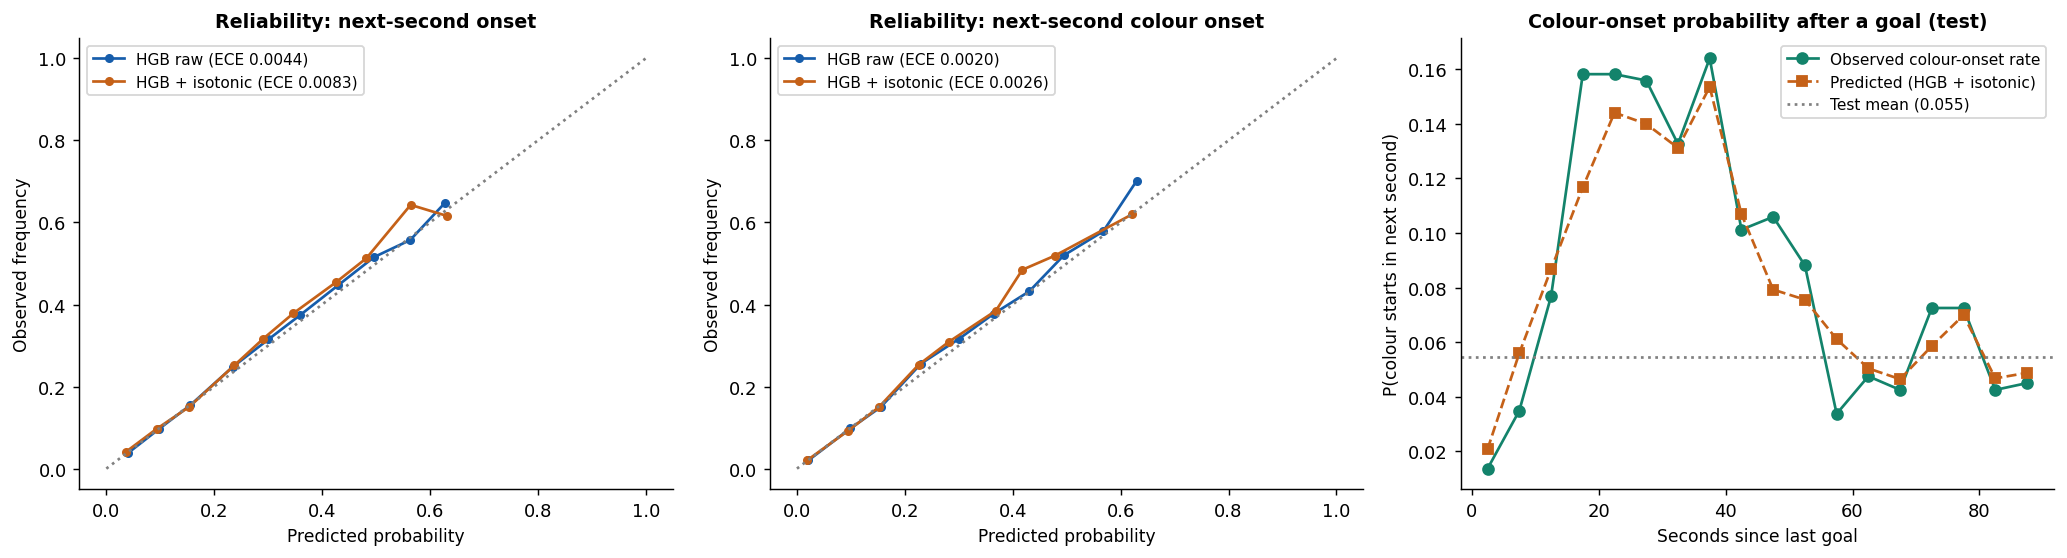

,since_goal_mid_s,observed,predicted
0,2.5,0.0137,0.0208
1,7.5,0.0349,0.0560
2,12.5,0.0767,0.0867
3,17.5,0.1581,0.1167
4,22.5,0.1581,0.1440
5,27.5,0.1558,0.1399
6,32.5,0.1326,0.1311
7,37.5,0.1639,0.1535
8,42.5,0.1012,0.1069
9,47.5,0.1059,0.0792


In [11]:
# Step 9. Calibration and what the probabilities look like around goals
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
bins = np.linspace(0, 1, 16)
for ax, (lab, y, p_raw, p_cal) in zip(axes[:2], [("next-second onset", y_on, 1 - preds["3 Full features (HGB)"][0][:, 0], cal_on),
                                                 ("next-second colour onset", y_col, preds["3 Full features (HGB)"][0][:, 2], cal_col)]):
    for p, lbl, col in [(p_raw, "HGB raw", "#165DAB"), (p_cal, "HGB + isotonic", "#C56118")]:
        idx = np.minimum((p * 15).astype(int), 14)
        xs = [p[idx == b].mean() for b in range(15) if (idx == b).sum() >= 50]
        ys = [y[idx == b].mean() for b in range(15) if (idx == b).sum() >= 50]
        ax.plot(xs, ys, "-o", ms=4, color=col, label=f"{lbl} (ECE {ece(y, p):.4f})")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set_title(f"Reliability: {lab}"); ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency"); ax.legend(loc="upper left")

# Average predicted vs observed colour-onset probability by time since the last goal (test split)
sg = gte["since_Goal"].to_numpy()
edges = np.arange(0, 91, 5)
centres, obs, pred = [], [], []
for a, b in zip(edges[:-1], edges[1:]):
    m = (sg >= a) & (sg < b)
    if m.sum() >= 30:
        centres.append((a + b) / 2); obs.append(y_col[m].mean()); pred.append(cal_col[m].mean())
axes[2].plot(centres, obs, "-o", color="#13836B", label="Observed colour-onset rate")
axes[2].plot(centres, pred, "--s", color="#C56118", label="Predicted (HGB + isotonic)")
axes[2].axhline(y_col.mean(), color="gray", ls=":", label=f"Test mean ({y_col.mean():.3f})")
axes[2].set_title("Colour-onset probability after a goal (test)"); axes[2].set_xlabel("Seconds since last goal"); axes[2].set_ylabel("P(colour starts in next second)")
axes[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/s1_fig_calibration_and_goal_curve.png", bbox_inches="tight"); plt.show()
goal_curve = pd.DataFrame({"since_goal_mid_s": centres, "observed": np.round(obs, 4), "predicted": np.round(pred, 4)})
display(goal_curve)


### Results [OBSERVED]
- The reliability curves (left two panels) lie close to the diagonal for both targets.
- After a goal (right panel and table), the observed colour-onset rate is about 0.014 in the first 5 s and climbs to about 0.158 by 15–30 s. The model follows the shape but **under-predicts the peak**: 0.117–0.144 predicted against 0.156–0.158 observed at 15–30 s.

### Design implication [INFERRED]
- The model learns Step 4's replay-slot pattern from `since_Goal` combined with turn state, not from a hand-coded rule.
- The under-predicted peak suggests adding a feature such as "replay likely in progress"; Exp 4 should test this.
- The slot builds over the first ~15 s, which is the lead time System 2 needs to write the replay breakdown.

---
## Step 10 — Robustness: feed delay, missing or duplicate events, speaker-ID errors

**Why it matters.** Live feeds are late (commercial feeds range from 0–4 s to 16+ s [CITED: Sportradar latency indicator docs]). Detectors drop and duplicate events (Step 2C). Diarization is unvalidated (Step 4).

**Method.** Keep the clean-trained full-feature trees model and perturb only the **inputs** of the test split; labels stay the clean truth. The perturbations:
- events arriving 2, 4 or 8 s late
- 10% or 30% of events dropped
- 20% of events duplicated 0.2–1.0 s later
- 10% of speaker IDs swapped

In [12]:
# Step 10. Robustness: feed delay, dropped events, duplicated events, speaker-ID noise (clean-trained full HGB)
m_full, F_full, _ = models["3 Full features (HGB)"]
te_en2 = en2[en2.split == "test"]
te_events = {g: events[g] for g in te_en2.game.unique()}
N_SEEDS = 5   # random perturbations are repeated with seeds 0..4; delays are deterministic

def score(g_eval):
    p = m_full.predict_proba(g_eval[F_full])
    return roc_auc_score(g_eval.y_onset, 1 - p[:, 0]), roc_auc_score((g_eval.y_who == 2).astype(int), p[:, 2])

def perturb_events(evd, rng, drop=0.0, dup=0.0):
    out = {}
    for g, ev in evd.items():
        keep = ev[rng.random(len(ev)) >= drop]
        extra = keep[rng.random(len(keep)) < dup].copy(); extra["t"] = extra.t + rng.uniform(0.2, 1.0, len(extra))
        out[g] = pd.concat([keep, extra]).sort_values("t").reset_index(drop=True)
    return out

def swap_speakers(df, frac, rng):
    d = df.copy(); flip = rng.random(len(d)) < frac
    d.loc[flip, "is_colour"] = 1 - d.loc[flip, "is_colour"]; return d

def eval_condition(u, evd, delay=0.0):
    g_eval = build_grid(u, evd, delay=delay)
    # labels always come from the clean transcript; only the inputs are perturbed
    g_eval["y_onset"], g_eval["y_who"] = gte.y_onset.to_numpy(), gte.y_who.to_numpy()
    return score(g_eval)

conds = [("clean", False, lambda r: (te_en2, te_events, 0.0))]
conds += [(f"feed delay {d} s", False, (lambda r, d=d: (te_en2, te_events, float(d)))) for d in [2, 4, 8]]
conds += [("drop 10% of events", True, lambda r: (te_en2, perturb_events(te_events, r, drop=0.10), 0.0)),
          ("drop 30% of events", True, lambda r: (te_en2, perturb_events(te_events, r, drop=0.30), 0.0)),
          ("duplicate 20% of events (+0.2-1.0 s)", True, lambda r: (te_en2, perturb_events(te_events, r, dup=0.20), 0.0)),
          ("swap 10% of speaker IDs", True, lambda r: (swap_speakers(te_en2, 0.10, r), te_events, 0.0))]
rob = []
for name, is_random, make in conds:
    vals = np.array([eval_condition(*make(np.random.default_rng(sd))) for sd in range(N_SEEDS if is_random else 1)])
    rob.append({"condition": name, "runs": len(vals),
                "onset_AUROC_mean": round(vals[:, 0].mean(), 4), "onset_AUROC_sd": round(vals[:, 0].std(ddof=1), 4) if len(vals) > 1 else 0.0,
                "colour_AUROC_mean": round(vals[:, 1].mean(), 4), "colour_AUROC_sd": round(vals[:, 1].std(ddof=1), 4) if len(vals) > 1 else 0.0})
rob = pd.DataFrame(rob)
rob["colour_drop_vs_clean"] = (rob.colour_AUROC_mean - rob.colour_AUROC_mean.iloc[0]).round(4)
rob.to_csv(f"{OUT_DIR}/s1_table_robustness.csv", index=False)
display(rob)


,condition,runs,onset_AUROC_mean,onset_AUROC_sd,colour_AUROC_mean,colour_AUROC_sd,colour_drop_vs_clean
0,clean,1,0.7325,0.0000,0.8280,0.0000,0.0000
1,feed delay 2 s,1,0.7314,0.0000,0.8257,0.0000,-0.0023
2,feed delay 4 s,1,0.7305,0.0000,0.8210,0.0000,-0.0070
3,feed delay 8 s,1,0.7293,0.0000,0.8114,0.0000,-0.0166
4,drop 10% of events,5,0.7321,0.0001,0.8265,0.0003,-0.0015
5,drop 30% of events,5,0.7316,0.0004,0.8230,0.0006,-0.0050
6,duplicate 20% of events (+0.2-1.0 s),5,0.7324,0.0001,0.8280,0.0001,0.0000
7,swap 10% of speaker IDs,5,0.7312,0.0003,0.7966,0.0008,-0.0314


### Results [OBSERVED]
Delays are deterministic (1 run each). Random perturbations are repeated with 5 seeds and shown as mean ± sd.

| Condition | Onset AUROC | Colour-onset AUROC | Change in colour AUROC vs clean |
|---|---|---|---|
| Clean | 0.7325 | 0.8280 | — |
| Feed delay 2 / 4 / 8 s | 0.7314 / 0.7305 / 0.7293 | 0.8257 / 0.8210 / 0.8114 | −0.0023 / −0.0070 / −0.0166 |
| Drop 10% of events | 0.7321 ± 0.0001 | 0.8265 ± 0.0003 | −0.0015 |
| Drop 30% of events | 0.7316 ± 0.0004 | 0.8230 ± 0.0006 | −0.0050 |
| Duplicate 20% of events | 0.7324 ± 0.0001 | 0.8280 ± 0.0001 | 0.0000 |
| Swap 10% of speaker IDs | 0.7312 ± 0.0003 | 0.7966 ± 0.0008 | **−0.0314** |

The seed-to-seed spread (sd ≤ 0.0008) is far smaller than the gaps between conditions.

### Design implication [INFERRED]
- **At these severities, speaker-ID errors hurt most**, because turn state is the main signal (Step 8). This ranking depends on the doses we chose: a 10% swap rate and an 8 s delay are not equivalent, and a larger delay or drop rate could overtake it. Exp 4 should sweep severity. Even so, the diarization listening audit (Exp 1) should come before any large training run.
- **Feed delay costs little at 2–4 s** and −0.017 at 8 s. Training on matched delays is a cheap CPU follow-up.
- **Bad events barely affect the model** but still affect what is *said* (the double goal in Step 2C), so the event normaliser stays.

---
## Step 11 — Does language state help System 1?

**Why it matters.** Jev-style models read text. If knowing *what was just said* improves System 1's decisions, a text decision model earns its cost; if not, it doesn't belong in the fast path.

**Method.** Use Step 4's onset-level tasks: speaker role `is_colour`, and the GPT-3.5 label `y_bg` as a crude content-type proxy. Inputs are Step 4's 25 causal features (without the onset-dependent pause). We add the TF-IDF of the **two previous utterances**, which have already been spoken, so the feature is causal.

Two comparisons, each with a paired game-level bootstrap CI on the difference:
1. **Logistic regression with vs without text.** Regularization C is chosen on the **validation** split from {0.1, 1, 10}.
2. **Stacked trees.** An out-of-fold text-only score (5 game-grouped folds on the training split) is added as one extra feature to the numeric trees.

In [13]:
# Step 11. Onset-level tasks from Step 4 (speaker role, handoff) + does TEXT state add information?
# Features mirror Step 4E without the onset-dependent `gap`; text = the two previous utterances (already spoken, so causal).
rows4 = []
for (g, h), u in en2.groupby(["game", "half"], sort=False):
    ev = events[g]; ev = ev[ev.half == h]; et, el = ev.t.to_numpy(), ev.label.to_numpy()
    prev_dur, prev_col, run_sec, prev_end = np.nan, np.nan, 0.0, np.nan
    texts = u.text.tolist()
    for i, r in enumerate(u.itertuples()):
        t = r.start; m = et <= t
        f = {"half": h, "clock": t / 60.0}
        for c in CLASSES:
            tt = et[m & (el == c)]
            f["since_" + c] = min(t - tt[-1], CAP) if len(tt) else CAP
        f["min_since_any"] = min(t - et[m][-1], CAP) if m.any() else CAP
        f["n_ev_60"] = int(((et > t - 60) & m).sum()); f["n_ev_15"] = int(((et > t - 15) & m).sum())
        f["prev_dur"] = prev_dur if prev_dur == prev_dur else -1.0
        f["prev_colour"] = prev_col if prev_col == prev_col else -1.0
        f["run_sec"] = run_sec
        f.update(game=g, split=r.split, is_colour=r.is_colour, y_bg=r.y_bg, prev_text=" ".join(texts[max(0, i - 2):i]))
        rows4.append(f)
        run_sec = run_sec + r.dur if (prev_col == r.is_colour and t - prev_end < 10.0) else r.dur
        prev_end, prev_dur, prev_col = r.end, r.dur, r.is_colour
on = pd.DataFrame(rows4)
F_ON = ["half", "clock", "min_since_any", "n_ev_60", "n_ev_15"] + ["since_" + c for c in CLASSES] + ["prev_dur", "prev_colour", "run_sec"]
otr, ova, ote = (on[on.split == s].reset_index(drop=True) for s in ["train", "valid", "test"])
on_games = ote.game.unique(); on_idx = {g: np.where(ote.game.to_numpy() == g)[0] for g in on_games}
brng = np.random.default_rng(42)
OBOOT = [np.concatenate([on_idx[g] for g in brng.choice(on_games, len(on_games))]) for _ in range(200)]

from sklearn.model_selection import GroupKFold
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000).fit(otr.prev_text)
sc_on = StandardScaler().fit(otr[F_ON])
Xn = {k: sparse.csr_matrix(sc_on.transform(d[F_ON])) for k, d in [("tr", otr), ("va", ova), ("te", ote)]}
Xt = {k: vec.transform(d.prev_text) for k, d in [("tr", otr), ("va", ova), ("te", ote)]}
Xnt = {k: sparse.hstack([Xn[k], Xt[k]]).tocsr() for k in Xn}
C_GRID = [0.1, 1.0, 10.0]

def fit_lr_choose_c(Xtr, ytr, Xva, yva):
    """Fit logistic regression for each C; keep the one with the best VALIDATION AUROC."""
    best = None
    for Cv in C_GRID:
        m = LogisticRegression(max_iter=1000, C=Cv).fit(Xtr, ytr)
        a_va = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if best is None or a_va > best[0]:
            best = (a_va, Cv, m)
    return best

def paired_delta(y, pa, pb):
    d = [roc_auc_score(y[s_], pa[s_]) - roc_auc_score(y[s_], pb[s_]) for s_ in OBOOT]
    return round(roc_auc_score(y, pa) - roc_auc_score(y, pb), 4), f"[{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]"

gkf = GroupKFold(n_splits=5)
text_rows, chosen_c = [], {}
for target in ["is_colour", "y_bg"]:
    ytr, yva, yte = otr[target].to_numpy(), ova[target].to_numpy(), ote[target].to_numpy()
    p_hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG_SEED).fit(otr[F_ON], ytr).predict_proba(ote[F_ON])[:, 1]
    _, c_num, m_num = fit_lr_choose_c(Xn["tr"], ytr, Xn["va"], yva)
    _, c_txt, m_txt = fit_lr_choose_c(Xnt["tr"], ytr, Xnt["va"], yva)
    p_num, p_txt = m_num.predict_proba(Xn["te"])[:, 1], m_txt.predict_proba(Xnt["te"])[:, 1]
    # Stacked test: an out-of-fold text-only score (5 game-grouped folds) becomes one extra feature for the trees
    _, c_to, m_to = fit_lr_choose_c(Xt["tr"], ytr, Xt["va"], yva)
    oof = np.zeros(len(otr))
    for f_tr, f_ho in gkf.split(Xt["tr"], ytr, groups=otr.game):
        oof[f_ho] = LogisticRegression(max_iter=1000, C=c_to).fit(Xt["tr"][f_tr], ytr[f_tr]).predict_proba(Xt["tr"][f_ho])[:, 1]
    stk = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RNG_SEED).fit(otr[F_ON].assign(txt_score=oof), ytr)
    p_stk = stk.predict_proba(ote[F_ON].assign(txt_score=m_to.predict_proba(Xt["te"])[:, 1]))[:, 1]
    chosen_c[target] = {"numeric LR": c_num, "numeric+text LR": c_txt, "text-only LR (stacked score)": c_to}
    p_persist = np.where(ote.prev_colour >= 0, ote.prev_colour, ytr.mean()) if target == "is_colour" else np.full(len(yte), ytr.mean())
    for name, p in [("Persistence / base rate", p_persist), ("Numeric only (HGB)", p_hgb), ("Numeric only (logistic)", p_num),
                    ("Numeric + previous-utterance text (logistic)", p_txt), ("Numeric + out-of-fold text score (HGB, stacked)", p_stk)]:
        vals = [roc_auc_score(yte[s_], p[s_]) for s_ in OBOOT]
        text_rows.append({"target": target, "model": name, "n_test": len(yte), "pos_rate": round(float(yte.mean()), 3),
                          "AUROC": round(roc_auc_score(yte, p), 4), "AUROC_CI": f"[{np.percentile(vals, 2.5):.3f}, {np.percentile(vals, 97.5):.3f}]",
                          "AP": round(average_precision_score(yte, p), 4)})
    for label, pa, pb in [("Δ text − numeric (logistic), paired bootstrap", p_txt, p_num), ("Δ stacked − numeric (HGB), paired bootstrap", p_stk, p_hgb)]:
        dlt, ci = paired_delta(yte, pa, pb)
        text_rows.append({"target": target, "model": label, "n_test": len(yte), "pos_rate": np.nan, "AUROC": dlt, "AUROC_CI": ci, "AP": np.nan})
text_tab = pd.DataFrame(text_rows)
text_tab.to_csv(f"{OUT_DIR}/s1_table_text_state_value.csv", index=False)
print(f"Onset-level test turns: {len(ote):,} ({len(on_games)} games); numeric features: {len(F_ON)}; text vocabulary: {len(vec.vocabulary_):,}")
print(f"Regularization C chosen on the validation split (grid {C_GRID}): {chosen_c}")
display(text_tab)


Onset-level test turns: 20,852 (25 games); numeric features: 25; text vocabulary: 20,000
Regularization C chosen on the validation split (grid [0.1, 1.0, 10.0]): {'is_colour': {'numeric LR': 10.0, 'numeric+text LR': 0.1, 'text-only LR (stacked score)': 0.1}, 'y_bg': {'numeric LR': 0.1, 'numeric+text LR': 0.1, 'text-only LR (stacked score)': 0.1}}


,target,model,n_test,pos_rate,AUROC,AUROC_CI,AP
0,is_colour,Persistence / base rate,20852,0.368,0.7763,"[0.756, 0.792]",0.6192
1,is_colour,Numeric only (HGB),20852,0.368,0.8665,"[0.852, 0.881]",0.8072
2,is_colour,Numeric only (logistic),20852,0.368,0.8201,"[0.802, 0.835]",0.7253
3,is_colour,Numeric + previous-utterance text (logistic),20852,0.368,0.8249,"[0.808, 0.839]",0.7334
4,is_colour,"Numeric + out-of-fold text score (HGB, stacked)",20852,0.368,0.8683,"[0.854, 0.883]",0.8089
5,is_colour,"Δ text − numeric (logistic), paired bootstrap",20852,NaN,0.0048,"[0.003, 0.007]",NaN
6,is_colour,"Δ stacked − numeric (HGB), paired bootstrap",20852,NaN,0.0018,"[0.000, 0.003]",NaN
7,y_bg,Persistence / base rate,20852,0.196,0.5000,"[0.500, 0.500]",0.1958
8,y_bg,Numeric only (HGB),20852,0.196,0.6347,"[0.621, 0.648]",0.2833
9,y_bg,Numeric only (logistic),20852,0.196,0.6081,"[0.594, 0.623]",0.2568


### Results [OBSERVED]
Test set: 20,852 turns from 25 games; text vocabulary 20,000 terms. C chosen on validation: speaker role, numeric 10 and numeric + text 0.1; background label, 0.1 for both; text-only score 0.1 for both targets.

| Target | Persistence / base | Numeric (trees) | Numeric + text score (stacked trees) | Numeric (logistic) | Numeric + text (logistic) |
|---|---|---|---|---|---|
| Speaker role `is_colour` | 0.7763 | 0.8665 | **0.8683** | 0.8201 | 0.8249 |
| GPT-3.5 label `y_bg` | 0.5000 | 0.6347 | **0.6548** | 0.6081 | 0.6354 |

| Target | Δ stacked − numeric (trees) [95% CI] | Δ text − numeric (logistic) [95% CI] |
|---|---|---|
| Speaker role | +0.0018 [0.000, 0.003] | +0.0048 [0.003, 0.007] |
| GPT-3.5 label | +0.0202 [0.015, 0.026] | +0.0273 [0.021, 0.034] |

- **For speaker role, text adds very little.** The stacked trees gain +0.002 AUROC, with a CI whose lower bound is 0.
- **For the content-type proxy, text adds a clear gain** (+0.020 for the stacked trees).
- An earlier version of this step used a fixed C = 1 without validation and found text slightly *hurting*. With C chosen on validation, that result reverses, so the earlier "text adds nothing" claim was too strong.
- The numeric trees reproduce Step 4E's 0.8665 for `is_colour`.

### Design implication [INFERRED]
- **Turn-taking:** text gives only a marginal gain, not worth a language model in the every-second path.
- **Content decisions:** recent talk does carry information, so a text decision model (S1-typed) is justified for content-level choices: content class, fact choice, draft verification. Whether a real encoder beats TF-IDF there is tested in H1 and H2.

---
## Step 12 — What does each kind of decision model cost?

**Method.**
1. **Every-second candidates:** time single-row and batched predictions of the trained models.
2. **Text decision models:** time **randomly initialized** encoders with the published backbone sizes of Von and Laya (~395M, ModernBERT-large class) and a ~150M base-size encoder, at 64–512 tokens. Random weights do the same arithmetic as trained ones, so this measures compute cost without downloading a model.
3. Estimate how long a serialized System 1 state is in tokens: a rough word-and-punctuation count × 1.3, plus an assumed 60-token question block (no tokenizer was downloaded).
4. **Estimate realistic S1-typed inputs.** S1-typed reads text, not just the numeric state:
   - Content class: state + the last 4 utterances.
   - Fact choice: also 8 candidate facts, each modeled as one sentence from Mori's Wikipedia corpus.
   - Draft verification: state + a draft, modeled as one colour-analyst utterance.

   The number of facts, the 4-utterance window and the 60-token question block are assumptions. We read the cost from the proxy row at or above each median length.
5. Combine latency with call rates measured in the data: content class per utterance onset, fact choice per colour turn, verification per colour utterance.

**These timings come from the analysis machine printed in Setup, not the M5 target.** Read them as relative costs; Exp 5 measures the M5.

In [14]:
# Step 12A. Cost of a decision on THIS machine (relative only; the target device is an M5 MacBook Air)
def time_calls(fn, X, n=300):
    for _ in range(20): fn(X)
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(X); ts.append(time.perf_counter() - t0)
    return np.median(ts) * 1e3, np.percentile(ts, 95) * 1e3

lat = []
x1 = gte[F_ALL].iloc[[1000]]; xb = gte[F_ALL].iloc[:1000]
for name in ["3 Full features (HGB)", "4 Full features (logistic)", "5 Full features (MLP 64x64)"]:
    m, F, kind = models[name]
    fn = (lambda X, m=m: m.predict_proba(X)) if kind == "hgb" else (lambda X, m=m: m[1].predict_proba(m[0].transform(X)))
    p50, p95 = time_calls(fn, x1)
    b50, _ = time_calls(fn, xb, n=30)
    lat.append({"model": name, "single_call_p50_ms": round(p50, 3), "single_call_p95_ms": round(p95, 3), "per_row_in_batch_of_1000_ms": round(b50 / 1000, 4)})
lat = pd.DataFrame(lat)
lat.to_csv(f"{OUT_DIR}/s1_table_fast_latency_this_machine.csv", index=False)
print(f"Measured on: {cpu} (NOT the target M5). Single-row calls include scikit-learn Python overhead.")
display(lat)


Measured on: Apple M1 (NOT the target M5). Single-row calls include scikit-learn Python overhead.


,model,single_call_p50_ms,single_call_p95_ms,per_row_in_batch_of_1000_ms
0,3 Full features (HGB),31.571,82.360,0.0675
1,4 Full features (logistic),1.241,2.068,0.0009
2,5 Full features (MLP 64x64),0.842,1.575,0.0022


In [15]:
# Step 12B. Could a Jev-style TEXT decision model fit in the loop? Compute-cost proxy, no pretrained weights downloaded.
# We time randomly initialised encoders with the published sizes of the open decision models' backbones:
#   ~395M (ModernBERT-large class: Von, Laya) and a ~150M base-size encoder. Random weights give the same FLOPs.
import torch, torch.nn as nn
torch.manual_seed(0); torch.set_num_threads(4)
class ProxyEncoder(nn.Module):
    def __init__(self, vocab, d, layers, heads, ff):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, ff, batch_first=True, activation="gelu"), layers)
        self.head = nn.Linear(d, 8)
    def forward(self, ids):
        return self.head(self.enc(self.emb(ids))[:, 0])
proxies = {"~395M encoder (ModernBERT-large class)": dict(vocab=50368, d=1024, layers=28, heads=16, ff=4096),
           "~150M encoder (ModernBERT-base class)": dict(vocab=50368, d=768, layers=16, heads=12, ff=3072)}
plat = []
for pname, cfg in proxies.items():
    net = ProxyEncoder(**cfg).eval()
    n_params = sum(p.numel() for p in net.parameters())
    for L in [64, 128, 256, 512]:
        ids = torch.randint(0, cfg["vocab"], (1, L))
        with torch.inference_mode():
            for _ in range(3): net(ids)
            ts = []
            for _ in range(25 if L <= 256 else 12):   # repeated runs; the median resists background load
                t0 = time.perf_counter(); net(ids); ts.append(time.perf_counter() - t0)
        plat.append({"proxy": pname, "params_M": round(n_params / 1e6, 1), "seq_len": L, "p50_ms_fp32_4threads": round(np.median(ts) * 1e3, 1)})
    del net
plat = pd.DataFrame(plat)

# How long is a serialized System-1 state? Rough token estimate (word/punctuation pieces x 1.3; no tokenizer downloaded)
def state_text(r):
    recent = ", ".join(f"{c} {r['since_' + c]:.0f}s ago" for c in CLASSES if r["since_" + c] < 60)
    return (f"half {int(r.half)}, minute {r.clock:.1f}. Speaking now: {'yes' if r.speaking else 'no'}. "
            f"Last speaker: {'colour analyst' if r.last_col == 1 else 'lead commentator'}. Silence {r.silence:.0f}s. "
            f"Events in last 60s: {int(r.n_ev_60)}. Recent: {recent or 'none'}.")
samp = gte.sample(2000, random_state=RNG_SEED)
pieces = samp.apply(lambda r: len(re.findall(r"\w+|[^\w\s]", state_text(r))), axis=1)
q_tokens = 60  # assumed size of the typed question block (two choice questions); an assumption, not measured
est_tokens = (pieces * 1.3 + q_tokens)
print(f"Serialized state length (approx. tokens incl. {q_tokens}-token question block): median {est_tokens.median():.0f}, p95 {est_tokens.quantile(0.95):.0f}")

calls_per_min = EV_PER_MIN + UTT_PER_MIN   # used only for the legacy columns below (S1-fast-sized state)
plat["calls_per_min_event_and_onset_triggered"] = round(calls_per_min, 2)
plat["cpu_busy_pct_event_triggered"] = (plat.p50_ms_fp32_4threads * calls_per_min / 60000 * 100).round(2)
plat["cpu_busy_pct_if_called_every_second"] = (plat.p50_ms_fp32_4threads * 60 / 60000 * 100).round(1)
plat.to_csv(f"{OUT_DIR}/s1_table_text_model_cost_proxy.csv", index=False)
print(f"Measured on: {cpu} (NOT the target M5), fp32, 4 threads, batch 1, random weights.")
display(plat)

# Realistic S1-typed inputs carry TEXT, not just the numeric state: recent transcript, candidate facts, or a draft sentence.
def approx_tokens(txt):
    return len(re.findall(r"\w+|[^\w\s]", txt)) * 1.3

state_tok = (pieces * 1.3).median()                                  # serialized numeric state, without the question block
te_turns = en2[en2.split == "test"].reset_index(drop=True)
idx_s = np.random.default_rng(RNG_SEED).choice(np.arange(4, len(te_turns)), 2000, replace=False)
transcript_tok = np.array([approx_tokens(" ".join(te_turns.text.iloc[i - 4:i])) for i in idx_s])   # last 4 utterances
fact_sents = [x for c in chunks[:5000] for x in re.split(r"(?<=[.!?])\s+", c) if len(x.split()) >= 5]
fact_tok = np.array([approx_tokens(x) for x in fact_sents])          # one fact ~ one sentence of Mori's Wikipedia corpus
draft_tok = np.array([approx_tokens(x) for x in en2[en2.is_colour == 1].text])   # a draft ~ one colour-analyst utterance
K_FACTS, Q_TOK = 8, 60                                               # ASSUMPTIONS: 8 candidate facts per choice; 60-token question block
inputs = pd.DataFrame([
    {"decision": "content class (C1-C7)", "parts": "state + last 4 utterances + question",
     "median_tokens": state_tok + np.median(transcript_tok) + Q_TOK, "p95_tokens": state_tok + np.percentile(transcript_tok, 95) + Q_TOK},
    {"decision": "which notebook fact (8 candidates)", "parts": "state + last 4 utterances + 8 facts + question",
     "median_tokens": state_tok + np.median(transcript_tok) + K_FACTS * np.median(fact_tok) + Q_TOK,
     "p95_tokens": state_tok + np.percentile(transcript_tok, 95) + K_FACTS * np.percentile(fact_tok, 95) + Q_TOK},
    {"decision": "verify a System 2 draft", "parts": "state + draft sentence + question",
     "median_tokens": state_tok + np.median(draft_tok) + Q_TOK, "p95_tokens": state_tok + np.percentile(draft_tok, 95) + Q_TOK},
])
# Call rates from Step 6 data: content class per utterance onset; fact choice per colour TURN; verification per colour utterance
colour_turns_per_min = float(((en2.prev_colour.notna()) & (en2.prev_colour != en2.is_colour) & (en2.is_colour == 1)).sum() / en2_min)
colour_utts_per_min = float(en2.is_colour.sum() / en2_min)
inputs["calls_per_min"] = [UTT_PER_MIN, colour_turns_per_min, colour_utts_per_min]
inputs["proxy_row_tokens"] = [next(L for L in [64, 128, 256, 512] if L >= mt) if mt <= 512 else 512 for mt in inputs.median_tokens]
lat_lookup = plat.set_index(["proxy", "seq_len"]).p50_ms_fp32_4threads
for pname, short in [("~395M encoder (ModernBERT-large class)", "395M"), ("~150M encoder (ModernBERT-base class)", "150M")]:
    inputs[f"p50_ms_{short}"] = [float(lat_lookup[(pname, L)]) for L in inputs.proxy_row_tokens]
    inputs[f"cpu_busy_pct_{short}"] = (inputs[f"p50_ms_{short}"] * inputs.calls_per_min / 60000 * 100).round(2)
inputs[["median_tokens", "p95_tokens", "calls_per_min"]] = inputs[["median_tokens", "p95_tokens", "calls_per_min"]].round(1)
inputs.to_csv(f"{OUT_DIR}/s1_table_typed_input_budget.csv", index=False)
print(f"\nRealistic S1-typed inputs (approx. tokens; assumptions: {K_FACTS} candidate facts, {Q_TOK}-token question block, last 4 utterances):")
display(inputs)
print(f"Total S1-typed CPU busy share at these rates: 395M proxy {inputs.cpu_busy_pct_395M.sum():.2f}% | 150M proxy {inputs.cpu_busy_pct_150M.sum():.2f}%")


Serialized state length (approx. tokens incl. 60-token question block): median 117, p95 132
Measured on: Apple M1 (NOT the target M5), fp32, 4 threads, batch 1, random weights.


,proxy,params_M,seq_len,p50_ms_fp32_4threads,calls_per_min_event_and_onset_triggered,cpu_busy_pct_event_triggered,cpu_busy_pct_if_called_every_second
0,~395M encoder (ModernBERT-large class),404.3,64,249.1,11.46,4.76,24.9
1,~395M encoder (ModernBERT-large class),404.3,128,376.0,11.46,7.18,37.6
2,~395M encoder (ModernBERT-large class),404.3,256,702.6,11.46,13.42,70.3
3,~395M encoder (ModernBERT-large class),404.3,512,1177.9,11.46,22.50,117.8
4,~150M encoder (ModernBERT-base class),152.1,64,60.4,11.46,1.15,6.0
5,~150M encoder (ModernBERT-base class),152.1,128,110.5,11.46,2.11,11.0
6,~150M encoder (ModernBERT-base class),152.1,256,156.2,11.46,2.98,15.6
7,~150M encoder (ModernBERT-base class),152.1,512,316.8,11.46,6.05,31.7



Realistic S1-typed inputs (approx. tokens; assumptions: 8 candidate facts, 60-token question block, last 4 utterances):


,decision,parts,median_tokens,p95_tokens,calls_per_min,proxy_row_tokens,p50_ms_395M,cpu_busy_pct_395M,p50_ms_150M,cpu_busy_pct_150M
0,content class (C1-C7),state + last 4 utterances + question,186.1,271.9,9.1,256,702.6,10.68,156.2,2.37
1,which notebook fact (8 candidates),state + last 4 utterances + 8 facts + question,342.1,2487.1,0.9,512,1177.9,1.81,316.8,0.49
2,verify a System 2 draft,state + draft sentence + question,134.1,182.2,3.3,256,702.6,3.86,156.2,0.86


Total S1-typed CPU busy share at these rates: 395M proxy 16.35% | 150M proxy 3.72%


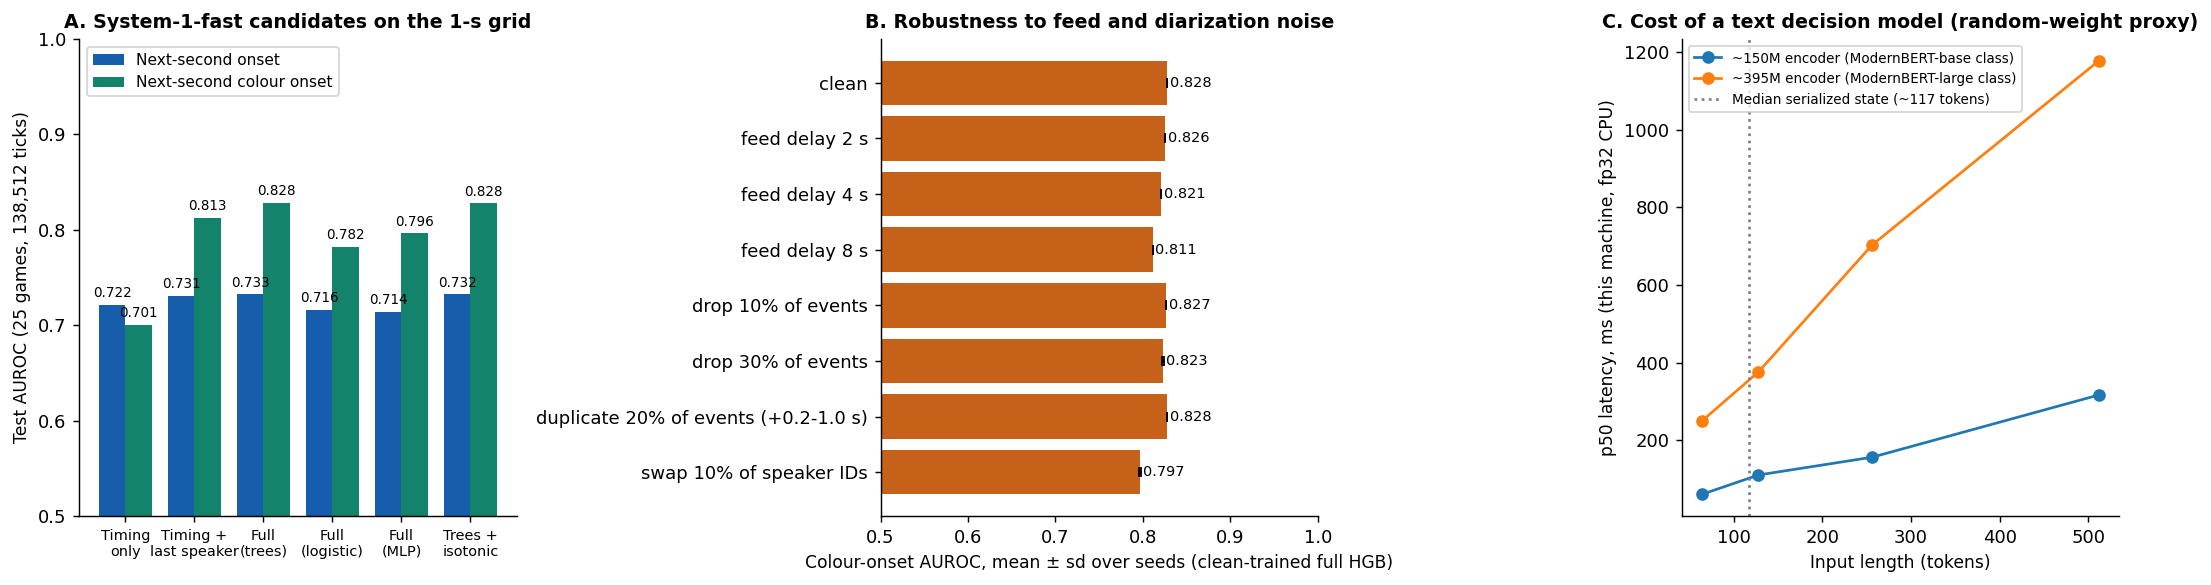

In [16]:
# Step 12C. Figure: model comparison, robustness and text-model cost
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
b = s1_bench[s1_bench.model.str[0] != "0"]
x = np.arange(len(b)); w = 0.38
axes[0].bar(x - w / 2, b.onset_AUROC, w, label="Next-second onset", color="#165DAB")
axes[0].bar(x + w / 2, b.colour_AUROC, w, label="Next-second colour onset", color="#13836B")
for i, (a1, a2) in enumerate(zip(b.onset_AUROC, b.colour_AUROC)):
    axes[0].text(i - w / 2, a1 + 0.008, f"{a1:.3f}", ha="center", fontsize=7.5); axes[0].text(i + w / 2, a2 + 0.008, f"{a2:.3f}", ha="center", fontsize=7.5)
SHORT = {"1": "Timing\nonly", "2": "Timing +\nlast speaker", "3": "Full\n(trees)", "4": "Full\n(logistic)", "5": "Full\n(MLP)", "6": "Trees +\nisotonic"}
axes[0].set_xticks(x); axes[0].set_xticklabels([SHORT[m[0]] for m in b.model], fontsize=8)
axes[0].set_ylim(0.5, 1.0); axes[0].set_ylabel(f"Test AUROC ({len(test_games)} games, {len(gte):,} ticks)")
axes[0].set_title("A. System-1-fast candidates on the 1-s grid"); axes[0].legend(loc="upper left")

axes[1].barh(rob.condition[::-1], rob.colour_AUROC_mean[::-1], xerr=rob.colour_AUROC_sd[::-1], color="#C56118", capsize=3)
for i, v in enumerate(rob.colour_AUROC_mean[::-1]):
    axes[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
axes[1].set_xlim(0.5, 1.0); axes[1].set_xlabel("Colour-onset AUROC, mean ± sd over seeds (clean-trained full HGB)")
axes[1].set_title("B. Robustness to feed and diarization noise")

for pname, d in plat.groupby("proxy"):
    axes[2].plot(d.seq_len, d.p50_ms_fp32_4threads, "-o", label=pname)
axes[2].axvline(est_tokens.median(), color="gray", ls=":", label=f"Median serialized state (~{est_tokens.median():.0f} tokens)")
axes[2].set_xlabel("Input length (tokens)"); axes[2].set_ylabel("p50 latency, ms (this machine, fp32 CPU)")
axes[2].set_title("C. Cost of a text decision model (random-weight proxy)"); axes[2].legend(fontsize=7.5)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/s1_fig_candidates_robustness_cost.png", bbox_inches="tight"); plt.show()


### Results [OBSERVED, analysis machine CPU]

**Every-second candidates.**
- Trees: 31.571 ms p50 for a single uncompiled scikit-learn call (82.360 ms p95), mostly Python overhead. In a batch they cost 0.0675 ms per row.
- Logistic regression and the MLP: 1.241 ms and 0.842 ms per single call.
- At one decision per second, all three are negligible. Timings on this machine vary by tens of percent between runs (load and heat).

**Text decision models (random-weight proxies, fp32, 4 threads, batch 1).**

| Proxy | Parameters | 64 tokens | 128 tokens | 256 tokens | 512 tokens |
|---|---|---|---|---|---|
| ModernBERT-large class (Von, Laya) | 404.3M | 249.1 ms | 376.0 ms | 702.6 ms | 1,177.9 ms |
| ModernBERT-base class | 152.1M | 60.4 ms | 110.5 ms | 156.2 ms | 316.8 ms |

The numeric state alone serializes to about 117 tokens (p95 132). The proxy table's busy-share columns assume that length and Step 6's combined call rate, so they understate S1-typed's real inputs. The realistic budget is below.

**Realistic S1-typed inputs** (approximate tokens):

| Decision | Input | Median tokens (p95) | Proxy row | Calls per minute | 395M: ms / CPU busy | 150M: ms / CPU busy |
|---|---|---|---|---|---|---|
| Content class (C1–C7) | state + last 4 utterances + question | 186.1 (271.9) | 256 | 9.1 | 702.6 / 10.68% | 156.2 / 2.37% |
| Which notebook fact (8 candidates) | + 8 facts | 342.1 (2,487.1) | 512 | 0.9 | 1,177.9 / 1.81% | 316.8 / 0.49% |
| Verify a System 2 draft | state + draft + question | 134.1 (182.2) | 256 | 3.3 | 702.6 / 3.86% | 156.2 / 0.86% |
| **Total** | | | | | **16.35%** | **3.72%** |

### Design implication [INFERRED]
1. **Two tiers still hold.** S1-fast (trees) runs every second. S1-typed runs only on events, utterances and drafts.
2. **The ~0.4B model is expensive at realistic lengths.** At fp32 on this CPU it costs 0.70–1.18 s per call and about 16% of CPU time, on a CPU that also runs TTS. A ~150M encoder costs 0.16–0.32 s and about 3.7%. Von reports 0.096 s on a 4-vCPU Xeon with OpenVINO [CITED], so an optimized runtime may close much of the gap. Exp 5 must measure int8 on CPU, the Neural Engine and a ~150M fallback on the M5 before D5 is final.
3. **Fact choice has a long tail** (p95 ~2,500 tokens with 8 long Wikipedia sentences). The notebook should store short, pre-verbalized facts and offer fewer candidates.
4. **These latencies fit the colour lead time** (Step 9) but not the live-call path, so S1-typed never sits on the 600 ms path.

---
# Part C — Proposed architecture

```text
Replayed provider feed (events + tracking + visibility flags), played with a fixed delay D
 │
 ├─ 1. Event normaliser (rules, CPU)
 │      same-class dedupe · merge 0 s co-annotations · Shot→Goal escalation (call the shot, upgrade to the goal)
 │
 ├─ 2. State builder (CPU)
 │      turn state · event features · in-match stats (C6) · tactical primitives P1–P6 · visibility per claim
 │
 ├─ 3. System 1 — fast decisions
 │      S1-fast   every 1 s · CPU · calibrated gradient-boosted trees on ~26 numeric features
 │                → who starts in the next second (nobody / PBP / colour) · speaker switch · preempt
 │      S1-typed  on events, utterances and drafts (~13/min) · CPU · open decision encoder, fine-tuned
 │                (~0.4B Von or Laya; ~150M fallback if the M5 budget requires, Exp 5)
 │                → content class C1–C7 · which notebook fact · hedge? · does the draft match the state?
 │
 ├─ 4. Content paths
 │      C1/C3 live calls     templates + names from the feed (no LLM)
 │      C2/C4/C5 colour      System 2 LLM (Qwen3.5-4B 4-bit, MLX on GPU) drafts at event release, queued for its slot
 │      C6/C7 notebook       pre-kickoff sentences (Wikipedia as of kick-off + Wikidata IDs)
 │
 └─ 5. Audio scheduler + TTS (CPU)
        one voice at a time · clause-sized chunks · PBP preempts colour
        Pocket TTS with two cloned voices, plus an excited PBP voice for goal calls
```

### Decision record

| # | Decision | Alternatives considered | Evidence | Status |
|---|---|---|---|---|
| D1 | Input is a **replayed provider feed with a fixed playback delay D**, so commentary stays in sync | Broadcast detection on the laptop; unbuffered live feed | `Labels-v2` are after-the-fact (Step 1); commercial feeds run 0–16+ s late [CITED: Sportradar]; S1-fast tolerates 2–4 s delays (Step 10); public broadcast tracking covers only 200 × 30 s clips [CITED: SoccerNet-GSR] | Inferred |
| D2 | **Event-specific normaliser**, not a fixed 2 s hold for every event | Fixed 2 s hold | 98.46% of Shot → Goal pairs are ≤ 2 s apart; 38.73% of penalties share the shot's timestamp; cards come a median 7.14 s after fouls (Step 5A); T-DEED double goal (Step 2C) | Supported on `Labels-v2` |
| D3 | **Two voices, and route by voice first** | Single voice routed by content label | Colour share 0.060 within ±5 s of a goal vs 0.911 at +15–30 s; voice is predictable (0.8665 vs 0.7763) while the GPT-3.5 label is not (Steps 3–4) | Supported |
| D4 | **S1-fast is gradient-boosted trees on numeric state**, every second | Text decision model; logistic regression; MLP; rules | Best candidate on any-onset (0.733 / 0.828) and turn-onset (0.850 / 0.866) targets, with the lowest log-loss (Step 8); text adds only +0.002 for speaker role (Step 11); 31.6 ms p50 per uncompiled single call on the M1 (Step 12) | Supported (25 test games) |
| D5 | **S1-typed is a separate, event-triggered open decision encoder**, fine-tuned (Von first, Laya second; ~150M fallback) | One large decision model for everything; Kev (MLX); no text model | Text adds +0.020 for the content-type proxy (Step 11); at realistic lengths a 0.4B model costs 0.70–1.18 s per call and ~16% CPU on the M1 at fp32, a 150M model ~3.7% (Step 12); licenses and sizes (Step 7) | Structure supported; size and accuracy **untested** (H1, H2, H6, Exp 5) |
| D6 | Large models (Clef, Qwen3.6-35B-A3B) are used **only offline, as teachers** | Run them on the laptop | 9B–27B backbones don't fit beside System 2 within the 12 GB gate (Part D) | Inferred (H3) |
| D7 | **Live calls (C1/C3) use templates**, not the LLM | LLM for every utterance | Not a latency necessity: a cached-LLM live call (~341 ms) would also fit the 600 ms gate (Part D). Templates are chosen because names and teams come straight from the feed (no generated entity errors, cf. Step 2C), latency stays steady when fanless throttling adds 30–41% to LLM time (Part D), and the GPU stays free for colour drafts. Live-call utterances are short (median 6 words within ±5 s of a goal, Step 4B) | Inferred |
| D8 | **System 2 drafts colour content at event release** | Generate at slot start | The colour share is 0.060 for 5 s after a goal and 0.531 at +5–15 s (Step 4B); the colour-onset rate builds over ~15 s (Step 9) | Supported; latency in Exp 5 |
| D9 | **Pre-kickoff notebook** built from Wikipedia revisions as of kick-off, with Wikidata IDs | Live Wikipedia retrieval | 75.6% of retrieved chunks mention a post-match year; at least 33 wrong-person pages (Step 2B); the MediaWiki API returns the latest revision before a timestamp (`rvstart` + `rvdir=older`) [CITED] | Supported |
| D10 | **Word budget** bounded by the expected time to the next event and a length cap near the human 90th percentile (~25 words), using the TTS voice's own rate | Pause-based budget; unbounded generation | Pauses would allow only 3 words, yet utterances are a median 8; events arrive a median 17.4 s apart; 90th-percentile utterance 8.97 s / 25 words; humans speak at 2.96 words/s (Step 1E) | Supported |
| D11 | **Visibility hedging per claim**, not per frame | Per-frame visibility fraction | The median player's space changes +2.4%, but the per-frame tail is heavy (Step 5B) | Partly supported (one match) |
| D12 | **Audit diarization before** any large training run | Train on diarization as-is | Speaker-ID noise is the largest robustness loss at the tested severities (−0.0314, Step 10) | Supported |
| D13 | **S1 and TTS on the CPU, the LLM on the GPU**, budgeted on *sustained* (not cold) latency | Everything on the GPU | Kokoro on MLX would compete with the LLM; fanless sustained throughput is 69–77% of cold [CITED] (Part D) | Planned (Exp 5) |

---
# Part D — Feasibility on the M5 (planning estimates, not measurements)

> **Nothing in Part D was measured on an M5 MacBook Air.** Exp 5 measures memory, time to first audio (TTFA), real-time factor and 45-minute thermal behavior.

**Hardware.**
- Apple M5 MacBook Air: 24 GB unified memory, 153 GB/s memory bandwidth, 10-core CPU and GPU [CITED: apple.com/macbook-air/specs].
- By default macOS lets the GPU use about 75% of RAM, according to community reports. We estimate about 19.07 GB (17.76 GiB) on this machine [UNVERIFIED: read `recommendedMaxWorkingSetSize` on the machine]. All memory figures below are in GB.

**Published measurements that bear on these estimates.**
- On an M5 MacBook Pro, MLX's time to first token is 3.3–4.1× faster than on an M4. Measured memory is 17.31 GB for Qwen3-30B-A3B 4-bit and 5.61 GB for Qwen3-8B 4-bit [CITED: Apple ML Research, "Exploring LLMs with MLX and the Neural Accelerators in the M5 GPU"].
- On a fanless M5 MacBook Air, sustained throughput settles at 69–77% of the cold rate after about 150 s, and time to first token grows 30–41% [CITED: third-party benchmark, zachrattner.com]. **Cold estimates understate sustained latency by roughly a third.**
- Pocket TTS (Kyutai, ~100M parameters, CPU) reports about 200 ms to the first audio chunk [CITED: vendor README]; independent 250–430 ms figures are [UNVERIFIED].

**Planned stack [PLANNED].**

| Component | Choice | Estimated memory |
|---|---|---|
| System 2 LLM | `Qwen3.5-4B-MLX-4bit` (thinking off by default [CITED: Unsloth docs]); quality tier `Qwen3.5-9B` | ~3.9 GB (9B: ~5.6 GB) |
| TTS | Pocket TTS on CPU (Kokoro-82M on MLX only as a fallback, since it would share the GPU with System 2) | ~0.3–0.4 GB |
| Router, tactical engine, runtime | CPU | ~0.8–0.9 GB |
| S1-fast | Gradient-boosted trees | negligible |
| S1-typed | ~0.4B encoder (Von: 1.5 GB fp32 [CITED]) | ~1.5 GB at fp32 |
| Rejected | Qwen3-30B-A3B 4-bit | 17.31 GB measured by Apple, too close to the GPU limit |

The plot includes S1-typed at fp32. The primary stack comes to about 6.5 GB and the quality tier to 8.4 GB, both under the 12 GB gate; the rejected 30B model alone reaches 18.9 GB against a ~19.07 GB GPU limit [PLANNED arithmetic].

**Latency estimate, measured from event release.**
- **Live call (D7: template, no LLM):** router ~1 ms + TTS first chunk 200 ms (vendor) or 350 ms (conservative) = **201–351 ms**.
- **Colour turn:** router + buildup geometry ~35 ms + LLM first clause 210 ms (cached prompt) or 320 ms (uncached) + TTS = **446 ms cached / 706 ms uncached**, against a 1,500 ms gate with seconds of lead time (D8).
- For reference, a live call routed through a cached LLM would take ~341 ms, also inside the 600 ms gate. D7's choice of templates therefore rests on correctness and steadiness, not on the gate.
- These are cold estimates; sustained values could be about a third higher.

**Cloud cost [CITED: modal.com/pricing].** An L4 costs $0.000222/s ($0.80/h) and an H100 $0.001097/s ($3.95/h).

Estimated post-release TTFA [PLANNED]: live call (template + TTS) 201–351 ms; colour turn 446 ms cached / 706 ms uncached
Reference: a live call through a cached LLM would take ~341 ms, also inside the 600 ms gate
Memory [PLANNED]: primary stack 6.5 GB, quality tier 8.4 GB, rejected 30B 18.9 GB; GPU limit ~19.07 GB


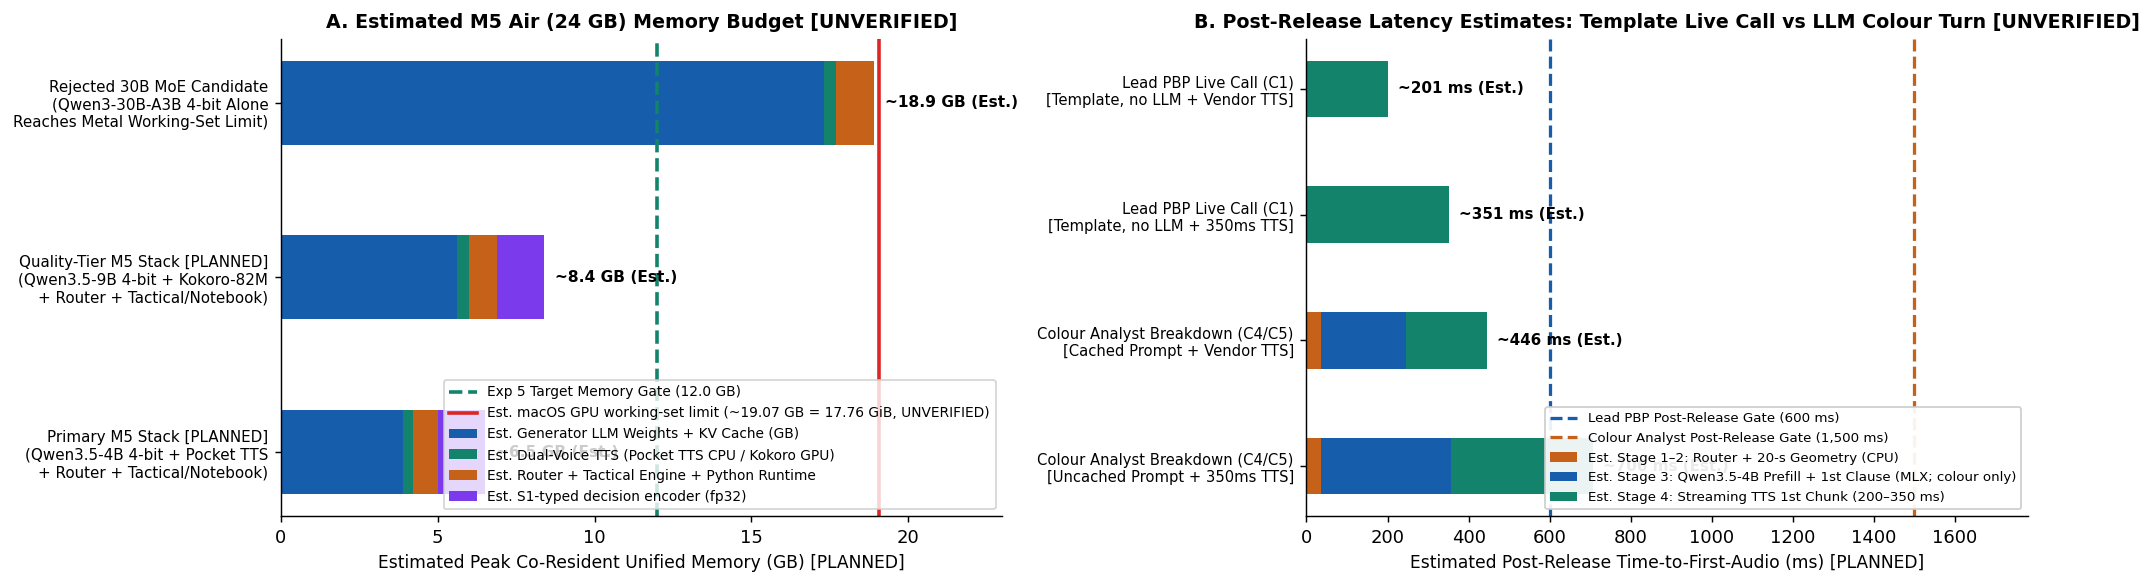

=== D2. Exp 1–5 compute ledger from the original plan (estimated cloud spend $5.50) [PLANNED] ===


,Stage,Hardware,Status / Est. Time,Est. Cost ($),Scope
0,This notebook (Parts A–B),Local CPU,Completed [OBSERVED],0.0,"LFCBI + 500-game event/diarization audit, Mori..."
1,Exp 1 (Gold + Calibration),Local + Modal L4 ($0.80/h),~1.0 h [PLANNED],0.8,600-turn human gold (target κ>=0.60) + Qwen3.5...
2,Exp 1 (Bulk Silver Labels),Modal H100 ($3.95/h),<= 53 min [PLANNED],3.5,"2k pilot + 99,800 English 2-speaker turns with..."
3,Exp 2 & Exp 3 (Tactics & Buildup),Local M5 Air CPU,~30 min [PLANNED],0.0,"P1..P6 spatial primitives, visibility gate, Sk..."
4,Exp 4 (Routers & Notebook),Local + Modal L4 ($0.80/h),~30 min [PLANNED],0.4,"2.0s coalescer, router ladder, pre-kickoff not..."
5,Exp 5 (M5 Air Benchmark),Local M5 Air + Modal L4,~1.0 h L4 [PLANNED],0.8,"Measure real M5 RSS/Metal memory, cached vs un..."


In [17]:
# Part D. Plot back-of-the-envelope memory, Latency (Cached vs. Uncached Ranges) & Modal Cost Budgets [PLANNED]
fig, axes = plt.subplots(1, 2, figsize=(15.8, 4.6))

# Panel A: Back-of-the-Envelope Co-Resident Memory Estimates on 24 GB M5 Air [PLANNED]
stacks = [
    "Primary M5 Stack [PLANNED]\n(Qwen3.5-4B 4-bit + Pocket TTS\n+ Router + Tactical/Notebook)",
    "Quality-Tier M5 Stack [PLANNED]\n(Qwen3.5-9B 4-bit + Kokoro-82M\n+ Router + Tactical/Notebook)",
    "Rejected 30B MoE Candidate\n(Qwen3-30B-A3B 4-bit Alone\nReaches Metal Working-Set Limit)"
]
llm_mem = np.array([3.9, 5.6, 17.31])
tts_mem = np.array([0.3, 0.4, 0.4])
sys_mem = np.array([0.8, 0.9, 1.2])
s1t_mem = np.array([1.5, 1.5, 0.0])                  # S1-typed ~0.4B encoder at fp32 (Von card: 1.5 GB)
totals_mem = llm_mem + tts_mem + sys_mem + s1t_mem
GPU_LIMIT_GB = 17.76 * 1.073741824                   # 17.76 GiB expressed in GB (UNVERIFIED community estimate)

y_pos = np.arange(len(stacks))
axes[0].barh(y_pos, llm_mem, color="#165DAB", height=0.48, label="Est. Generator LLM Weights + KV Cache (GB)")
axes[0].barh(y_pos, tts_mem, left=llm_mem, color="#13836B", height=0.48, label="Est. Dual-Voice TTS (Pocket TTS CPU / Kokoro GPU)")
axes[0].barh(y_pos, sys_mem, left=llm_mem + tts_mem, color="#C56118", height=0.48, label="Est. Router + Tactical Engine + Python Runtime")
axes[0].barh(y_pos, s1t_mem, left=llm_mem + tts_mem + sys_mem, color="#7C3AED", height=0.48, label="Est. S1-typed decision encoder (fp32)")

axes[0].axvline(12.0, color="#13836B", linestyle="--", linewidth=2, label="Exp 5 Target Memory Gate (12.0 GB)")
axes[0].axvline(GPU_LIMIT_GB, color="#DC2626", linestyle="-", linewidth=2, label=f"Est. macOS GPU working-set limit (~{GPU_LIMIT_GB:.2f} GB = 17.76 GiB, UNVERIFIED)")

for i, tot in enumerate(totals_mem):
    axes[0].text(tot + 0.35, i, f"~{tot:.1f} GB (Est.)", va="center", fontweight="bold", fontsize=8.5)

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(stacks, fontsize=8.4)
axes[0].set_xlim(0, 23.0)
axes[0].set_xlabel("Estimated Peak Co-Resident Unified Memory (GB) [PLANNED]")
axes[0].set_title("A. Estimated M5 Air (24 GB) Memory Budget [UNVERIFIED]")
axes[0].legend(loc="lower right", fontsize=7.6)

# Panel B: Post-Release Time-to-First-Audio (TTFA) Latency Estimates (Optimistic Cached vs Conservative Uncached)
stages = [
    "Lead PBP Live Call (C1)\n[Template, no LLM + Vendor TTS]",
    "Lead PBP Live Call (C1)\n[Template, no LLM + 350ms TTS]",
    "Colour Analyst Breakdown (C4/C5)\n[Cached Prompt + Vendor TTS]",
    "Colour Analyst Breakdown (C4/C5)\n[Uncached Prompt + 350ms TTS]"
]
s1_router = np.array([1.0, 1.0, 1.0, 1.0])          # Router + Notebook lookup (<1 ms)
s2_buildup = np.array([0.0, 0.0, 35.0, 35.0])       # 20-s buildup geometry extraction (~35 ms on goals)
s3_llm = np.array([0.0, 0.0, 210.0, 320.0])         # Live calls use templates (D7); colour: cached 210 ms vs uncached 320 ms
s4_tts = np.array([200.0, 350.0, 200.0, 350.0])     # Vendor claim (200 ms) vs independent CPU median (~350 ms)
tot_lat = s1_router + s2_buildup + s3_llm + s4_tts
live_with_cached_llm = 1.0 + 140.0 + 200.0          # reference only: a live call that DID use a cached LLM first clause
print(f"Estimated post-release TTFA [PLANNED]: live call (template + TTS) {tot_lat[0]:.0f}–{tot_lat[1]:.0f} ms; colour turn {tot_lat[2]:.0f} ms cached / {tot_lat[3]:.0f} ms uncached")
print(f"Reference: a live call through a cached LLM would take ~{live_with_cached_llm:.0f} ms, also inside the 600 ms gate")
print(f"Memory [PLANNED]: primary stack {totals_mem[0]:.1f} GB, quality tier {totals_mem[1]:.1f} GB, rejected 30B {totals_mem[2]:.1f} GB; GPU limit ~{GPU_LIMIT_GB:.2f} GB")

y2 = np.arange(len(stages))
axes[1].barh(y2, s1_router + s2_buildup, color="#C56118", height=0.45, label="Est. Stage 1–2: Router + 20-s Geometry (CPU)")
axes[1].barh(y2, s3_llm, left=s1_router + s2_buildup, color="#165DAB", height=0.45, label="Est. Stage 3: Qwen3.5-4B Prefill + 1st Clause (MLX; colour only)")
axes[1].barh(y2, s4_tts, left=s1_router + s2_buildup + s3_llm, color="#13836B", height=0.45, label="Est. Stage 4: Streaming TTS 1st Chunk (200–350 ms)")

axes[1].axvline(600, color="#165DAB", linestyle="--", linewidth=1.8, label="Lead PBP Post-Release Gate (600 ms)")
axes[1].axvline(1500, color="#C56118", linestyle="--", linewidth=1.8, label="Colour Analyst Post-Release Gate (1,500 ms)")

for i, tl in enumerate(tot_lat):
    axes[1].text(tl + 25, i, f"~{tl:.0f} ms (Est.)", va="center", fontweight="bold", fontsize=8.4)

axes[1].set_yticks(y2)
axes[1].set_yticklabels(stages, fontsize=8.2)
axes[1].set_xlim(0, 1780)
axes[1].invert_yaxis()
axes[1].set_xlabel("Estimated Post-Release Time-to-First-Audio (ms) [PLANNED]")
axes[1].set_title("B. Post-Release Latency Estimates: Template Live Call vs LLM Colour Turn [UNVERIFIED]")
axes[1].legend(loc="lower right", fontsize=7.4, framealpha=0.92)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_partD_hardware_and_latency_budget.png", bbox_inches="tight")
plt.show()

# Print the Planned Modal GPU Budget Ledger
modal_budget = pd.DataFrame([
    {"Stage": "This notebook (Parts A–B)", "Hardware": "Local CPU", "Status / Est. Time": "Completed [OBSERVED]", "Est. Cost ($)": 0.00, "Scope": "LFCBI + 500-game event/diarization audit, Mori RAG & collision forensics"},
    {"Stage": "Exp 1 (Gold + Calibration)", "Hardware": "Local + Modal L4 ($0.80/h)", "Status / Est. Time": "~1.0 h [PLANNED]", "Est. Cost ($)": 0.80, "Scope": "600-turn human gold (target κ>=0.60) + Qwen3.5-9B vs Gemma-4-E4B calibration"},
    {"Stage": "Exp 1 (Bulk Silver Labels)", "Hardware": "Modal H100 ($3.95/h)", "Status / Est. Time": "<= 53 min [PLANNED]", "Est. Cost ($)": 3.50, "Scope": "2k pilot + 99,800 English 2-speaker turns with Qwen3.6-35B-A3B-FP8"},
    {"Stage": "Exp 2 & Exp 3 (Tactics & Buildup)", "Hardware": "Local M5 Air CPU", "Status / Est. Time": "~30 min [PLANNED]", "Est. Cost ($)": 0.00, "Scope": "P1..P6 spatial primitives, visibility gate, SkillCorner -> PFF confirmation"},
    {"Stage": "Exp 4 (Routers & Notebook)", "Hardware": "Local + Modal L4 ($0.80/h)", "Status / Est. Time": "~30 min [PLANNED]", "Est. Cost ($)": 0.40, "Scope": "2.0s coalescer, router ladder, pre-kickoff notebook.json vs Mori RAG"},
    {"Stage": "Exp 5 (M5 Air Benchmark)", "Hardware": "Local M5 Air + Modal L4", "Status / Est. Time": "~1.0 h L4 [PLANNED]", "Est. Cost ($)": 0.80, "Scope": "Measure real M5 RSS/Metal memory, cached vs uncached TTFA, 45-min thermal run"},
])
total_est_cost = float(modal_budget["Est. Cost ($)"].sum())
print(f"=== D2. Exp 1–5 compute ledger from the original plan (estimated cloud spend ${total_est_cost:.2f}) [PLANNED] ===")
display(modal_budget)


---
# Part E — Experiments to prove or break the architecture

Every pass condition is fixed **before** the run. "Beats" means a paired game-level bootstrap 95% CI on the difference that excludes 0, on the same held-out games. GPU experiments run on your machine via the Modal API; M5 experiments run on the laptop itself.

The plan reflects Steps 8–12 after the leak fix:
- **Turn onsets** are the primary System 1 target.
- A text model has to prove itself on **content** decisions, where text helped (+0.020), not on turn-taking, where it barely did (+0.002).
- The S1-typed latency gate is now the riskiest gate.

| ID | Where | What it tests | Pass condition | Decisions it tests |
|---|---|---|---|---|
| **Exp 1** | Local + Modal L4/H100 | 7-class booth taxonomy (C1–C7): 600 hand-labeled turns (150 double-annotated). Diarization listening audit (200 turns, 30 goal clips), done **first**, since speaker-ID noise is the largest robustness loss (Step 10). LLM silver labels on 99,800 turns | Human κ > 0.60; LLM-vs-human macro-F1 ≥ 0.65 before bulk labeling | D3, D12, taxonomy |
| **H1** | Modal L4 | Do open decision models (Von, Laya, Kev-0.8B/4B, NanoJev) work zero-shot on our **content** decisions (content type, fact choice, draft consistency), with inputs serialized as text? | Report only. A model goes to H2 if it is within 0.02 AUROC of the TF-IDF stacked baseline (0.6548 on the background-label proxy, Step 11) | D5 |
| **H2** | Modal L4 | Fine-tune a decision encoder, both ~0.4B (Von or Laya) and ~150M, on serialized state + recent transcript, with heads for content class, fact choice and turn onset | **Content:** macro-F1 ≥ 0.65 against Exp 1 gold, and *beats* the TF-IDF stacked baseline. **Turn-taking:** adopt only if it *beats* the trees (0.8656 colour turn-onset AUROC, Step 8) | D4, D5 |
| **H3** | Modal H100 | Large teacher (Qwen3.6-35B-A3B or Clef) labels content class; distil into H2 | Teacher macro-F1 ≥ 0.65 against gold; student within 0.03 of the teacher | D6 |
| **H4** | Modal L4 | Sequence model over event and turn tokens on the 1-s grid, all 8 languages | Adopt only if it beats the trees by ≥ 0.01 colour turn-onset AUROC (baseline 0.8656, Step 8) | D4 |
| **H5** | Modal L4 | Calibration training (Brier + label smoothing) and a temperature sweep for H2 | ECE ≤ 0.01 on every head, with no AUROC loss beyond 0.005 | D5 |
| **H6** | Modal L4 | Verifier: does a System 2 draft match the event state? (synthetic wrong player, team, score or minute) | AUROC ≥ 0.95; false-positive rate ≤ 2% at the chosen threshold | D5 (hallucination guard) |
| **Exp 2** | Local CPU | Tactical primitives P1–P6 and the visibility gate on all 10 public SkillCorner and 64 PFF matches | < 0.5 ms per frame; fewer false positives with the gate | D11 |
| **Exp 3** | Local CPU | 20-s pre-goal buildup signatures: discover on SkillCorner, confirm on PFF | Significant after Holm–Bonferroni correction, beyond shot location | Colour content |
| **Exp 4** | Local + Modal L4 | Event normaliser. Router ladder on the continuous grid, with **turn onsets** as the primary target, delay-matched training, a "replay in progress" feature and a sweep of noise severity (Step 10's ranking depends on the doses chosen). Event-based word budget. Notebook vs Wikipedia retrieval, using short pre-verbalized facts | 0% post-match leakage and 0% wrong-person rate; router beats persistence on turn onsets; the word budget cuts overruns (speech still running at the next event) relative to an unbounded baseline | D1, D2, D9, D10 |
| **Exp 5** | M5 laptop | Real latency with everything co-running: compiled trees; S1-typed at int8 on CPU vs Neural Engine vs GPU, ~0.4B vs ~150M, at realistic input lengths (~130–340 tokens); LLM; TTS; plus a 45-minute thermal run | Peak memory ≤ 12 GB; TTFA p95 ≤ 600 ms (PBP) and ≤ 1,500 ms (colour); compiled S1-fast p95 < 20 ms (uncompiled on the M1: 31.6 ms p50); S1-typed p95 < 300 ms at 256 tokens without raising LLM TTFA by > 10% (the riskiest gate: fp32 on the M1 takes 0.70–1.18 s, Step 12); thermal drift < 15% | D5, D7, D8, D13 |
| **Exp 6** | M5 laptop + listeners | End-to-end replay of held-out matches with blind human ratings | Preferred over a single-voice baseline at p < 0.05 | Whole system |

**Suggested order.** The listening audit in Exp 1 comes first (D12). Next, run Exp 5's S1-typed micro-benchmark on the M5. It needs no training, and it decides whether H2 fine-tunes the ~0.4B model, the ~150M one, or both. Then H1, which is cheap and can shrink H2. Then H2 and H5. H3 needs Exp 1's gold labels, and H6 needs a working System 2. Exp 2–3 can run in parallel on the CPU, Exp 4 follows H2, Exp 5 follows model selection, and Exp 6 comes last.

**Cost.** The two cells below compute the GPU ledger: assumed GPU-hours × Modal's rates, all [PLANNED].

In [18]:
# Part E1. GPU experiments for System 1 (PLANNED): cost = assumed GPU-hours x Modal's published hourly rate
MODAL_RATE = {"L4": 0.80, "H100": 3.95}   # USD/hour, modal.com/pricing (cited in Part D)
plan = pd.DataFrame([
    {"id": "H1", "experiment": "Zero-shot open decision models on our decisions (Von, Laya, Kev-0.8B/4B, NanoJev)", "gpu": "L4", "gpu_hours": 2.0},
    {"id": "H2", "experiment": "Fine-tune a ~395M encoder decision model (Apache-2.0) on serialized match state", "gpu": "L4", "gpu_hours": 4.0},
    {"id": "H3", "experiment": "Teacher labels for content class (C1-C7) on 99,800 turns, then distil into H2", "gpu": "H100", "gpu_hours": 1.0},
    {"id": "H4", "experiment": "Sequence model over event + turn tokens, all 8 languages, vs HGB", "gpu": "L4", "gpu_hours": 3.0},
    {"id": "H5", "experiment": "Calibration training (Brier + label smoothing) and temperature sweep for H2", "gpu": "L4", "gpu_hours": 1.5},
    {"id": "H6", "experiment": "Verifier: does a System-2 sentence match the event state? (H2 head, synthetic negatives)", "gpu": "L4", "gpu_hours": 2.0},
])
plan["est_cost_usd"] = [round(h * MODAL_RATE[g], 2) for g, h in zip(plan.gpu, plan.gpu_hours)]
display(plan)
print(f"Total estimated Modal spend for H1-H6: ${plan.est_cost_usd.sum():.2f} (planning estimate; GPU-hours are assumptions, not measurements)")
plan.to_csv(f"{OUT_DIR}/s1_table_high_compute_plan.csv", index=False)


,id,experiment,gpu,gpu_hours,est_cost_usd
0,H1,Zero-shot open decision models on our decision...,L4,2.0,1.60
1,H2,Fine-tune a ~395M encoder decision model (Apac...,L4,4.0,3.20
2,H3,Teacher labels for content class (C1-C7) on 99...,H100,1.0,3.95
3,H4,"Sequence model over event + turn tokens, all 8...",L4,3.0,2.40
4,H5,Calibration training (Brier + label smoothing)...,L4,1.5,1.20
5,H6,Verifier: does a System-2 sentence match the e...,L4,2.0,1.60


Total estimated Modal spend for H1-H6: $13.95 (planning estimate; GPU-hours are assumptions, not measurements)


In [19]:
# Part E2. Combined compute ledger: Exp 1–5 (Part D) + H1–H6 (above) [PLANNED]
ledger = pd.concat([
    pd.DataFrame({"item": modal_budget["Stage"], "where": modal_budget["Hardware"], "est_cost_usd": modal_budget["Est. Cost ($)"]}),
    pd.DataFrame({"item": plan["id"] + " " + plan["experiment"], "where": "Modal " + plan["gpu"], "est_cost_usd": plan["est_cost_usd"]}),
], ignore_index=True)
exp_total, h_total = float(modal_budget["Est. Cost ($)"].sum()), float(plan.est_cost_usd.sum())
h3_cost = float(plan.loc[plan.id == "H3", "est_cost_usd"].iloc[0])
display(ledger)
print(f"Exp 1–5: ${exp_total:.2f} | H1–H6: ${h_total:.2f} | combined: ${exp_total + h_total:.2f} of the $20.00 cap")
print(f"If H3 reuses Exp 1's bulk silver-labeling run (no separate H3 GPU time): ${exp_total + h_total - h3_cost:.2f}")
ledger.to_csv(f"{OUT_DIR}/table_combined_compute_ledger.csv", index=False)


,item,where,est_cost_usd
0,This notebook (Parts A–B),Local CPU,0.00
1,Exp 1 (Gold + Calibration),Local + Modal L4 ($0.80/h),0.80
2,Exp 1 (Bulk Silver Labels),Modal H100 ($3.95/h),3.50
3,Exp 2 & Exp 3 (Tactics & Buildup),Local M5 Air CPU,0.00
4,Exp 4 (Routers & Notebook),Local + Modal L4 ($0.80/h),0.40
5,Exp 5 (M5 Air Benchmark),Local M5 Air + Modal L4,0.80
6,H1 Zero-shot open decision models on our decis...,Modal L4,1.60
7,H2 Fine-tune a ~395M encoder decision model (A...,Modal L4,3.20
8,H3 Teacher labels for content class (C1-C7) on...,Modal H100,3.95
9,"H4 Sequence model over event + turn tokens, al...",Modal L4,2.40


Exp 1–5: $5.50 | H1–H6: $13.95 | combined: $19.45 of the $20.00 cap
If H3 reuses Exp 1's bulk silver-labeling run (no separate H3 GPU time): $15.50


**Budget [PLANNED].**
- Exp 1–5 come to $5.50 and H1–H6 to $13.95, so $19.45 combined against the $20 cap.
- If H3 reuses Exp 1's bulk silver-labeling run instead of separate GPU time, the total drops to $15.50.
- The GPU-hours are assumptions, so report actual spend after each run. Run H1 first: if the zero-shot models are hopeless, H2 can be narrowed.

---
# Part F — What we know and what we don't

### Supported by this notebook's data
- **Two voices with voice-first routing.** The turn structure around events is strong and predictable (Steps 4, 8–9).
- **The every-second decision is a numeric tree model.** It has the best log-loss and AUROC of the candidates, is cheap, and tolerates feed delay (Steps 8–10, 12). Text adds only +0.002 to it (Step 11).
- **Event-specific merging rules** (Step 5A, 2C).
- **A pre-kickoff, entity-verified notebook instead of live retrieval** (Step 2B).
- **A word budget from utterance length and time between events**, not from pauses (Step 1E).

### Inferred, but not yet tested
- That a fine-tuned open encoder beats TF-IDF on language decisions (fact choice, hedging, draft verification). TF-IDF text already adds +0.020 for the content-type proxy (Step 11); H1, H2 and H6 test real encoders.
- That templates are good enough for live calls, and that colour drafts finish inside the lead time (Exp 5, Exp 6).
- That providers' visibility flags, hedged per claim, cut tactical false positives (Exp 2).

### Not computed
- κ for all 100 of Mori's pilot items against GPT-3.5 (source file not public).
- How often GPT-4o actually used post-match facts (outputs not released).
- The share of goal-window "background" labels that are reactions (hand-labeling pending; `outputs/audit_goal_window_ybg1_sample.csv`).
- Diarization accuracy (listening audit pending).
- Any accuracy number for an open decision model on our data.
- Any M5 latency, memory or thermal measurement.

### Main risks
1. **Diarization errors**, which are the most damaging noise for System 1 (Step 10).
2. **Open decision models may not reach a useful quality** on our language decisions (Step 7's quality gap).
3. **The human booth may not be the right policy** for a generated booth. We predict when *humans* speak, and only listening tests (Exp 6) can check whether that sounds right.
4. **Sustained, fanless latency** on the M5 (Part D).
5. **S1-typed compute at realistic input lengths:** about 16% CPU for a 0.4B model at fp32 on the analysis machine (Step 12) until Exp 5 measures optimized runtimes.